( Previous: [**5.1 Transistor Models and Circuits**](../Chapter.5/chapter5.ipynb)( [**TOC**](../TOC.md) | Next: [**7.1 Other Control Valves and their Circuit Models**](../chapter.7/chapter7.ipynb) )

**Chapter 6**


## Vacuum Triodes

**By Abbas Kohan and M. B. Ghaznavi-Ghoushchi**

# 6.1 Introduction

The vacuum triode can be described as a vacuum diode with a control
element, called the grid, interposed between the heated cathode and the
anode. Thermionic emission of electrons from the heated cathode
provides the free electrical charges necessary for conduction through the
vacuum. Although the physical laws of conduction in vacuum differ in
many details from those applying to semiconductors, the gross behavior
of vacuum triodes bears considerable resemblance to that of transistors.
From the standpoint of electronic circuit analysis, both triodes and tran-
sistors can be classified as control valves that are essentially linear in
restricted regions of operation. Both are primarily resistive in character,
but with reactive properties at high frequencies. In the forward-gain
region the operation of a transistor can be described qualitatively by
considering the collector-to-base circuit as a semiconductor diode,
normally polarized in the reverse direction. Control of conduction in
this circuit is provided by charge carriers (holes or electrons) injected into
the base by the emitter. The anode-to-cathode circuit of a vacuum
triode is a vacuum diode, normally polarized in the forward direction.
Control of anode current is accomplished by modifying the potential
distribution between anode and cathode. The voltage applied to the
grid relative to the cathode provides the mechanism for varying this
potential distribution.

# 6.2 Triode Structure

Vacuum triodes are made in a wide range of sizes and have various
electrode configurations, A subminiature tube is about one inch long
and has a diameter comparable to that of an ordinary pencil. The
dimensions of a large transmitting tube are more likely to be expressed


![](images/fig6-1.JPG)

## Fig. 6.1. Typical triode electrode structures.


in feet. The size is determined primarily by the power levels required in
a given application. The great majority of electronic control valves
operate at power levels of a few watts, but large high-power tubes used

Text(0.5, 1.0, 'Original')

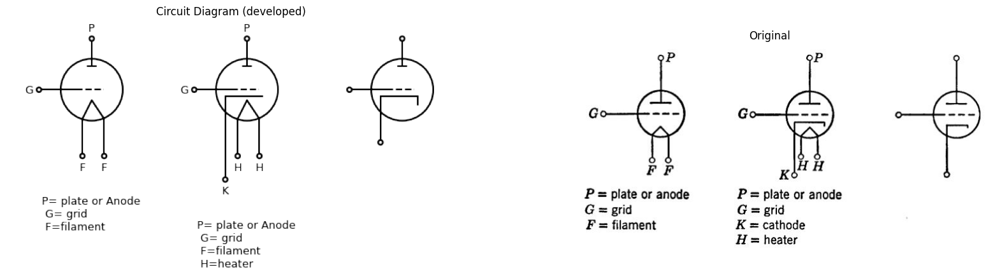

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw.segments import SegmentCircle
from schemdraw.elements import Element
class MyCircle(Element):
    def __init__(self, radius=1, **kwargs):
        super().__init__(**kwargs)
        self.segments.append(SegmentCircle((0, 0), radius))

from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d.add(MyCircle(radius=1))
d +=(l1:= elm.Line().left(d.unit*.4).at((-.5,0)).dot(open=True).label('G','left'))
d +=(l2:= elm.Line().right(d.unit*.3).at(l1.start).linestyle('--'))
d +=(l3:= elm.Line().right(d.unit*.1).at((-.15,.75)))
d +=(l4:= elm.Line().up(d.unit*.3).at((0,.75)).dot(open=True).label('P','right'))
d +=(l5:= elm.Line().down(d.unit*.4).at((-.3,-.94)).dot(open=True).label('F','left'))
d +=(l6:= elm.Line().down(d.unit*.4).at((.4,-.94)).dot(open=True).label('F','left'))
d +=(l7:= elm.Line().down(d.unit*.0004).at((0,-.34)))
d +=(l8:= elm.Line().down(d.unit*.4).endpoints(l5.start,l7.end))
d +=(l9:= elm.Line().down(d.unit*.4).endpoints(l6.start,l7.end))
d.add(MyCircle(radius=1).at((5,0)))
d +=(l10:= elm.Line().left(d.unit*.4).at((4.5,0)).dot(open=True).label('G','left'))
d +=(l11:= elm.Line().right(d.unit*.3).at(l10.start).linestyle('--'))
d +=(l12:= elm.Line().right(d.unit*.1).at((4.85,.75)))
d +=(l13:= elm.Line().up(d.unit*.3).at((5,.75)).dot(open=True).label('P','right'))
d +=(l14:= elm.Line().down(d.unit*.4).at((4.7,-.94)).dot(open=True).label('H','left'))
d +=(l15:= elm.Line().down(d.unit*.4).at((5.4,-.94)).dot(open=True).label('H','left'))
d +=(l16:= elm.Line().down(d.unit*.0004).at((5,-.34)))
d +=(l17:= elm.Line().down(d.unit*.4).endpoints(l14.start,l16.end))
d +=(l18:= elm.Line().down(d.unit*.4).endpoints(l15.start,l16.end))
d +=(l19:= elm.Line().left(d.unit*.4).at((5.5,-.2)))
d +=(l20:= elm.Line().down(d.unit*.9).dot(open=True).label('K','left'))
d.add(MyCircle(radius=1).at((10,0)))
d +=(l21:= elm.Line().left(d.unit*.4).at((9.5,0)).dot(open=True))
d +=(l22:= elm.Line().right(d.unit*.3).at(l21.start).linestyle('--'))
d +=(l23:= elm.Line().right(d.unit*.1).at((9.85,.75)))
d +=(l24:= elm.Line().up(d.unit*.3).at((10,.75)).dot(open=True))
d +=(l25:= elm.Line().left(d.unit*.4).at((10.5,-.2)))
d +=(l26:= elm.Line().down(d.unit*.5).dot(open=True))
d +=(l27:= elm.Line().down(d.unit*.1).at(l25.start))
d +=(l28:= elm.Line().right(d.unit*.1).at((-2,-4)).color('white').label('P= plate or Anode\n G= grid \n F=filament','right',color='black'))
d +=(l29:= elm.Line().right(d.unit*.1).at((3,-5)).color('white').label('P= plate or Anode\n G= grid \n F=filament\n H=heater','right',color='black'))
d.save('images/6-2a.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-2a.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-2.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


## Fig. 6.2. Triode circuit symbols.

in broadcast transmitters may be required to handle many kilowatts
of power.

A few of the more common electrode structures are shown in Fig. 6.1.
The cathode, grid, and anode may be parallel planes, as shown in (a), or
concentric cylinders, as in (b). Triodes may have a filamentary cathode,
as shown in (c). Elliptical cross sections are also used, as are various
hybrid combinations of simple geometrical shapes.

Circuit symbols commonly used to represent a vacuum triode are
shown in Fig, 6.2. The symbol for a triode using a heated filament as the
electron emitter is shown in (a). The symbol for a triode with an in-
directly heated cathode is shown in (b). For our purposes, the abbre-
viated symbol shown in (c) is most convenient. The heater is implied
but not shown, since the heater power merely maintains the cath-
ode at an operating temperature suitable for thermionic emission of
electrons.

# 6.3 Current Versus Voltage Relations


Conventional designations and reference directions for total electrode
currents and voltages are shown in Fig. 6.3(a). The triode is a three-
terminal circuit element, hence we can specify terminal behavior by
means of four variables:$ e_b,e_c,i_b,  and i_c$,. One commonly used functional
representation of triode terminal relations is given in (6). The graphs of
these functions, shown in (c), are static curves typical of the d-c or low-
frequency behavior of a vacuum triode, The qualitative form is in-
dependent of triode size or electrode geometry. The plot of 2. vs. é, is
commonly called the “grid family,’ and the plot of $i_b vs e_c$ is called the
“plate family.”

For fixed values of e, (zero or negative), the plate circuit conduction
$(ib VS. vb)$ is like that of a diode in series with a voltage source proportional
to e,. Thus, for a constant value of i, the voltage e, is nearly linearly
dependent on $e_c$, for $e_c$, less than zero. For $e_c$, greater than zero, the
variation of $e_b$, with e, is smaller and not nearly as constant. Each
line of the grid family also resembles a diode curve. The grid and cathode
constitute an auxiliary diode whose conduction is somewhat influenced
by the anode voltage $e_b$,. The influence of $e_b$, on $e_c$, is considerably less
than the influence of $e_c$, on $e_b$.

On the basis of the above consideration, we can postulate an ap
proximate model of the triode, as indicated in Fig. 6.3(d). The grid-to-
cathode circuit can be represented by a simple vacuum diode, and the
plate-to-cathode circuit by a vacuum diode in series with a source
proportional to $e_c$,. For $e_c$, less than zero, the proportionality factor u 1s
very nearly constant.

The simple piecewise-linear models shown in Fig. 6.4, together with
their graphical representations, are obtained by replacing the vacuum

Text(0.5, 1.0, 'Original')

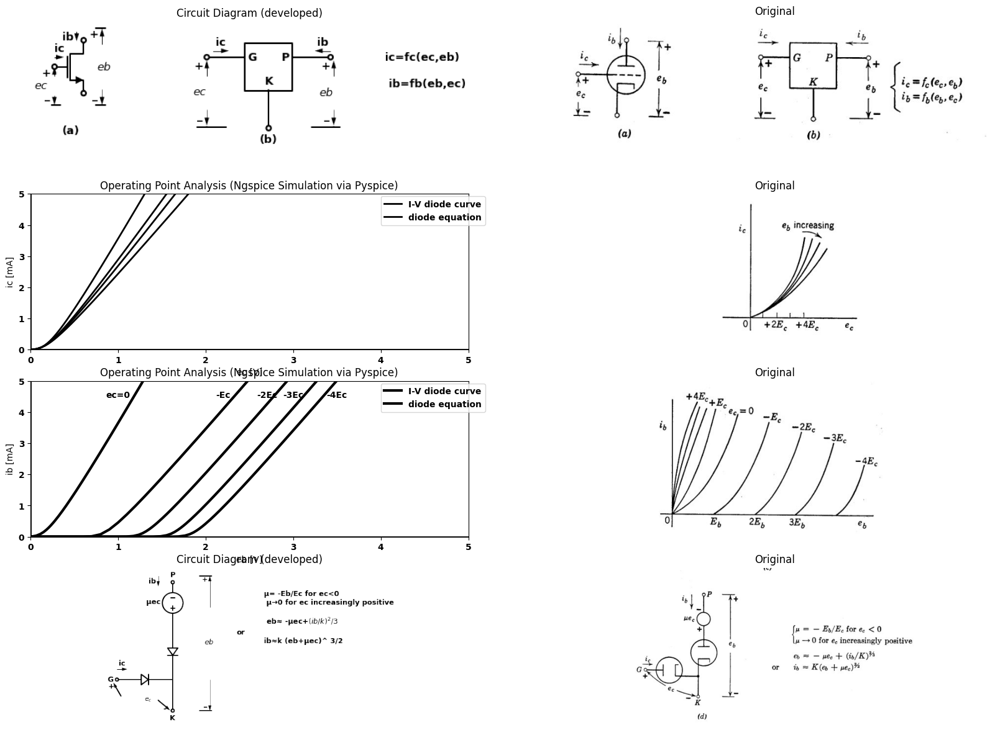

In [7]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at(M1.gate))
d +=(l2:= elm.Line().right(d.unit*.001).dot(open=True).at(M1.drain))
d +=(l3:= elm.Line().right(d.unit*.001).dot(open=True).at(M1.source))
d += elm.Arrow().down().length(.3).linewidth(1).color('black').label('ib'). at((.7,1.1))
d += elm.Arrow().right().length(.3).linewidth(1).color('black').label('ic'). at((0,0.3))
d += elm.Arrow().up().length(.3).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.3))
d += elm.Arrow().down().length(.3).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-.9))
d += elm.Arrow().up().length(.3).linewidth(0.6).color('white').label('$e{c}$', loc='start', color='black',ofst=0.3). at((0.1,-.4))
d +=(l4:= elm.Line().right(d.unit*.1).at((-.1,-1.2)))
d +=(l5:= elm.Line().right(d.unit*.1).at((1.3,-1.2)))
d +=(l6:= elm.Line().right(d.unit*.1).at((1.3,1.2)))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((1.5,.7))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((1.5,-.7))
d += elm.Arrow().up().length(.3).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((2.1,0.2))
d +=(l7:= elm.Line().right(d.unit*.01).at((.1,-2)).label('(a)','right', color='black').color('white'))
d += ( T := dsp.Box(w=1.5, h=1.5).anchor('W').fill('white').at((6,0)))
d +=(l7:= elm.Line().left(d.unit*.4).dot(open=True).at((6,0.3)).label('G','right'))
d +=(l8:= elm.Line().right(d.unit*.4).dot(open=True).at((7.5,0.3)).label('P','left'))
d +=(l9:= elm.Line().down(d.unit*.4).dot(open=True).at((6.75,-.73)).label('K','right').label('(b)','left'))
d += elm.Line().right(d.unit*.3).at((4.5,-1.9))
d += elm.Line().right(d.unit*.3).at((8.1,-1.9))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((4.8,-.3))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4.8,-1.35))
d += elm.Arrow().up().length(.3).linewidth(0.6).color('white').label('$e{c}$', loc='start', color='black',ofst=0.3). at((5.1,-0.6))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((8.8,-.3))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((8.8,-1.35))
d += elm.Arrow().up().length(.3).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((9.1,-.6))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('ic'). at((5,.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('ib'). at((8.7,.5))
d += elm.Line().right(d.unit*.1).at((10,-.1)).label('ic=fc(ec,eb)\n\n ib=fb(eb,ec)','right', color='black').color('white')
d.save('images/6-3a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-3a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-3a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 250@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 270@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2) 
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,0].set_xlim(0, 5)
axs[1,0].set_ylim(0, 5)
axs[1,0].set_xlabel('ec [V]')
axs[1,0].set_ylabel('ic [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-3b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2) 
axs[2,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[2,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[2,0].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[2,0].text( 2.2, 4.545, '-Ec', ha='center', va='center')
axs[2,0].text( 2.7, 4.545, '-2Ec', ha='center', va='center')
axs[2,0].text( 3, 4.545, '-3Ec', ha='center', va='center')
axs[2,0].text( 3.5, 4.545, '-4Ec', ha='center', va='center')
axs[2,0].set_xlim(0, 5)
axs[2,0].set_ylim(0, 5)
axs[2,0].set_xlabel('eb [V]')
axs[2,0].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-3c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).label('G','left'))
d +=( D1:=elm.Diode().right(d.unit*.9))
d +=(l2:= elm.Line().down(d.unit*.5).dot(open=True).label('K','left'))
d +=( D2:=elm.Diode().up(d.unit*.9).reverse().at(D1.end))
d += (E3 := elm.SourceV().up().length(2).label('μec','top').reverse().dot(open=True).label('P','right'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('ic'). at((0,.5))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib'). at((2,5))
d +=elm.Line().right(d.unit*.2).at((4,-1.5))
d +=elm.Line().right(d.unit*.2).at((4,5))
d += elm.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((4.5,3.5))
d += elm.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4.5,0))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((5,2))
d += elm.Arrow().length(.75).at((.2, -.8)).label('+', ofst=(.2,0.4)).theta(120)
d += elm.Arrow().length(.75).at((2, -1)).label('-', ofst=(0.2,-0.3)).theta(-40) 
d += elm.Gap().right().label('$e_{c}$',fontsize = 12).color('black').at((0,-.8))
d +=elm.Line().right(d.unit*.002).at((6,2)).label('or')
d +=elm.Line().right(d.unit*.002).at((7,3)).label('μ= -Eb/Ec for ec<0 \n μ→0 for ec increasingly positive\n\n eb≈ -μec+$(ib/k)^2/3$\n\nib≈k (eb+μec)^ 3/2','right')
d.save('images/6-3d1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-3d1.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-3d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_mosfet_curve(Vth=1.0, Kn=2e-3):
    Vgs = np.linspace(0, 3, 300)
    Id = Kn * np.maximum(Vgs - Vth, 0) ** 2

    plt.figure(figsize=(10,6))
    plt.plot(Vgs, Id*1e3, color='black', linewidth=3, label=r'$I_D$ vs $V_{GS}$')
    plt.xlabel('Gate-Source Voltage $V_{GS}$ (V)', fontsize=16)
    plt.ylabel('Drain Current $I_D$ (mA)', fontsize=16)
    plt.title('Common Source MOSFET Output Current', fontsize=16)
    plt.legend(fontsize=14)
    #plt.grid(True)
    plt.ylim(bottom=0)
    plt.show()

# Create interactive sliders for Vth and Kn
interact(
    plot_mosfet_curve,
    Vgs=FloatSlider(value=1.0, min=0.5, max=2.5, step=0.05, description='vgs (V)'),
    Kn=FloatSlider(value=2e-3, min=0.5e-3, max=5e-3, step=1e-3, description='Kn (A/V²)')
)


interactive(children=(FloatSlider(value=1.0, description='Vth', max=3.0, min=-1.0), FloatSlider(value=0.002, d…

<function __main__.plot_mosfet_curve(Vth=1.0, Kn=0.002)>

## Fig. 6.3. Qualitative triode curves.


diodes by ideal rectifiers or piecewise-linear diodes. These curves and
circuit models are basically the same as the piecewise-linear transistor
curves and models, discussed in the preceding chapter.

Before proceeding with a more quantitative discussion of triode models
and circuits, let us examine the physical basis for the current-versus-
voltage relations. As we shall see in the succeeding articles, triode
behavior can be explained by an extension of the results obtained in
Chapter 2 for conduction in a vacuum diode.

Text(0.5, 1.0, 'Original')

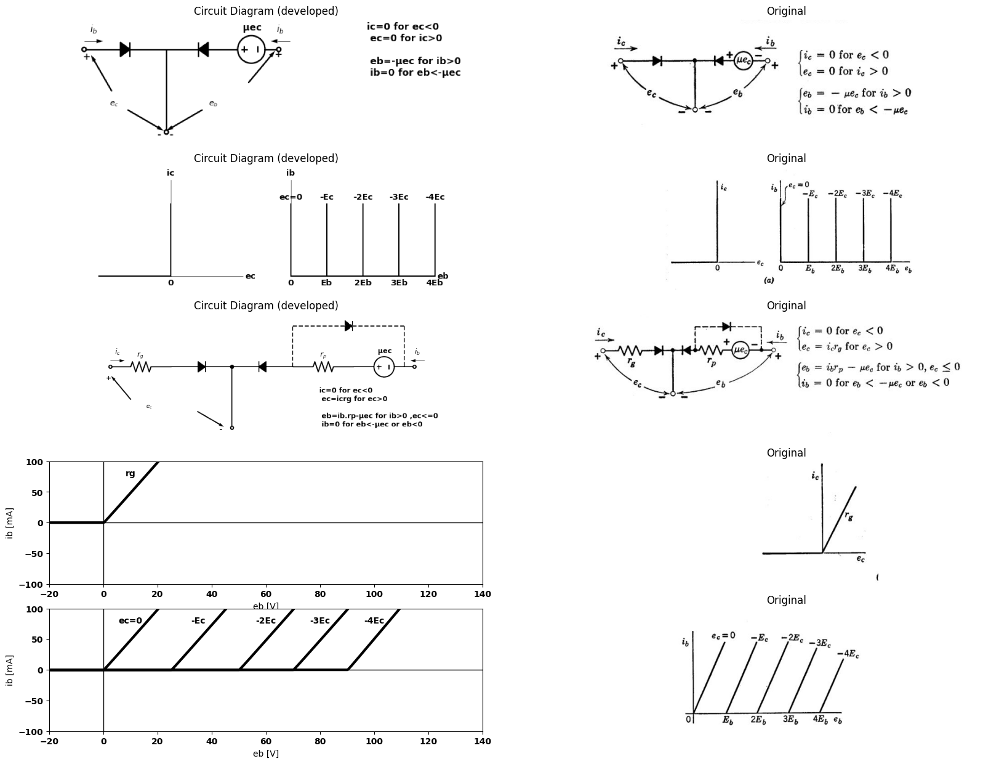

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(20, 15))
d = schemdraw.Drawing()
D1 = d.add(e.Diode(fill=True).right().idot(open=True))
l1 = d.add(e.Line().down().dot(open=True))
l2 = d.add(e.Line(l=0.6).right().at(l1.start))
D2 = d.add(e.Diode(l=1.5,fill=True).reverse().right().at(l2.end))
d += (E1 := elm.SourceV().right().length(2).label('μec','top').reverse().dot(open=True))
d += e.Gap().right().color('black').at((1.6,-3.2))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('$i_b$', loc='top', color='black',ofst=0.2).at((7.5,0.3))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('$i_b$', loc='top', color='black',ofst=0.2).at((0,0.3))
d += e.Arrow().length(1.5).at((6, -1.2)).label('+', ofst=(0.7,-0.4)).theta(50) 
d += e.Arrow().length(1.5).at((4.3, -2.2)).label('-', ofst=(0.7,0.4)).theta(-150) 
d += e.Arrow().length(1.5).at((1.6, -2.2)).label('-', ofst=(0.7,-0.4)).theta(-30) 
d += e.Arrow().length(1.5).at((1, -1.5)).label('+', ofst=(0.7,0.4)).theta(120) 
d += e.Gap().right().label('$e_{c}$',fontsize = 12).color('black').at((-0.4,-1.8))
d += e.Gap().right().label('$e_{b}$',fontsize = 12).color('black').at((3.2,-1.8))
l1 = d.add(e.Line().right().length(.2).at((10,0)).color('white').label('ic=0 for ec<0 \n ec=0 for ic>0\n\n eb=-μec for ib>0 \n ib=0 for eb<-μec','right',color='black'))
d.save('images/6-4a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-4a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-4a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(6).linewidth(0.8).label('ec','right'))
l2 = d.add(e.Line().up().length(4).linewidth(0.8).at((3,0)).label('ic','right').label('0','left'))
l3 = d.add(e.Line().right().length(3).linewidth(2).at(l1.start))
l4 = d.add(e.Line().up().length(3).linewidth(2))
l5 = d.add(e.Line().right().length(6).linewidth(0.8).label('eb','right').at((8,0)))
l6 = d.add(e.Line().up().length(4).linewidth(0.8).at((8,0)).label('ib','right').label('0','left'))
l7 = d.add(e.Line().up().length(3).linewidth(2).at((8,0)).label('ec=0','right'))
l8 = d.add(e.Line().right().length(1.5).linewidth(2).at(l7.start))
l9 = d.add(e.Line().up().length(3).linewidth(2).label('-Ec','right').label('Eb','left'))
l10 = d.add(e.Line().right().length(1.5).linewidth(2).at(l9.start))
l11 = d.add(e.Line().up().length(3).linewidth(2).label('-2Ec','right').label('2Eb','left'))
l12 = d.add(e.Line().right().length(1.5).linewidth(2).at(l11.start))
l13 = d.add(e.Line().up().length(3).linewidth(2).label('-3Ec','right').label('3Eb','left'))
l14 = d.add(e.Line().right().length(1.5).linewidth(2).at(l13.start))
l15 = d.add(e.Line().up().length(3).linewidth(2).label('-4Ec','right').label('4Eb','left'))

d.save('images/6-4b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-4b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-4b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
R1 = d.add(e.Resistor().right().idot(open=True).label('$r_g$','top'))
D1 = d.add(e.Diode(fill=True).right().dot())
D2 = d.add(e.Diode(fill=True).right().reverse())
R2 = d.add(e.Resistor().right().label('$r_p$','top'))
d += (E1 := elm.SourceV().right().length(3).label('μec','top').reverse().dot(open=True))
l1 = d.add(e.Line().up().length(2).linewidth(2).at(D2.end).linestyle('--'))
D3 = d.add(e.Diode(fill=True).right().linestyle('--').length(5.5))
l2 = d.add(e.Line().down().length(2).linewidth(2).linestyle('--'))
l3 = d.add(e.Line().down().length(3).linewidth(2).at(D1.end).dot(open=True))
d += e.Arrow().length(1.5).at((1, -1.6)).label('+', ofst=(0.7,0.4)).theta(130) 
d += e.Arrow().length(1.5).at((4.3, -2.2)).label('-', ofst=(0.7,-0.4)).theta(-30) 
d += e.Gap().right().label('$e_{c}$',fontsize = 12).color('black').at((0.4,-1.8))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('$i_b$', loc='top', color='black',ofst=0.2).at((15.5,0.3))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('$i_c$', loc='top', color='black',ofst=0.2).at((0,0.3))
l1 = d.add(e.Line().right().length(.2).at((10,-2)).color('white').label('ic=0 for ec<0 \n ec=icrg for ec>0\n\n eb=ib.rp-μec for ib>0 ,ec<=0\n ib=0 for eb<-μec or eb<0','right',color='black'))
d.save('images/6-4c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-4c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-4c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3)
axs[3,0].text( 10,80, 'rg', ha='center', va='center')
axs[3,0].set_xlim(-20, 140)
axs[3,0].set_xlabel('eb [V]')
axs[3,0].set_ylabel('ib [mA]')
axs[3,0].set_ylim(-100, 100)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-4d1.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
rcParams['font.weight'] = 'bold'
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 25@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[4,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[4,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='-')
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 50@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[4,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='-')
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 70@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[4,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='-')
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 90@u_Ohm)
circuit.V('i', '3', circuit.gnd, 90@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 200, 0.1))
axs[4,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='-')
axs[4,0].set_xlim(-20, 140)
axs[4,0].set_xlabel('eb [V]')
axs[4,0].set_ylabel('ib [mA]')
axs[4,0].set_ylim(-100, 100)
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
axs[4,0].text( 10,80, 'ec=0', ha='center', va='center')
axs[4,0].text( 35, 80, '-Ec', ha='center', va='center')
axs[4,0].text(60,80, '-2Ec', ha='center', va='center')
axs[4,0].text(80,80, '-3Ec', ha='center', va='center')
axs[4,0].text(100,80, '-4Ec', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-4e.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

In [2]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(E=widgets.IntSlider(min=0, max=50, step=5, value=20))
def response(E=20):
    circuit = Circuit('Diode')
    circuit.model('BAV21','D' ,IS = 4@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_Ohm ,TT = 3.48E-9)
    Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
    circuit.D(1, '1','2' , model = 'BAV21')
    circuit.V(1, '2',circuit.gnd , E@u_V)
    circuit.I(1, '1','2' , 10@u_mA)

    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vth=slice(-100, 100, 0.1))

    # Plot for R1
    plt.plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.tight_layout()
    plt.show()

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=20, description='E', max=50, step=5), Output()), _dom_classes=('widget-i…

## Fig. 6.4. Piecewise-linear triode models.


As mentioned above, the applied grid voltage affects the electric
potential distribution in the interelectrode space and thereby influences
the flow of electrons from cathode to plate. For a more detailed explana
tion of this effect, let us first examine the electric potential distribution
within a “cold” triode with the heater disconnected so that the cathode
emits no electrons. The cold tube, having no interelectrode space
charge, is essentially a three-electrode capacitor in which the inter-

Text(0.5, 1.0, 'Original')

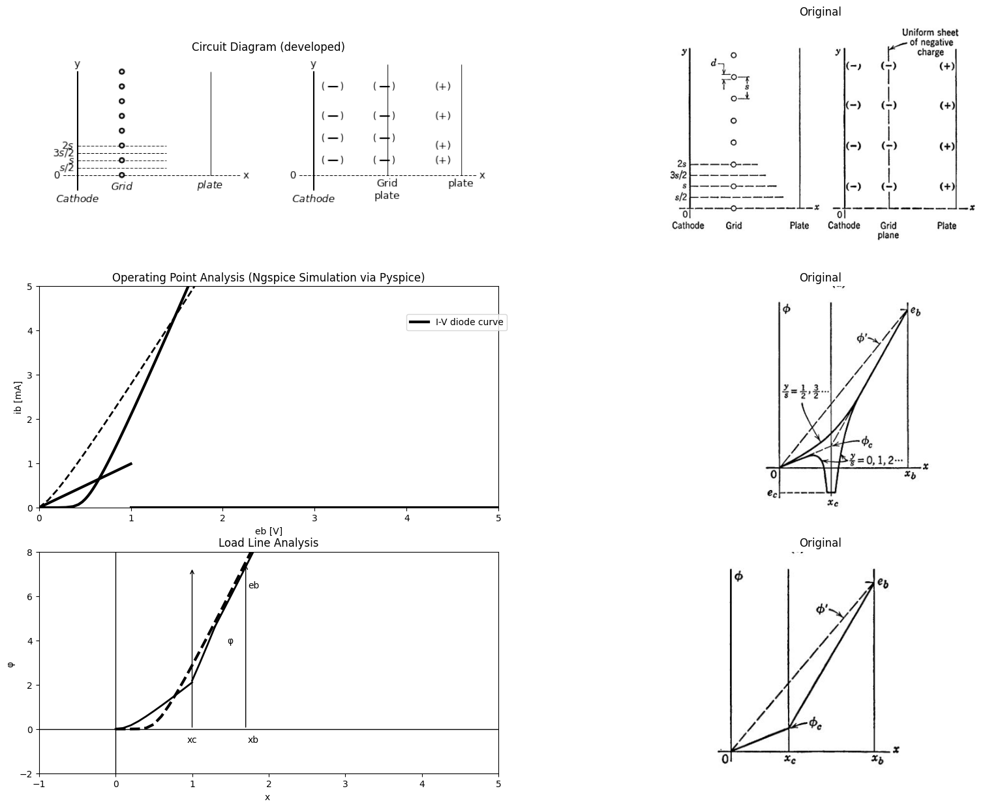

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
l1 = d.add(elm.Line().right().length(6).linewidth(1).label('x','right').label('0','left').linestyle('--'))
l2 = d.add(elm.Line().up().length(4).linewidth(2).at((.5,-.5)).label('y','right').label('$Cathode$','left'))
l3 = d.add(elm.Line().up().length(3.5).linewidth(1).at((5,0)).label('$plate$','left'))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,0)).label('$Grid$','bottom'))
d +=(l2:= elm.Line().right(d.unit*.001).dot(open=True).at((2,.5)))
d +=(l3:= elm.Line().right(d.unit*.001).dot(open=True).at((2,1)))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,1.5)))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,2)))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,2.5)))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,3)))
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).at((2,3.5)))
d +=(l2:= elm.Line().right(d.unit*1).at((0.5,0.25)).linestyle('--').linewidth(1).label('$s/2$','left'))
d +=(l2:= elm.Line().right(d.unit*1).at((0.5,0.5)).linestyle('--').linewidth(1).label('$s$','left'))
d +=(l2:= elm.Line().right(d.unit*1).at((0.5,0.75)).linestyle('--').linewidth(1).label('$3s/2$','left'))
d +=(l2:= elm.Line().right(d.unit*1).at((0.5,1)).linestyle('--').linewidth(1).label('$2s$','left'))
l11 = d.add(elm.Line().right().length(6).linewidth(1).label('x','right').label('0','left').linestyle('--').at((8,0)))
l12 = d.add(elm.Line().up().length(4).linewidth(2).at((8.5,-.5)).label('y','right').label('$Cathode$','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((9,.5)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((9,1.25)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((9,2)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((9,3)).label(')','right').label('(','left'))
d +=(l1:= elm.Line().up(d.unit*1.25).at((11,0)).label('Grid\nplate','left').linewidth(1))
d +=(l21:= elm.Line().right(d.unit*.1).at((10.75,.5)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((10.75,1.25)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((10.75,2)).label(')','right').label('(','left'))
d +=(l21:= elm.Line().right(d.unit*.1).at((10.75,3)).label(')','right').label('(','left'))
d +=(l1:= elm.Line().up(d.unit*1.25).at((13.5,0)).label('plate','left').linewidth(1))
d +=(l21:= elm.Line().right(d.unit*.001).at((12.5,.5)).label('(+)','right',color='black').color('white'))
d +=(l21:= elm.Line().right(d.unit*.001).at((12.5,1)).label('(+)','right',color='black').color('white'))
d +=(l21:= elm.Line().right(d.unit*.001).at((12.5,2)).label('(+)','right',color='black').color('white'))
d +=(l21:= elm.Line().right(d.unit*.001).at((12.5,3)).color('white').label('(+)','right',color='black'))
d.save('images/6-5a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-5a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-5a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')

# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 200@u_Ohm)
circuit.V('i', '3', circuit.gnd,0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')

# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 200@u_mA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 1000@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th1', '11', circuit.gnd, 0@u_V)
circuit.D(1, '12', '13' , model = 'BAV21')
circuit.R(1, '11', '12', 10@u_Ohm)
circuit.V('i1', '13', circuit.gnd,0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth1=slice(-1, 1, 0.1))
axs[1,0].plot(analysis['11'],u_mA(-analysis.Vth1), 'black', linewidth=3)

# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 200@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 10@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th11', '111', circuit.gnd, 0@u_V)
circuit.D(1, '112', '13' , model = 'BAV21')
circuit.R(1, '111', '112', 1@u_Ohm)
circuit.V('i11', '113', circuit.gnd,1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth11=slice(1, 100, 0.1))
axs[1,0].plot(analysis['111'],u_mA(-analysis.Vth11), 'black', linewidth=3)

axs[1,0].set_xlim(0, 5)
axs[1,0].set_ylim(0, 5)
axs[1,0].set_xlabel('eb [V]')
axs[1,0].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-5b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '2', circuit.gnd, 350@u_Ohm)
circuit.D(1, '1','2' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 1, 0.1))
axs[2,0].plot(analysis['1'], u_mA(-analysis.Vi),'black',linestyle='-',linewidth=2)
circuit = Circuit('thev')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(2, '2', circuit.gnd, 230@u_Ohm)
circuit.D(2, '1','2' , model = 'BAV21')
circuit.R(1, '2', '3', 200@u_Ohm)
circuit.D(3, '1','2' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd ,1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(1, 1.3, 0.1))
axs[2,0].plot(analysis['1'], u_mA(-analysis.Vi),'black',linestyle='-',linewidth=2)
#2
circuit = Circuit('thev')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS =120@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(2, '2', circuit.gnd, 130@u_Ohm)
circuit.D(2, '1','2' , model = 'BAV21')
circuit.R(1, '2', '3', 210@u_Ohm)
circuit.D(3, '1','2' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd ,1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(1.3, 2.6, 0.1))
axs[2,0].plot(analysis['1'], u_mA(-analysis.Vi),'black',linestyle='-',linewidth=2)
#3
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .7@u_V ,CJO = 7.048E-13 ,RS = 140@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_Ohm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linestyle='--',linewidth=3)

axs[2,0].annotate('', xy=(1.7, 7.5), xytext=(1.7,0), arrowprops=dict(arrowstyle='->'))
axs[2,0].annotate('', xy=(1, 7.3), xytext=(1,0), arrowprops=dict(arrowstyle='->'))
axs[2,0].text(1.8, 6.5, 'eb', ha='center', va='center')
axs[2,0].text(1.8, -.5, 'xb', ha='center', va='center')
axs[2,0].text(1, -.5, 'xc', ha='center', va='center')
axs[2,0].set_title('Load Line Analysis')
axs[2,0].text(1.5, 4, 'φ', ha='center', va='center')
axs[2,0].set_xlim(-1, 5)
axs[2,0].set_ylim(-2, 8)
axs[2,0].set_xlabel('x ')
axs[2,0].set_ylabel('φ ')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-5c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig. 6.5. Potential distribution in a cold-cathode planar triode.

electrode electric fields are governed by linear electrostatic laws. The
applied electrode voltages determine the interelectrode fields of the cold
tube, from which we can deduce something about the amount of current
which flows when the cathode is heated. For simplicity, we shall choose
parallel-plane geometry with electrodes of infinite extent. This is an
idealization of the parallel-plane triode illustrated in Fig. 6.1(a). The
anode and cathode of our structure are assumed to be metallic planes,
and the grid structure consists of parallel rods or wires, as shown in
Fig. 6.5(a). The grid wires are spaced a distance s apart and have a
diameter d.

Text(0.5, 1.0, 'Original')

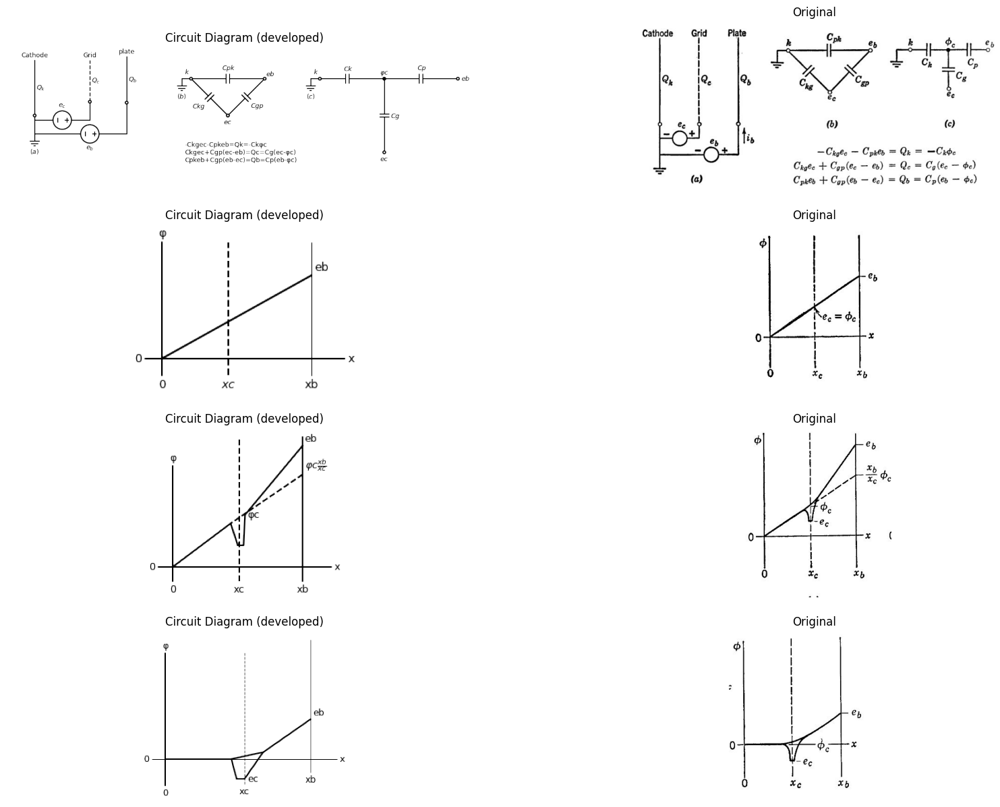

In [9]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
l1 = d.add(e.Line().up().length(1).linewidth(2).dot(open=True))
l2 = d.add(e.Line().up().length(3).linewidth(2).label('Cathode','right').label('$Q_k$','bottom'))
d += (E1 := e.SourceV().right().length(3).label('$e_c$','top').at((0,.75)))
l3 = d.add(e.Line().up().length(1).linewidth(2).dot(open=True))
l4 = d.add(e.Line().up().length(2.25).linewidth(2).linestyle('--').label('Grid','right').label('$Q_c$','bottom'))
l5 = d.add(e.Line().right().length(1).linewidth(2).at((0,0)))
d += (E1 := e.SourceV().right().length(4).label('$e_b$','bottom'))
l6 = d.add(e.Line().up().length(1.7).linewidth(2).dot(open=True))
l7 = d.add(e.Line().up().length(2.5).linewidth(2).label('plate','right').label('$Q_b$','bottom'))
d += e.Ground().at(l1.start).label('$(a)$','bottom')
l8 = d.add(e.Line().right().length(.5).linewidth(2).dot(open=True).at((8,3)).label('$k$','top'))
C1 = d.add(e.Capacitor().right().length(4).linewidth(2).dot(open=True).label('$C{pk}$','top'))
l9 = d.add(e.Line().right().length(.0005).linewidth(2).dot(open=True).at((10.5,1)).label('$e{c}$','bottom'))
C2 = d.add(e.Capacitor().right().length(4).linewidth(2).dot(open=True).label('$C{kg}$','bottom').endpoints(l8.end,l9.end))
C3 = d.add(e.Capacitor().right().length(4).linewidth(2).dot(open=True).label('$C{gp}$','bottom').endpoints(C1.end,l9.end).label('$e{b}$','right'))
d += e.Ground().at(l8.start).label('$(b)$','bottom')
l10 = d.add(e.Line().right().length(.5).linewidth(2).dot(open=True).at((15,3)).label('$k$','top'))
d += e.Ground().at(l10.start).label('$(c)$','bottom')
C4 = d.add(e.Capacitor().right().length(4).linewidth(2).dot().label('$C{k}$','top'))
C5 = d.add(e.Capacitor().right().length(4).linewidth(2).dot(open=True).label('$C{p}$','top').label('$e{b}$','right'))
C6 = d.add(e.Capacitor().down().length(4).linewidth(2).dot(open=True).label('$C{g}$','bottom').at(C5.start).label('$e{c}$','left').label('$φ{c}$','right'))
l11 = d.add(e.Line().right().length(.05).linewidth(2).at((8,-1)).color('white').label('-Ckgec-Cpkeb=Qk=-Ckφc\nCkgec+Cgp(ec-eb)=Qc=Cg(ec-φc)\nCpkeb+Cgp(eb-ec)=Qb=Cp(eb-φc)','right',color='black'))
d.save('images/6-6a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-6a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-6a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(6).linewidth(2).label('x','right').label('0','left').linestyle('-'))
l2 = d.add(e.Line().up().length(4).linewidth(2).at((.5,-.5)).label('φ','right').label('$0$','left'))
l3 = d.add(e.Line().up().length(3).linewidth(1).at((5,-.5)).label('xb','left'))
l4 = d.add(e.Line().up().length(.000003).linewidth(2).at((.5,0)))
l5 = d.add(e.Line().up().length(3).linewidth(2).endpoints(l4.end,l3.end).label('eb','right'))
l6 = d.add(e.Line().up().length(1).linewidth(1).at(l3.end))
l7 = d.add(e.Line().up().length(4).linewidth(2).at((2.5,-.5)).linestyle('--').label('$xc$','left'))
d.save('images/6-6b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-6b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-6b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(6).linewidth(2).label('x','right').label('0','left').linestyle('-'))
l2 = d.add(e.Line().up().length(4).linewidth(2).at((.5,-.5)).label('φ','right').label('$0$','left'))
l3= d.add(e.Line().right().length(0.002).linewidth(2).at((0.5,0)))
l4= d.add(e.Line().right().length(0.002).linewidth(2).at((2.5,1.5)))
l5= d.add(e.Line().right().length(0.002).linewidth(2).at((5,3.2)))
l6= d.add(e.Line().right().length(2).linewidth(2).endpoints(l3.end,l4.end))
l7= d.add(e.Line().right().length(2).linewidth(2).endpoints(l5.end,l4.end).linestyle('--').label(r'$φc\frac{xb}{xc}$','right'))
l8= d.add(e.Line().right().length(0.002).linewidth(2).at((5,4.2)))
l88= d.add(e.Line().right().length(0.002).linewidth(2).at((3,1.8)).color('black').label('φc','right'))
    #l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l8.end,l4.end))
l10= d.add(e.Line().right().length(0.2).linewidth(2).at((2.75,.75)))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l10.start,l4.end))
l10= d.add(e.Line().right().length(2).linewidth(2).endpoints(l10.end,l88.end))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l88.start,l8.end).label('eb','right'))
l11= d.add(e.Line().up().length(5).linewidth(2).at((5,-.5)).label('xb','left'))
l11= d.add(e.Line().up().length(5).linewidth(2).at((2.8,-.5)).label('xc','left').linestyle('--'))
d.save('images/6-6c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-6c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-6c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(7).linewidth(1).label('x','right').label('0','left').linestyle('-'))
l2 = d.add(e.Line().up().length(5).linewidth(2).at((.5,-1)).label('φ','right').label('$0$','left'))
l3 = d.add(e.Line().right().length(2.5).linewidth(2).at((.5,0)))
l4 = d.add(e.Line().right().length(.3).linewidth(2).at((3.2,-.75)).label('ec','right'))
l5 = d.add(e.Line().right().length(.0005).linewidth(2).at((4.2,0.25)))
l6 = d.add(e.Line().right().length(.00005).linewidth(2).at((6,1.5)))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l3.end,l4.start))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l5.end,l4.end))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l3.end,l5.start))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l5.end,l6.start).label('eb','right'))
l10 = d.add(e.Line().up().length(5).linewidth(1).at((6,-.5)).label('xb','left'))
l10 = d.add(e.Line().up().length(5).linewidth(1).at((3.5,-.95)).label('xc','left').linestyle('--'))
d.save('images/6-6d1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-6d1.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-6d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 6.6. The electrostatic model of the cold triode.


The grid wires are fixed at a potential e, with respect to the cathode,
and the anode is fixed at a potential e, with respect to the cathode. In
the absence of the grid wires, the potential varies linearly between
cathode and anode, as shown by the dotted line ¢’ in Fig. 6.5(b). With
the grid wires present, the potential $φ(x,y)$ drops sharply in the vicinity
of each wire $(y/s = 0, 1, 2, ... )$, as shown in Fig. 6.5(b), and negative
induced charge appears on the grid wires. Midway between grid wires
$(y/s = 1/2, 3/2, 5/2,...)$, the potential curve is relatively smooth. At
distance greater than s to the left or right of the grid plane, the potential
approaches a curve corresponding to a uniform planar distribution of
grid charge. A sketch indicating a uniform sheet of charge in the grid
plane is shown in Fig. 6.5(c), and the corresponding distribution of
potential is shown in (d).

When voltages e, and e, are applied to the parallel-plane cold triode,
Fig. 6.6(a), induced charges Q;, Q., and Q, appear on the electrodes.
We assume here that each electrode has unit area and that the spacing
is small, so that fringing at the edges of the electrodes is a negligible
effect. Since the charge-voltage relationships are linear, we can always
represent the cold tube as the system of three capacitors shown in
Fig. 6.6(6). This is the general circuit model for any configuration of
three perfect conductors in free space; one grounded and the other
two driven by d-c voltages.

A three-terminal ‘‘mesh”’ or “delta’”’ network of three capacitances is
ulways replaceable by an equivalent ‘star’ configuration, as indicated
in Fig. 6.6(c). The pertinent relationships are

$C{gp} = CgCp/(C_g + C_p + C_k) (6.1)$

and, by symmetry, two similar forms for $C{pk}$, and $Ckg$,. These relation-
ships can be deduced from the charge-voltage equations given in Fig.
6.6. Thus the cold triode can be represented by the circuit model in
Fig. 6.6(c). We must now identify the potential $φ_c$. appearing in the
circuit model and relate this potential to the electric field at the cathode
to deduce the amount of cathode current which will flow when the heater
is reconnected.

Assume, first, that $Q_c$ is zero. With no charge on the grid, the grid
becomes “‘electrically transparent’’ and the potential curve has the same
slope throughout the cathode-to-plate region as indicated in Fig. 6.6(d).
Hence $e_c/x_c = e_b/x_b$. By inspection of the circuit model, we see that $Q_c$
equal to zero implies that $e_c$, is equal to$φ_c$, and this identifies $φ_c$, in
Fig. 6.6(d). Now let us decrease $e_c$ exactly one volt and, at the same
time, raise e, just enough to keep $φ_c$, unchanged, as shown in Fig. 6.6(e).
This particular increase in $φ_c$, we shall define as yp, the electrostatic ampli
fication factor or screening factor of the triode. By inspection of the
circuit model, Fig. 6.6(c), we see that

$μ=C_g/C_p (6.2)$

Moreover, it follows from the star-mesh relationships that

$C_g/C_p = C{gk}/C{pk} (6.3)$

Hence

$μ= C{gk}/C {pk} (6.4)$

Finally, from the above definition of $μ$ and from Fig. 6.6(e)

$e_b — (x{b}/x{c})φ_c = μ(φ_c — e_c) (6.5)$

so that

$φ_c = (e_b + μe_c) /[ μ+ (x_b/x_c)] (6.6)$

Figure 6.6(f) offers a slightly different, but equivalent, interpretation
of the triode parameter μ. We can say that μ is the plate voltage re
quired to produce zero electric field at the cathode when the grid is one
volt negative. It is apparent from this interpretation that μ remains
unchanged if we move the cathode to a different location, keeping the
grid and plate fixed. In other words, μ depends upon the grid-to-plate
separation $x_b — x_c$, and upon the grid-wire diameter d and spacing $s$,
but does not depend upon the grid-to-cathode separation. The calcula
tion of μ from $(x_b - x_c)$, $d$, and$ s$ is a problem in electrostatics which, for
certain geometries, is often very conveniently solved by conformal
mapping methods.

# 6.5 The Thermionic Triode

When the cathode is heated to operating temperature, thermionic
emission provides large numbers of free electrons in the space between
cathode and anode. As in the case of the vacuum diode, the anode
current of a triode in normal operation is limited by space charge rather
than by temperature saturation. The space charge due to the cloud of
electrons in the interelectrode space modifies the potential distribution
that exists for the cold-cathode condition.

A qualitative sketch of potential distribution in a hot triode is shown
in Fig. 6.7(a). The relative magnitude of $φ_c$, and the grid-to-cathode
spacing $x_c$, have both been exaggerated in order to show the curvature
of the potential distribution in this region. The small sharp potential
dip just outside the cathode is attributable to initial emission velocities.
The potential minimum normally occurs very close to the actual cathode
and is only a few volts below cathode potential. This minimum is often
called a virtual cathode. Since most electrons reach the potential minimum
 with relatively low velocity, the effect is like that of a slightly
negative cathode located at the potential minimum and emitting zero
velocity electrons. For this discussion we shall assume that the location
and potential of the virtual cathode coincide with those of the actual
cathode.

Under the usual operating conditions, $e_b$ is large and positive, whereas
$e_c$. is small and negative, and the current is space-charge limited. Elec
trons are subject to a large acceleration in the grid-plate region because
of the large positive value of $e_b$,. They arrive at the anode with a velocity

$v_b$, determined by equating kinetic energy$ (\frac {1}{2}mv_b^2)$ to potential energy
$(qe_b)$. The current density is the product of the electronic charge, the
electron density and the electron velocity. A given anode current
therefore produces little space charge in regions where velocity is high.
Thus the potential curve near the anode is approximately a straight
line, as it was for the cold (space-charge-free) triode.

Text(0.5, 1.0, 'Original')

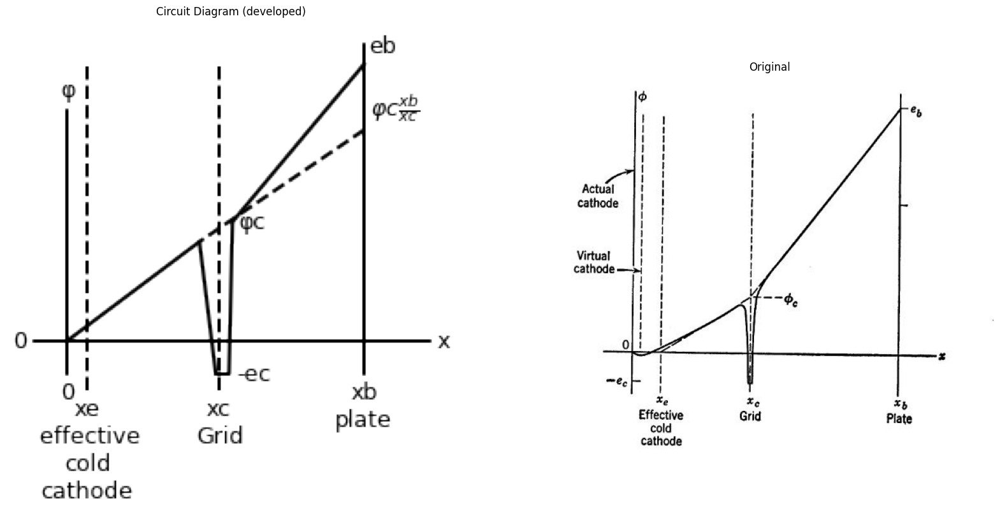

In [13]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(6).linewidth(2).label('x','right').label('0','left').linestyle('-'))
l2 = d.add(e.Line().up().length(4).linewidth(2).at((.5,-.5)).label('φ','right').label('$0$','left'))
l3= d.add(e.Line().right().length(0.002).linewidth(2).at((0.5,0)))
l4= d.add(e.Line().right().length(0.002).linewidth(2).at((2.5,1.5)))
l5= d.add(e.Line().right().length(0.002).linewidth(2).at((5,3.2)))
l6= d.add(e.Line().right().length(2).linewidth(2).endpoints(l3.end,l4.end))
l7= d.add(e.Line().right().length(2).linewidth(2).endpoints(l5.end,l4.end).linestyle('--').label(r'$φc\frac{xb}{xc}$','right'))
l8= d.add(e.Line().right().length(0.002).linewidth(2).at((5,4.2)))
l88= d.add(e.Line().right().length(0.002).linewidth(2).at((3,1.8)).color('black').label('φc','right'))
    
l10= d.add(e.Line().right().length(0.2).linewidth(2).at((2.75,-.5)).label('-ec','right'))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l10.start,l4.end))
l10= d.add(e.Line().right().length(2).linewidth(2).endpoints(l10.end,l88.end))
l9= d.add(e.Line().right().length(2).linewidth(2).endpoints(l88.start,l8.end).label('eb','right'))
l11= d.add(e.Line().up().length(5).linewidth(2).at((5,-.5)).label('xb\nplate','left'))
l11= d.add(e.Line().up().length(5).linewidth(2).at((2.8,-.75)).label('xc\nGrid','left').linestyle('--'))
l11= d.add(e.Line().up().length(5).linewidth(2).at((.8,-.75)).label('xe\n effective\ncold\ncathode','left').linestyle('--'))
d.save('images/6-7a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-7a1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/67.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(b) $φ_c = \frac {e_b+ μe_c}{[\frac {x_b -x_e}{x_c - x_e}]+μ}$


(c)  $i_b = K(e_b +μe_c+k )^\frac {3}{2}$

## Fig. 6.7. Potential distribution in a triode with heated cathode

Near the heated cathode, the electron velocities are small and space
charge is appreciable. The space charge produces curvature in the
potential distribution as in the space-charge-limited diode. For the
calculation of potentials farther to the right, the cloud of space charge
near the cathode can be represented by a concentrated sheet of charge
located at some point xb,, as indicated in Fig. 6.7(a). In other words, a
heated cathode can be replaced by a cold cathode located closer to the
grid without altering the potential distribution in the grid-plate region
where space charge is negligible. For plane-parallel geometry, the
potential φ in a hot space-charge-limited triode varies approximately as
the four-thirds power of the distance from the cathode. (This is a con-
sequence of the plane-parallel-diode law. Since the current density is
independent of x, we have $φ^\frac {3}{2}$ proportional to $x^2$, so that φ is proportional
$x^ \frac {4}{3}$) It follows that $x_e =x_c/4$ Hence the equation for $φ_c$, given in the
preceding article applies to the triode with heated cathode, provided $x_b$,
and $x_c$, are each decreased by an amount $x_e$, as indicated in Fig. 6.7(b).

The region between the cathode and grid of the triode forms a diode
whose anode voltage is the effective grid-plane potential $φ_c$. Thus the
cathode current $i_k$, of the triode is proportional to the three-halves power
of $(φ_c + φ_0)$, where $φ_0$ is a correction voltage accounting for the small
initial-velocity potential dip, and also for contact-potential differences
between the electrodes. For zero grid current ($e_c$ negative) we have
$i_b$, equal to $i_k$ so that anode current $i_k$ is proportional to $(φ_c + φ_0)^ \frac{3}{2}$.
Since $φ_c$  is proportional to $e_b + μe_c$, as indicated in Fig. 6.7(b) the
anode current 7, can be expressed by the relation given in Fig. 6.7(c),
where K, k, and y are constants of the tube. This relation holds for any
triode geometry (parallel-plane, cylindrical, etc.), provided (1) the grid
current is negligible, (2) the anode current is space-charge limited,
(3) the grid-to-plate space charge is negligible, and (4) the grid-wire
spacing is uniform and small compared with interelectrode spacing.
The quantity k may amount to several volts, since it includes a grid-
correction voltage multiplied by ». However, a satisfactory approxima-
tion is usually obtainable without including k, so that

$i_b = K (e_b + μe_c)^ \frac{3}{2} (6.7)$

# 6.6 Plate-Current Curves for a Typical Triode


The relation for plate current given in Fig. 6.7(c) confirms the plate-
circuit model postulated in Fig. 6.3(d). For a fixed value of grid voltage
$e_c$, the plate current varies as in a biased vacuum diode. The plot
given in Fig. 6.8(a) shows this relation for several values of $e_c$. Note
that the curves are spaced a distance $μE$ along the plate-voltage axis,
where $E$ is the grid-voltage increment. On this plot the correction
voltage K (for initial velocities and contact potential) is assumed to be
zero, so the curve for $e_c = 0$ passes through the origin,

The plot of Fig. 6.8(b) shows experimental plate-current curves for a
typical triode, with the theoretical three-halves power curves of (a)
shown as dotted lines for comparison. The constants K and μ must be

chosen appropriately to fit the curves of a given triode. The difference
between actual measured curves and the theoretical curves can be
visualized more readily from the plot of $i_b^ \frac{2}{3}$ vs. $e_b$ shown in (c). Here

Text(0.5, 1.0, 'Original')

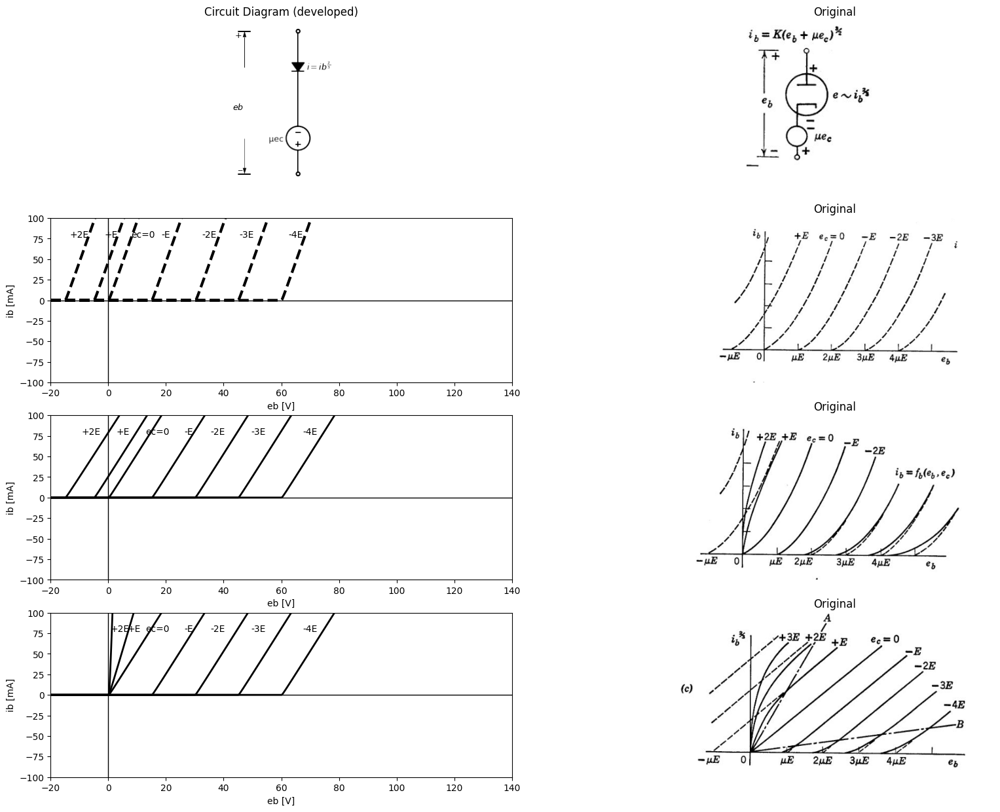

In [17]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
D1 = d.add(e.Diode(fill=True).down().idot(open=True).label(r'$i = ib^\frac{2}{3}$','bottom'))
d += (E1 := e.SourceV().down().length(3).label('μec','top').dot(open=True))
l1 = d.add(e.Line().right().length(.5).linewidth(2).at((-2.5,0)))
l2 = d.add(e.Line().right().length(.5).linewidth(2).at((-2.5,-6)))
d += e.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2.25,-1.5))
d += e.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2.25,-4.5))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((-2,-3))
d.save('images/6-8a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-8a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-8.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -15@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = .40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -30@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3',-45@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -60@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 15@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
axs[1,0].set_xlim(-20, 140)
axs[1,0].set_xlabel('eb [V]')
axs[1,0].set_ylabel('ib [mA]')
axs[1,0].set_ylim(-100, 100)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
axs[1,0].text( 12,80, 'ec=0', ha='center', va='center')
axs[1,0].text( 20, 80, '-E', ha='center', va='center')
axs[1,0].text(35,80, '-2E', ha='center', va='center')
axs[1,0].text(48,80, '-3E', ha='center', va='center')
axs[1,0].text(65,80, '-4E', ha='center', va='center')
axs[1,0].text( 1, 80, '+E', ha='center', va='center')
axs[1,0].text( -10, 80, '+2E', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-8a.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -15@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -30@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3',-45@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -60@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_V ,CJO = 7.048E-13 ,RS = 184@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 15@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
axs[2,0].set_xlim(-20, 140)
axs[2,0].set_xlabel('eb [V]')
axs[2,0].set_ylabel('ib [mA]')
axs[2,0].set_ylim(-100, 100)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
axs[2,0].text( 17,80, 'ec=0', ha='center', va='center')
axs[2,0].text( 28, 80, '-E', ha='center', va='center')
axs[2,0].text(38,80, '-2E', ha='center', va='center')
axs[2,0].text(52,80, '-3E', ha='center', va='center')
axs[2,0].text(70,80, '-4E', ha='center', va='center')
axs[2,0].text( 5, 80, '+E', ha='center', va='center')
axs[2,0].text( -6, 80, '+2E', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-8c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -15@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -30@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3',-45@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', -60@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 10@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 18.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_V ,CJO = 7.048E-13 ,RS = 84@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', '2' , model = 'BAV21')
circuit.R(1, '2', '3', 0@u_Ohm)
circuit.V('i', circuit.gnd, '3', 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
axs[3,0].set_xlim(-20, 140)
axs[3,0].set_xlabel('eb [V]')
axs[3,0].set_ylabel('ib [mA]')
axs[3,0].set_ylim(-100, 100)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].text( 17,80, 'ec=0', ha='center', va='center')
axs[3,0].text( 28, 80, '-E', ha='center', va='center')
axs[3,0].text(38,80, '-2E', ha='center', va='center')
axs[3,0].text(52,80, '-3E', ha='center', va='center')
axs[3,0].text(70,80, '-4E', ha='center', va='center')
axs[3,0].text( 9, 80, '+E', ha='center', va='center')
axs[3,0].text( 4, 80, '+2E', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-8d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 6.8. Theoretical and actual plate-current curves.

the theoretical curves are straight lines. Within the central region
contained between lines $OA$ and $OB$, the experimental curves follow the
theoretical curves very well. Above line $OA$, the actual plate current is
less than that given by the three-halves power idealization because the
potential distribution is modified by the presence of substantial space
charge in the grid-to-plate region. When $e_b$ is negative, the plate current
vanishes, since the emitted electrons are retarded to zero velocity
$(φ = 0)$ before reaching the plate. The entire cathode current is then
collected by the grid. Below line OB in Fig. 6.8(c), the actual current
lies above that predicted by the idealized theory. This departure can
be attributed primarily to unavoidable nonuniformities in grid-wire
spacing and grid-to-plate spacing. In effect, the ‘‘local” $μ$ varies slightly
from one part of the grid to another. The plate current can be visualized
as the sum of the currents in a number of smaller triodes connected in
parallel, each with a slightly different value of $μ$. The total current of
such a parallel combination does not cut off abruptly as the plate voltage
is lowered, because of the dispersion of cutoff voltages for the various
small triodes, In some tubes the grid-wire spacing is purposely made
nonuniform to make the plate-current cutoff gradual. These tubes,
called remote-cutoff tubes (in contrast to sharp cutoff), are used exten-
sively in applications where control of gain by means of grid bias is
desired. A common example of such use is an automatic gain control
circuit in a radio receiver.

# 6.7 Grid-Current Curves for a Typical Triode

The grid and cathode of a triode form a subsidiary diode which con-
ducts current for positive values of grid voltage. Grid-current curves
for a typical triode are shown in Fig. 6.9(a), where plate voltage $e_b$ is
the parameter on a plot of grid current $i_c$, versus grid voltage $e_c$. For
$e_c$ small and $e_b$, large, the grid current for constant $e_c$ is nearly inde
pendent of plate voltage, and a simple diode model represents the
grid-to-cathode behavior. Figure 6.9(b) shows another way of presenting
the same data. Below line $OA $the grid current is essentially independent
of plate voltage. Either of these presentations of the input data can be
combined with the plate-current curves to specify the resistive behavior
of a vacuum triode. Another useful form for the plate-circuit data is a
plot of $e_b$ vs.$e_c$, with $i_b$, as a parameter. Nonlinear vacuum-tube curves
are useful for locating operating points and for determining numerical
values for the parameters that appear in circuit models. However,
piecewise-linear or linear-incremental models will be our main concern
in this chapter.

# 6.8 Piecewise-Linear Approximations to Triode Curves

The qualitative character of typical triode curves suggested the
resistive models postulated in Article 6.3. These included the simple
piecewise-linear models shown in Fig. 6.4. Our brief discussion of the

theoretical basis for the resistive properties of triodes indicates that the
model of Fig. 6.4(6) should provide a fairly good quantitative approxima-

Text(0.5, 1.0, 'Original')

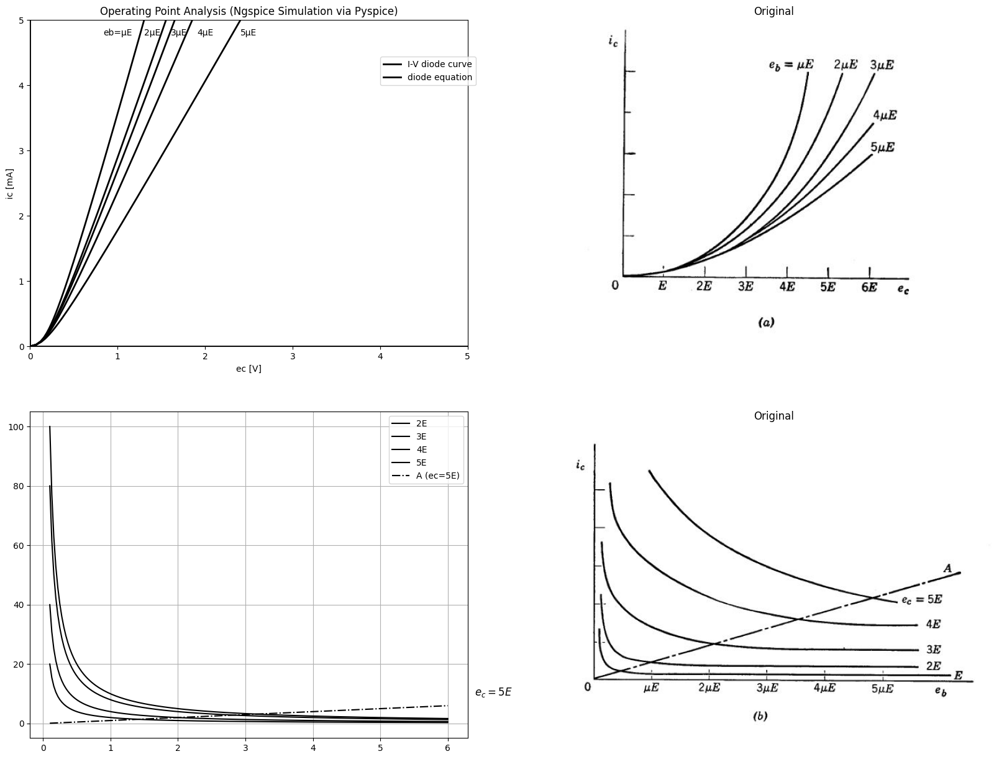

In [23]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 250@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 270@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 310@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 420@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')
axs[0,0].text( 1, 4.8, 'eb=μE', ha='center', va='center')
axs[0,0].text( 1.4, 4.8, '2μE', ha='center', va='center')
axs[0,0].text( 1.7, 4.8, '3μE', ha='center', va='center')
axs[0,0].text( 2, 4.8, '4μE', ha='center', va='center')
axs[0,0].text( 2.5, 4.8, '5μE', ha='center', va='center')
axs[0,0].axhline(0, color='black', linewidth=2)
axs[0,0].axvline(0, color='black', linewidth=2) 
axs[0,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[0,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[0,0].set_xlim(0, 5)
axs[0,0].set_ylim(0, 5)
axs[0,0].set_xlabel('ec [V]')
axs[0,0].set_ylabel('ic [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
# Set constants
mu = 1  # as per notation in the figure
E = 2   # base unit for E

# Range for eb (X-axis)
eb = np.linspace(.1, 3 * mu * E, 200)  # start at a small value to avoid division by zero

# Curve equations for different e_c values
ic_2E = 1 * E / eb
ic_3E = 2 * E / eb
ic_4E = 4 * E / eb
ic_5E = 5 * E / eb

# The straight line 'A' (e_c = 5E)
A = eb
axs[1,0].plot(eb, ic_2E, label='2E',color='black')
axs[1,0].plot(eb, ic_3E, label='3E',color='black')
axs[1,0].plot(eb, ic_4E, label='4E',color='black')
axs[1,0].plot(eb, ic_5E, label='5E',color='black')
axs[1,0].plot(eb, A, label='A (ec=5E)',color='black', linestyle='-.')
axs[1,0].text(3.2*mu*E, 4.7*E, '$e_c=5E$', fontsize=12)
axs[1,0].grid(True)
axs[1,0].legend()
#axs[1,0].title('Reproduction of the provided graph')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-9b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

## Fig. 6.9. Typical grid-current curves


tion to triode curves. If a better fit is desired, we can make use of the
fact that the triode has the same plate current versus plate voltage
relation as the vacuum diode. Thus any of the vacuum diode models
developed in Chapter 3 can be easily modified for use as triode models,

For example, the model of Fig. 6.10(a) is an adaptation of the model in
Fig. 3.13(a). The curves in Fig. 6.10(b) have sufficient flexibility to
match triode plate curves over a large portion of the $i_b$ vs. $e_c$ plane.
Letting the intercept Ey equal zero reduces the model to the simpler one
postulated in Fig. 6.4(6). It is repeated for convenient reference in

Text(0.5, 1.0, 'Original')

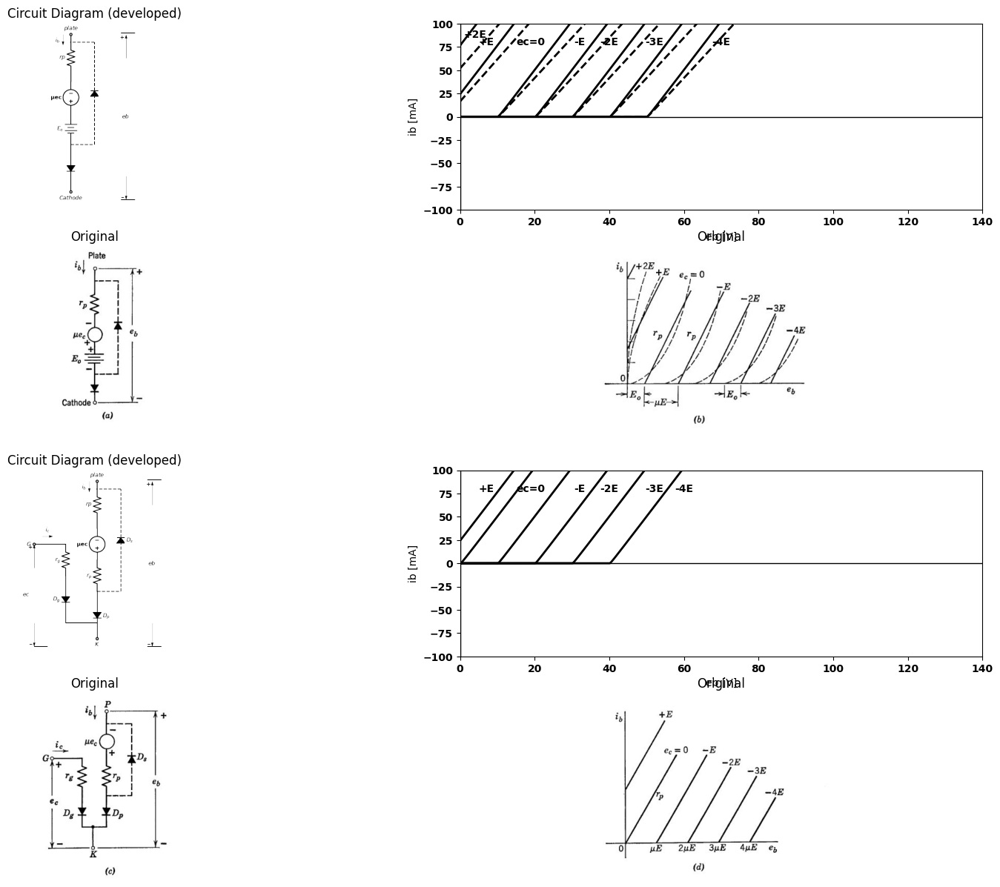

In [33]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
R1 = d.add(e.Resistor().down().idot(open=True).label('$r{p}$','top').label('$plate$','right'))
d += (E1 := e.SourceV().down().length(2).label('μec','top'))
d += (E2 := e.Battery().down().length(2).label('$E_o$','top'))
D1 = d.add(e.Diode(fill=True).down().label('$Cathode$','left').dot(open=True))
l1 = d.add(e.Line().right().length(1.5).linewidth(2).at(E2.end).linestyle('--'))
D2 = d.add(e.Diode(fill=True).up().linestyle('--').length(6.5))
l2 = d.add(e.Line().left().length(1.55).linewidth(2).linestyle('--'))
d += e.Arrow().down().linewidth(0.6).length(0.7).color('black').label('$i_b$', loc='top', color='black',ofst=0.2).at((-.5,0))
l3 = d.add(e.Line().right().length(.85).linewidth(2).at(E2.end).linestyle('-').at((3.2,0.1)))
l4 = d.add(e.Line().right().length(.85).linewidth(2).at(E2.end).linestyle('-').at((3.2,-10.5)))
d += e.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.5,-1.5))
d += e.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.5,-9))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((4,-5))
d.save('images/6-10a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-10a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
rcParams['font.weight'] = 'bold'
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 0@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -20@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -30@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -40@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 15@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 7
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 25@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)

# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', -30@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', -40@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', -20@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', -10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', 0@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', 15@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
# circuit 8
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 50@u_Ohm)
circuit.V('i', '3', '2', 25@u_V)
circuit.V('i1', '3', '4', 10@u_V)
circuit.D(2, '4',  '1' , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[0,1].set_xlim(0, 140)
axs[0,1].set_xlabel('eb [V]')
axs[0,1].set_ylabel('ib [mA]')
axs[0,1].set_ylim(-100, 100)
axs[0,1].axhline(0, color='black', linewidth=1)
axs[0,1].axvline(0, color='black', linewidth=1)
axs[0,1].text( 19,80, 'ec=0', ha='center', va='center')
axs[0,1].text( 32, 80, '-E', ha='center', va='center')
axs[0,1].text(40,80, '-2E', ha='center', va='center')
axs[0,1].text(52,80, '-3E', ha='center', va='center')
axs[0,1].text(70,80, '-4E', ha='center', va='center')
axs[0,1].text( 7, 80, '+E', ha='center', va='center')
axs[0,1].text( 4, 88, '+2E', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-10a.jpg')  # Load the PNG file
axs[1,0].imshow(img_sample)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Original')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-10b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
R1 = d.add(e.Resistor().down().idot(open=True).label('$r{p}$','top').label('$plate$','right'))
d += (E1 := e.SourceV().down().length(2).label('μec','top'))
d += (R1 := e.Resistor().down().length(2).label('$r_p$','top'))
D1 = d.add(e.Diode(fill=True).down().label('$D_p$','bottom').dot(open=True).label('$K$','left'))
l1 = d.add(e.Line().right().length(1.5).linewidth(2).at(E2.end).linestyle('--'))
D2 = d.add(e.Diode(fill=True).up().linestyle('--').length(6.5).label('$D_s$','bottom'))
l2 = d.add(e.Line().left().length(1.55).linewidth(2).linestyle('--'))
d += e.Arrow().down().linewidth(0.6).length(0.7).color('black').label('$i_b$', loc='top', color='black',ofst=0.2).at((-.5,0))
l3 = d.add(e.Line().right().length(.85).linewidth(2).linestyle('-').at((3.2,0.1)))
l4 = d.add(e.Line().right().length(.85).linewidth(2).linestyle('-').at((3.2,-10.5)))
d += e.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.5,-1.5))
d += e.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.5,-9))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((4,-5))
l5 = d.add(e.Line().left().length(2).linewidth(2).at((0,-9)))
D1 = d.add(e.Diode(fill=True).up().label('$D_g$','top').reverse())
d += (R2 := e.Resistor().up().length(2).label('$r_g$','top'))
l6 = d.add(e.Line().left().length(2).linewidth(2).label('$G$','left').dot(open=True))
l4 = d.add(e.Line().right().length(.85).linewidth(2).linestyle('-').at((-4,-10.5)))
d += e.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-4,-5.5))
d += e.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-4,-9))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{c}$', loc='start', color='black',ofst=0.3). at((-4,-7))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('$i_c$', loc='top', color='black',ofst=0.2).at((-3.5,-3.5))
d.save('images/6-10a2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-10a2.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 0@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -20@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -30@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 15@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)

axs[2,1].set_xlim(0, 140)
axs[2,1].set_xlabel('eb [V]')
axs[2,1].set_ylabel('ib [mA]')
axs[2,1].set_ylim(-100, 100)
axs[2,1].axhline(0, color='black', linewidth=1)
axs[2,1].axvline(0, color='black', linewidth=1)
axs[2,1].text( 19,80, 'ec=0', ha='center', va='center')
axs[2,1].text( 32, 80, '-E', ha='center', va='center')
axs[2,1].text(40,80, '-2E', ha='center', va='center')
axs[2,1].text(52,80, '-3E', ha='center', va='center')
axs[2,1].text(60,80, '-4E', ha='center', va='center')
axs[2,1].text( 7, 80, '+E', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-10c.jpg')  # Load the PNG file
axs[3,0].imshow(img_sample)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Original')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-10d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 6.10. Approximating triode curves with piecewise-linear models.


Fig. 6.10(c). The parameters $μ$ and $r_p$ can usually be chosen to provide
a good fit to the actual curves over most of the negative-grid region.
The model is not particularly accurate in the positive-grid region, nor
does it do more than provide a crude approximation to the grid-current
curves. Models more suitable for the positive-grid region can be devised,
but the simple one suffices for most analysis or design problems involving
triode circuits.
Referring to the model of Fig. 6.10(c), we note that $r_g$ and ideal
rectifier $D_g$ form a piecewise-linear approximation to the grid-cathode
diode, whereas $r_p$ and $D_g$ approximate the plate-cathode diode. The
dependent voltage source $μe_c$, shifts the plate-circuit curve along the
plate-voltage axis in the manner predicted by the effect of $e_c$ upon $φ_c$
and therefore upon $i_b$. The ideal rectifier $D_s$ is included to prevent
the dependent source from driving $e_b$, negative. This diode roughly
approximates the reduction in the effective value of u which takes place
in the actual triode for low values of plate voltage. The ideal rectifier
$D_s$ is connected by dotted lines in Fig. 6.10(c), because it is somewhat
less directly related to the physical behavior of triodes than are the
other elements in the model. We could realize the same set of curves
$[Fig, 6.10(d)]$ by omitting $D_s$ from the model and specifying $μ = O$ for
$e_b < 0$. This restriction on the source $μe_c$ is, in effect, a piecewise-linear
(actually a stepwise-linear) approximation to the gradual reduction in
$μ$ as $e_b$ approaches zero.

With three diodes in the model, there are eight diode states; four with
$D_s$ open, and four with $D_s$ closed. We can eliminate the four with $D_s$
closed as being of no practical interest. Three of the remaining four
diode states define the regions of major interest in triode operation.
With $D_g$ and $D_p$ off, both grid current and plate current are zero. This
current cutoff $(state I)$ exists for $e_c$ more negative than $—e_b/μ$. For
values of $e_c$ between 0 and $—e_b/μ$, $D_p$ is on and $D_g$ is off. This results
in plate current but no grid current, and is the normal forward-gain or
amplification region $(state II)$. For $e_c$ greater than 0, both $D_g$ and $D_p$
are on; hence both plate current and grid current exist. This is vari-
ously called the grid-current, positive-grid, or saturation region, and
can be designated as state II]. The remaining possibility (state IV)
calls for $D_g$ on and $D_p$ off. In this state, which cannot be achieved
without applying an appropriate source between plate and cathode to
make e, negative, a reverse gain occurs in the actual triode, and our
simple model does not describe the behavior adequately. Since this
state is of interest only in rather special instances, it will not be dis
cussed in detail. It can be represented by a generator $μ ̅e_c$, in the grid
circuit,

# 6.9 Linear Incremental Triode Models


In some circuit applications the range of values for terminal currents
and voltages is contained within a single state of the piecewise-linear
model, that is, $D_p$ and $D_g$ are at all times either $on$ or $off$, and can be
replaced by short circuits or open circuits. The piecewise-linear model
then reduces to a linear model. The linear model can be further simpli
fied by ignoring the fixed voltages and currents at the operating point
(established by d-c polarizing sources) and considering only the incre-

Text(0.5, 1.0, 'Original')

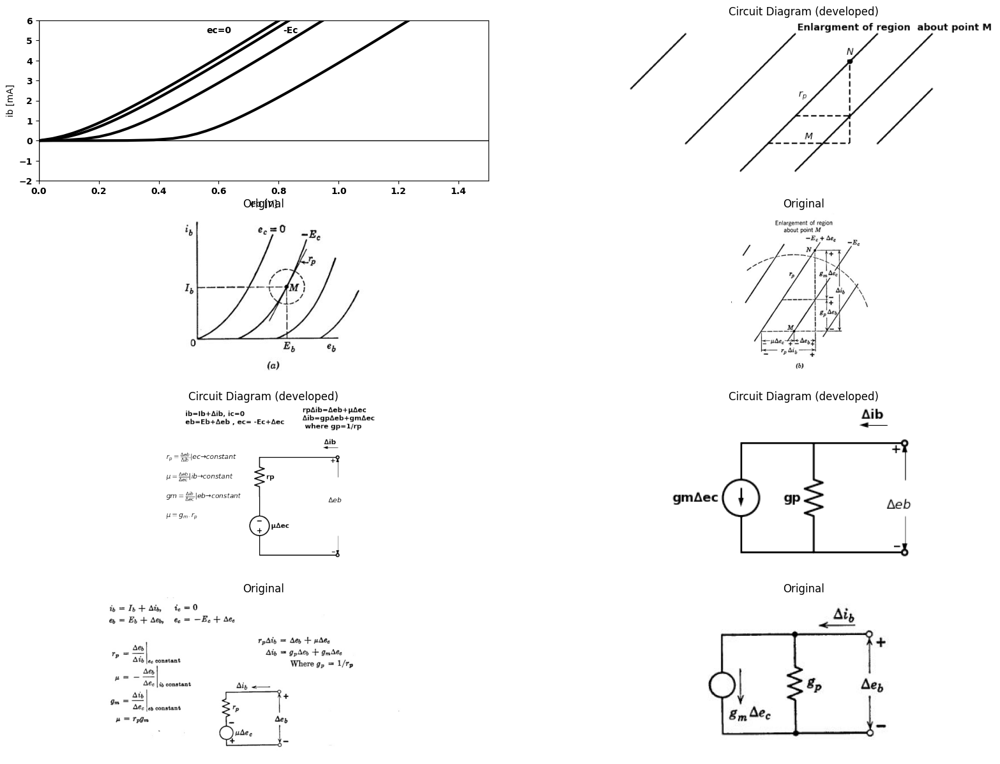

In [41]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
# circuit 1
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)

# circuit 2
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 5000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .5@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
# circuit 3
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 50@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .5@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
# circuit 2
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .5@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
axs[0,0].set_xlim(0, 1.5)
axs[0,0].set_xlabel('eb [V]')
axs[0,0].set_ylabel('ib [mA]')
axs[0,0].text( .6,5.5, 'ec=0', ha='center', va='center')
axs[0,0].text( .84, 5.5, '-Ec', ha='center', va='center')
axs[0,0].set_ylim(-2, 6)
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.002).linewidth(2))
l2 = d.add(e.Line().right().length(.002).linewidth(2).at((2,2)))
l3 = d.add(e.Line().right().length(.002).linewidth(2).at((2,-2)))
l4 = d.add(e.Line().right().length(.002).linewidth(2).at((6,2)))
l5 = d.add(e.Line().right().length(.002).linewidth(2).at((4,-3)))
l6 = d.add(e.Line().right().length(.002).linewidth(2).at((9,2)))
l7 = d.add(e.Line().right().length(.002).linewidth(2).at((6,-3)))
l8 = d.add(e.Line().right().length(.002).linewidth(2).at((11,2)))
l9 = d.add(e.Line().right().length(.002).linewidth(2).at((9,-2)))
l10 = d.add(e.Line().right().length(.002).linewidth(2).at((11,0)))
l11 = d.add(e.Line().right().length(.002).linewidth(2).endpoints(l1.end,l2.end))
l11 = d.add(e.Line().right().length(.002).linewidth(2).endpoints(l3.end,l4.end).label('Enlargment of region  about point M','right'))
l11 = d.add(e.Line().right().length(.002).linewidth(2).endpoints(l5.end,l6.end).label('$r_p$','top'))
l11 = d.add(e.Line().right().length(.002).linewidth(2).endpoints(l7.end,l8.end))
l11 = d.add(e.Line().right().length(.002).linewidth(2).endpoints(l9.end,l10.end))
l12 = d.add(e.Line().right().length(3).linewidth(2).linestyle('--').at((5,-2)).label('$M$','top'))
l12 = d.add(e.Line().up().length(3).linewidth(2).linestyle('--').dot().label('$N$','right'))
l12 = d.add(e.Line().right().length(2).linewidth(2).linestyle('--').at((6,-1)))

d.save('images/6-11a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-11a1.png')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-11a.jpg')  # Load the PNG file
axs[1,0].imshow(img_sample)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Original')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-11b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (E1 := elm.SourceV().up().length(3).label('μ∆ec','bottom').reverse())
R1 = d.add(e.Resistor().up().length(2).linewidth(2).label('rp','bottom'))
l1 = d.add(e.Line().right().length(4).linewidth(2).dot(open=True).at(R1.end))
l2 = d.add(e.Line().right().length(4).linewidth(2).dot(open=True).at(E1.start))
d += e.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((4,4))
d += e.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4,1))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$∆e{b}$', loc='start', color='black',ofst=0.3). at((4.5,3))
d += e.Arrow().left().length(.75).linewidth(1).color('black'). at((4,5.5)).label('∆ib','top')
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((-4,7)).label('ib=Ib+∆ib, ic=0\neb=Eb+∆eb , ec= -Ec+∆ec','right', color='black'))
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((2,7)).label('rp∆ib=∆eb+μ∆ec\n∆ib=gp∆eb+gm∆ec\n where gp=1/rp','right', color='black'))
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((-5,5)).label(r'$r_p=\frac {∆eb}{∆ib}|ec→ constant$','right', color='black'))
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((-5,4)).label(r'$μ=\frac {∆eb}{∆ec}|ib→ constant$','right', color='black'))
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((-5,3)).label(r'$gm=\frac {∆ib}{∆ec}|eb→ constant$','right', color='black'))
l1 = d.add(e.Line().right().length(.1).linewidth(2).color('white').at((-5,2)).label('$μ=g_m.r_p$','right', color='black'))

d.save('images/6-11c11.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-11c11.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (I1 := elm.SourceI().down().length(3).label('gm∆ec','top'))
l1 = d.add(e.Line().right().length(2).linewidth(2))
l2 = d.add(e.Line().right().length(2).linewidth(2).at(I1.start))
R1 = d.add(e.Resistor().right().length(2).linewidth(2).endpoints(l1.end,l2.end).label('gp','top'))
l3 = d.add(e.Line().right().length(2.5).linewidth(2).at(R1.end).dot(open=True))
l4 = d.add(e.Line().right().length(2.5).linewidth(2).at(R1.start).dot(open=True))
d += e.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((4.5,-1))
d += e.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4.5,-2))
d += e.Arrow().up().length(.5).linewidth(0.6).color('white').label('$∆e{b}$', loc='start', color='black',ofst=0.3). at((5,-1.5))
d += e.Arrow().left().length(.75).linewidth(1).color('black'). at((4,.5)).label('∆ib','top')

d.save('images/6-11c12.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-11c12.png')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-11c1.jpg')  # Load the PNG file
axs[3,0].imshow(img_sample)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Original')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-11d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 6.11. Linear incremental model of plate circuit.

mental variations about the operating point. The shift from total
quantities to incremental quantities amounts to shifting the origin of
coordinates to the operating point. In terms of the plate curves, the
operation takes place in a small region containing the operating point
M, as shown in Fig. 6.11(a). The plate curves in this restricted region
appear as nearly straight, parallel, equidistant lines, as shown in (b).
The values of$ r_p$ and $μ$ can be chosen for maximum accuracy in the small
region involved. In general, these values may differ slightly from those
used in the piecewise linear model, which must provide a reasonable
approximation over the entire first quadrant of the $i_b$ vs. $e_b$ plane.

The slope of the plate curves determines the parameter $r_p$ in the
incremental model. This slope is usually taken as the tangent to the
curve passing through the operating point. The horizontal spacing
between lines can be specified by the parameter  $μ$, or the vertical spacing
can be specified by a parameter $g_m$. The definitions of $r_p$, $μ$, and $g_m$ in
terms of incremental quantities are given in Fig. 6.11(c). From the
expressions, or from the geometry indicated in (b), it is evident that $μ=r_p.g_m$

Let us now consider the relations among the incremental quantities
as the instantaneous values of currents and voltages change. Referring
to Fig. 6.11(6), assume that the change corresponds to a shift from
point$M$ to the nearby point $N$. From the geometry of the figure, we see:


$∆e_b =r_p∆i_b - μ∆e_c(6.8)$


and

$∆i_b= g_p∆e_b + g_m∆e_c (6.9)$



The two cireuits shown in Fig. 6.11(d) are pictorial representations of
the two equations. Either one can be taken as an incremental model
for the triode plate circuit, since the two circuits are equivalent.
The incremental cireuit can also be obtained by application of differen
tial calculus. Referring to the general piecewise-linear model of Fig.
6.10(a) and (b), we see that


$e_b = r_p.i_b — μe_c + E_o (6.10)$

expresses the relation between $e_b,i_b$ and $e_c$. Assume now that both $μ$
and $r_p$ have been chosen to match slope and spacing in some particular
region. Total differentiation yields

$de_b = r_p di_b — μde_c (6.11)$


which is the same as the corresponding incremental relation, Eq. 6.8.
The incremental plate-circuit equation can also be obtained by
expanding the plate current in a Taylor’s series about the desired
operating point $(E_b, E_c)$. This derivation is given in Fig. 6.12. The
serles approach is not needed here, but it is important because of its
generality, It is useful for incremental analysis when linear analysis
is inadequate, since higher-order terms can be included. It is also
helpful in analyzing the linear incremental behavior of tubes having
more electrodes (tetrodes, pentodes, etc.). Since the behavior of these
tubes involves more variables, a simple geometrical interpretation such
as that of Fig. 6.11(5) is not possible.

At this point we shall introduce symbols that have become associated
with incremental grid and plate variables through common usage.




Text(0.5, 1.0, 'Original')

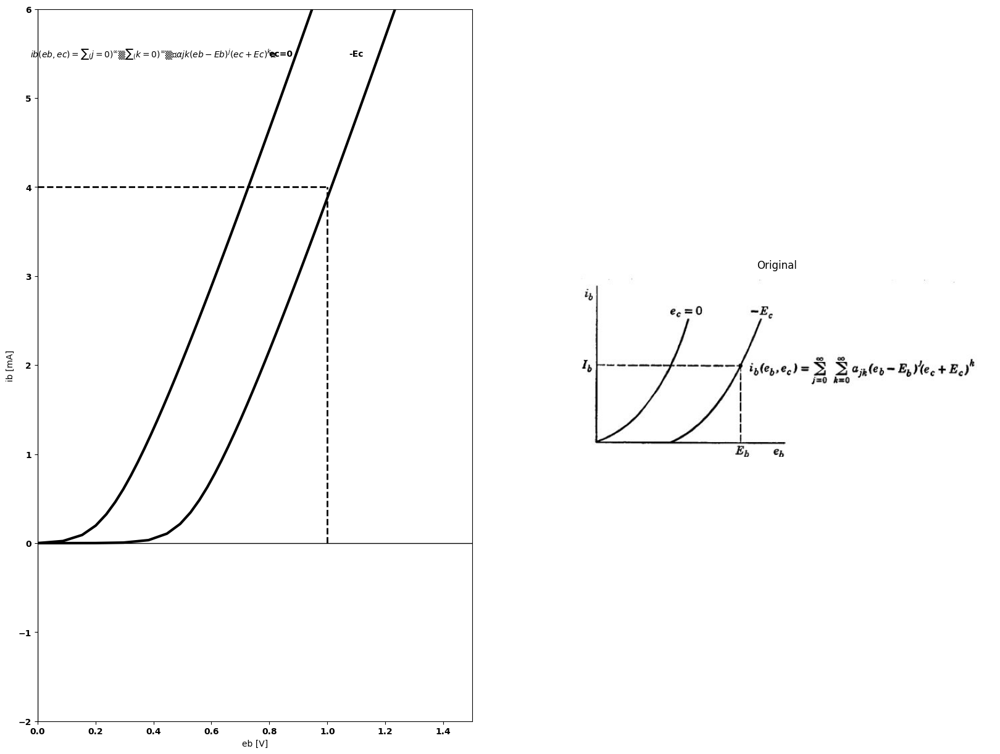

In [42]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
# circuit 1
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)

# circuit 2
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 5000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .5@u_V ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', .5@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 100, 0.1))
axs[0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
axs[0].plot([1, 1], [0, 4], color='black', linewidth=2, linestyle='--')
axs[0].plot([0, 1], [4, 4], color='black', linewidth=2, linestyle='--')
axs[0].set_xlim(0, 1.5)
axs[0].set_xlabel('eb [V]')
axs[0].set_ylabel('ib [mA]')
axs[0].text( .84,5.5, 'ec=0', ha='center', va='center')
axs[0].text( 1.1, 5.5, '-Ec', ha='center', va='center')
axs[0].text( .4,5.5, r'$ib(eb,ec)=∑_(j=0)^∞▒∑_(k=0)^∞▒〖αjk(eb-Eb)^j(ec+Ec)^k〗$', ha='center', va='center')
axs[0].set_ylim(-2, 6)
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-12.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(b) $a{00}= i_b(E_b,-E_c)=I_b$


$a{10} = \frac{∂i_b(E_b,-E_c)}{∂e_b}=g_p$


$ a{01}=\frac{∂i_b(E_b,-E_c)}{∂e_c}=g_m $


For small excursions from the operating point,

(c) $i_b (e_b,e_c) = a{oo} + a{10}(e_b — E_b) + a{01}(e_c + E_c)$


(d) $i_b (e_b,e_c)-I_b= g_p (e_b — E_b) + g_m(e_c + E_e)$


(e) $∆i_b = g_p∆e_b + g_m∆e_c$

## Fig. 6.12, Series representation of triode plate curves.

These symbols and their equivalents are:

$i_g = ∆i_c, (6.12)$


$e_g = ∆e_c (6.13)$


$i_p = ∆i_b (6.14)$


$e_p = ∆e_b (6.15)$

Let us now consider more complete models than those just shown for
the plate circuit alone. The circuit of Fig. 6.13(a) is a linear resistive
incremental model for a triode whose grid-to-cathode voltage is negative ;
the circuit of (b) is for positive values of $e_c$. Here we have added an
incremental representation for the grid circuit. Of course, the shunt
model for the plate circuit ($g_p$ in parallel with source $g_m.e_g$,) could be
used instead of the series model,

More complete linear models for negative and positive values of $e_c$
are shown in Fig. 6.18(c) and (d). These include interelectrode capaci-
tances (grid-to-cathode $C{gk}$, grid-to-plate $C{gp}$, and plate-to-cathode

Text(0.5, 1.0, 'Original')

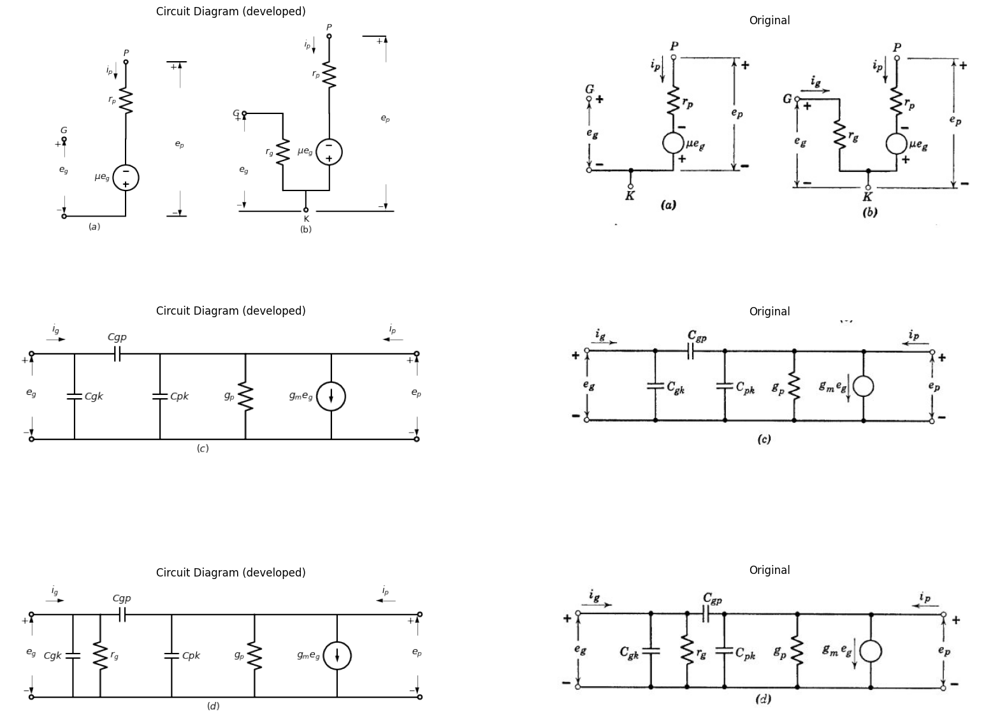

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += elm.Line().right(d.unit*.00025).dot(open=True).label('$G$','top')
d += elm.Line().right(d.unit*.8).idot(open=True).at((0,-3)).label('$(a)$','bottom')
d += elm.SourceV().up(d.unit*1).reverse().label('$μe_g$','top')
d += elm.Resistor().up(d.unit*1).reverse().label('$r_p$','top').dot(open=True).label('$P$','right')
d += elm.Line().right(d.unit*.25).at((4,3))
d += elm.Line().right(d.unit*.25).at((4,-3))
d += elm.Arrow().up().length(1).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((4.5,2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4.5,-2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=0.3). at((5,0))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.7))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_g$', loc='start', color='black',ofst=0.3). at((.5,-1))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label('$i_p$').at((2,3))
d += elm.Line().right(d.unit*.5).idot(open=True).label('$G$','left').at((7,1))
d += elm.Resistor().down(d.unit*1).label('$r_g$','top')
d +=(l1:= elm.Line().right(d.unit*.3))
d += elm.Line().down(d.unit*.25).dot(open=True).label('K\n(b)','left')
d += elm.Line().right(d.unit*.3).at(l1.end)
d += elm.SourceV().up(d.unit*1).reverse().label('$μe_g$','top')
d += elm.Resistor().up(d.unit*1).reverse().label('$r_p$','top').dot(open=True).label('$P$','right')
d += elm.Line().left(d.unit*.8).at((9.2,-2.8))
d += elm.Line().right(d.unit*1).at((9.8,-2.8))
d += elm.Line().left(d.unit*.3).at((12.5,4))
d += elm.Arrow().up().length(1).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((12.5,3))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((12.5,-1.75))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=0.3). at((13,1))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((7,.3))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((7,-2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_g$', loc='start', color='black',ofst=0.3). at((7.5,-1))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label('$i_p$').at((9.7,4))
d.save('images/6-13a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-13a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-13a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Line().right(d.unit*.5).idot(open=True)
d +=(C1:= elm.Capacitor().down(d.unit*1).label('$C{gk}$','bottom'))
d += elm.Line().left(d.unit*.5).dot(open=True)
d +=(C2:= elm.Capacitor().right(d.unit*1).label('$C{gp}$','top').at(C1.start))
d +=(C3:= elm.Capacitor().down(d.unit*1).label('$C{pk}$','bottom'))
d += elm.Line().left(d.unit*1)
d += elm.Line().right(d.unit*1).at(C3.start)
d += elm.Line().right(d.unit*1).at(C3.end).label('$(c)$','bottom')
d +=(R1:= elm.Resistor().up(d.unit*1).reverse().label('$g_p$','top'))
d += (l1:=elm.Line().right(d.unit*1).at(R1.start))
d += elm.Line().right(d.unit*1).at(R1.end)
d += (I:=elm.SourceI().up(d.unit*1).reverse().label('$g_me_g$','top').at(l1.end))
d += elm.Line().right(d.unit*1).at(I.start).dot(open=True)
d += elm.Line().right(d.unit*1).at(I.end).dot(open=True)
d += elm.Arrow().right().length(.7).linewidth(0.6).color('black').label('$i_g$').at((.5,0.5))
d += elm.Arrow().left().length(.7).linewidth(0.6).color('black').label('$i_p$').at((13,.5))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((13.5,-.75))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((13.5,-2.2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=0.3). at((14,-1.2))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.75))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_g$', loc='start', color='black',ofst=0.3). at((.5,-1.2))
d.save('images/6-13b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-13b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-13b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Line().right(d.unit*.5).idot(open=True)
d +=(C1:= elm.Capacitor().down(d.unit*1).label('$C{gk}$','top'))
d += elm.Line().left(d.unit*.5).dot(open=True)
d +=(C2:= elm.Capacitor().right(d.unit*1.2).label('$C{gp}$','top').at(C1.start))
d +=(C3:= elm.Capacitor().down(d.unit*1).label('$C{pk}$','bottom'))
d += elm.Line().left(d.unit*1.2)
d += elm.Line().right(d.unit*1).at(C3.start)
d += elm.Line().right(d.unit*1).at(C3.end).label('$(d)$','bottom')
d +=(R1:= elm.Resistor().up(d.unit*1).reverse().label('$g_p$','top'))
d += (l1:=elm.Line().right(d.unit*1).at(R1.start))
d += elm.Line().right(d.unit*1).at(R1.end)
d += (I:=elm.SourceI().up(d.unit*1).reverse().label('$g_me_g$','top').at(l1.end))
d += elm.Line().right(d.unit*1).at(I.start).dot(open=True)
d += elm.Line().right(d.unit*1).at(I.end).dot(open=True)
d += elm.Arrow().right().length(.7).linewidth(0.6).color('black').label('$i_g$').at((.5,0.5))
d += elm.Arrow().left().length(.7).linewidth(0.6).color('black').label('$i_p$').at((13.2,.5))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((14,-.75))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((14,-2.2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=0.3). at((14.5,-1.2))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.75))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_g$', loc='start', color='black',ofst=0.3). at((.5,-1.2))
d +=(R2:= elm.Resistor().down(d.unit*1).reverse().label('$r_g$','bottom').at((2.5,0)))
d.save('images/6-13c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-13c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-13c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig. 6.13. Incremental triode models. Note: $e_g = ∆e_c, i_g = ∆i_c, e_p = ∆e_b, and i_p = ∆i_b$.

$C_pk$), which become important when voltage variations occur at high
frequencies, As frequency is raised to still higher values, it may be-
come necessary to introduce circuit elements representing the induct-
ance of the leads that support the electrodes. For sufficiently high
frequencies, it is also necessary to use complex values of g, or » in order
to introduce a phase lag that accounts for the transit time of electrons
through the interelectrode space. We have been vague in specifying
frequencies for which interelectrode capacitances, lead inductances,
or transit-time effects become important. Quantitative discussion of
these effects is better deferred until required in connection with specific
circuit problems. The relative influence of the capacitances and induct-
ances depends heavily on the values of external circuit parameters as
well as on frequency. Transit-time effects depend on tube geometry
and operating voltages.

# 6.10 Grounded-Cathode Amplifier Circuit


The simplest triode circuit is the grounded-cathode amplifier, some
times called the plate-loaded amplifier. The circuit shown in Fig. 6.14(a)
includes a triode, the plate polarizing battery $E{bb}$, and the plate load
resistance $R_b$. Resistance $R_c$, may be considered as part of the amplifier,
or it may be associated with the source $e_1$. Either the source $e_1$, or
auxiliary circuitry provides a $d-c$ polarizing grid voltage$ —E{cc}$. which
establishes a quiescent operating point Q.

Let the triode plate-circuit behavior be specified by the curves of
Fig. 6.14(6). Then the load resistance $R_b$ and source $E_bb$, impose the
linear load constraint, which can be expressed by the relation

$i_b = (E{bb} — e_b)/R_b (6.16)$

This equation plots as a straight line on the triode curves and is desig-
nated by Ry. The quiescent operating point Q is determined by the
condition $e_c = —E{cc}$., together with the load constraint. By assuming
various values for $e_c$, we can plot the transfer curves $i_b$ vs. $e_c$. and $e_b$ Vs. $e_c$,
shown in (c) and (d). Point P, the intersection of the load line and the
$e_c = 0$ line, marks the boundary between the amplification region and
the grid-current region. If we wish to relate$i_b$; and $e_b$, to the input voltage
$e_1$, rather than $e_c$, we must consider the effects of the source resistance
$R_c$. The curve of $e_b$ vs. $e_1$ shown in (f) is identical with the $e_b$ vs. $e_c$,
curve of part (d) in the region where $e_c$, is negative, since $i_c$, is then
negligible and F, has no effect. However, where e, is positive the curves
will differ, and the triode input curves shown in part (e) must be used
to effect a solution in this region. Since $e_c = e_1 — i_cR_c$, the resistance
$R_c$ imposes a linear constraint that can be plotted on the input curves
by locating two points. A given value of $e_c$, determines $e_b$; on the plate
curves, Then $e_b$ and $e_c$, locate a point such as A on the input curves.
A line of slope 1/Rc, through this point locates the value of $e_1$ correspond
ing to the assumed value of $e_c$. In Fig. 6.14(f) the dotted line designated
Rc = 0 is the same as the curve in (d), since e1 = ec when Rc = 0.
The dotted line $R_c = ∞$indicates perfect limiting at $e_c = 0$. For any
value of Rc, the positive-grid portion of the transfer curve must lie
between these two extremes.

Text(0.5, 1.0, 'Original')

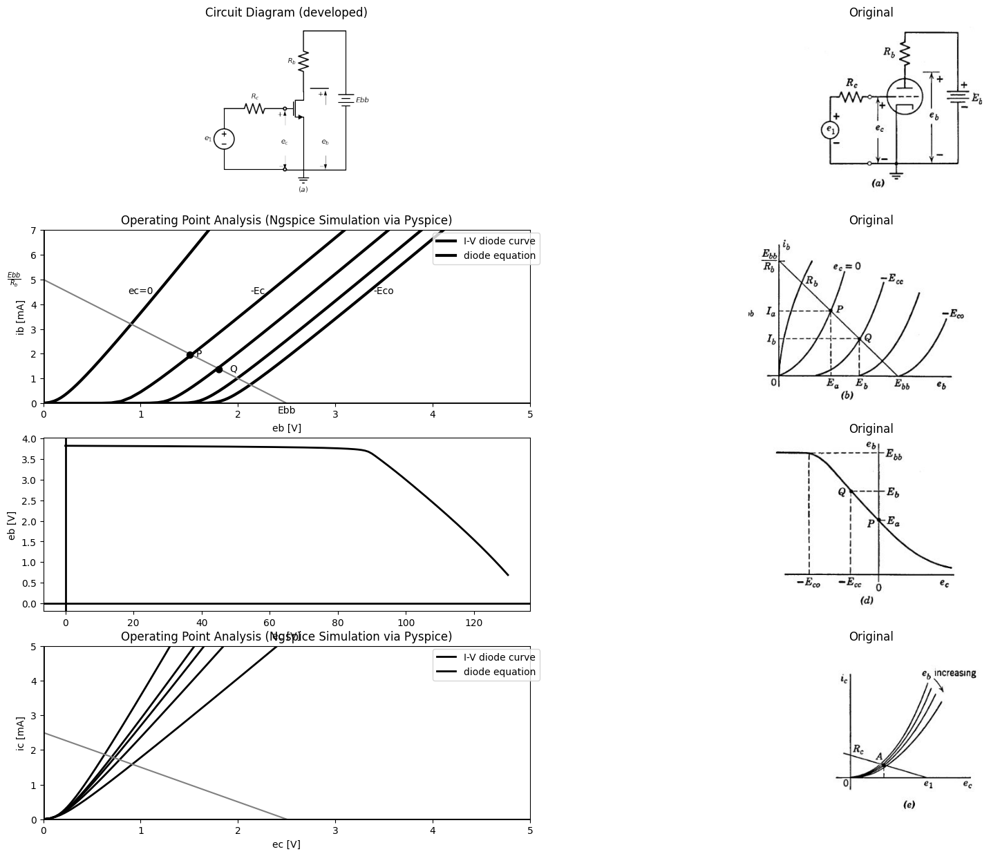

In [9]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Resistor().right(d.unit*1).label('$R_c$','top').dot(open=True)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().up(d.unit*1).label('$R_b$','top').at(M1.drain))
d += elm.Line().right(d.unit*1).dot(open=True).at(V.start)
d += (l3:=elm.Line().down(d.unit*.73).at(M1.source))
d += elm.Line().left(d.unit*.3)
d += elm.Line().right(d.unit*.7).at(R2.end)
d += (E1 := elm.Battery().down().length(6.85).label('$E{bb}$','bottom'))
d += elm.Line().left(d.unit*.7)
d += elm.Line().right(d.unit*.3).at((4.25,4))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((3,2.2))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_c$', loc='start', color='black',ofst=0.3). at((3.5,1.5))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((5,3.2))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=0.3). at((5.5,1.5))
d += elm.Ground().label('$(a)$','bottom').at(l3.end)
d.save('images/6-14a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-14a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-14a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')



circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[1,0].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5) 
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2) 
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,0].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[1,0].text( 2.2, 4.545, '-Ec', ha='center', va='center')
axs[1,0].text( 1.8, 1.4, '●', ha='center', va='center')
axs[1,0].text( 1.5, 2, '●', ha='center', va='center')
axs[1,0].text( 1.95, 1.4, 'Q', ha='center', va='center')
axs[1,0].text( 1.6, 2, 'P', ha='center', va='center')
axs[1,0].text( 3.5, 4.545, '-Eco', ha='center', va='center')
axs[1,0].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[1,0].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[1,0].set_xlim(0, 5)
axs[1,0].set_ylim(0, 7)
axs[1,0].set_xlabel('eb [V]')
axs[1,0].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-14b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

circuit = Circuit('v-i curve')
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=.5E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.6)
circuit.V(1, '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.MOSFET(1, '2', '3', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(2, '3', '4', 1@u_kOhm)
#source = circuit.SinusoidalVoltageSource(2, '4', circuit.gnd, amplitude=2@u_V, frequency=1@u_kHz)
circuit.V(2, '4', circuit.gnd, 3@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(V1=slice(-10, 3, 0.1))
#ax1.plot(analysis['1'], u_A(-analysis.V1),'black',linewidth=2)
axs[2,0].plot(analysis['3']- analysis['2'],'black',linewidth=2)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2) 
axs[2,0].set_xlabel('ec [V]')
axs[2,0].set_ylabel('eb [V]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-14d.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 250@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 270@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 310@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 420@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 1000@u_Ohm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[3,0].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5)
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2) 
axs[3,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[3,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[3,0].set_xlim(0, 5)
axs[3,0].set_ylim(0, 5)
axs[3,0].set_xlabel('ec [V]')
axs[3,0].set_ylabel('ic [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-14e.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 6.14, Grounded-cathode amplifier—graphical analysis using nonlinear triode curves.

The nonlinear relations shown in Fig. 6.14(c), (d), and (f) must be
plotted point by point in order to obtain reasonable accuracy. The
graphical triode curves, furnished by the manufacturer or measured
experimentally, are the basis for determining any such relations between
current and voltage variables.

For comparison with the nonlinear graphical analysis, let us carry
out a graphical analysis of the same circuit, using a piecewise-linear


Text(0.5, 1.0, 'Original')

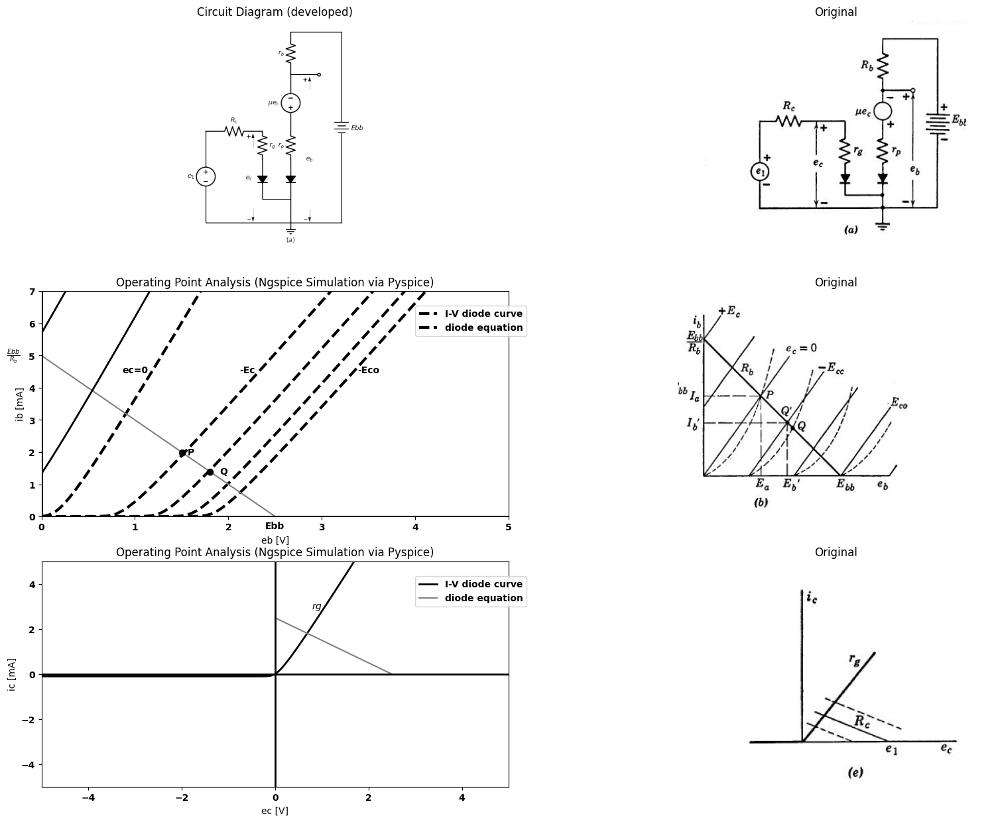

In [3]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1.6).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d +=(R2:= elm.Resistor().down(d.unit*.5).label('$r_g$','bottom'))
d +=(D1:= elm.Diode(fill=True).down(d.unit*.7))
d += elm.Line().right(d.unit*.5)
d +=(D2:= elm.Diode(fill=True).up(d.unit*.7).reverse())
d +=(R3:= elm.Resistor().up(d.unit*.5).label('$r_p$','top'))
d += (V2:=elm.SourceV().up(d.unit*1).label('$μe_c$','top').reverse())
d += elm.Line().right(d.unit*.5).dot(open=True)
d +=(R3:= elm.Resistor().up(d.unit*.75).label('$r_b$','top').at(V2.end))
d += elm.Line().right(d.unit*.9)
d += (E1 := elm.Battery().down().length(10.1).label('$E{bb}$','bottom'))
d += elm.Line().left(d.unit*2.4)
d +=(l5:= elm.Line().down(d.unit*.4).at(D2.start))
d += elm.Ground().label('$(a)$','bottom').at(l5.end)
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.5,7))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.5,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=0.3). at((6,3.5))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((2.5,4))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2.5,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_c$', loc='start', color='black',ofst=0.3). at((2.8,2.5))
d.save('images/6-15a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-15a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-15a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[1,0].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5) 
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 1.5@u_V)
circuit.V('i1', '3', '4', 1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 1.5@u_V)
circuit.V('i1', '3', '4', .1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)

axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2) 
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,0].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[1,0].text( 2.2, 4.545, '-Ec', ha='center', va='center')
axs[1,0].text( 1.8, 1.4, '●', ha='center', va='center')
axs[1,0].text( 1.5, 2, '●', ha='center', va='center')
axs[1,0].text( 1.95, 1.4, 'Q', ha='center', va='center')
axs[1,0].text( 1.6, 2, 'P', ha='center', va='center')
axs[1,0].text( 3.5, 4.545, '-Eco', ha='center', va='center')
axs[1,0].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[1,0].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[1,0].set_xlim(0, 5)
axs[1,0].set_ylim(0, 7)
axs[1,0].set_xlabel('eb [V]')
axs[1,0].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-15b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.R(2, '2', '3', 100@u_Ohm)
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-5, 5, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 1000@u_Ohm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 2.5, 0.1))

axs[2,0].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2) 
axs[2,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[2,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[2,0].set_xlim(-5, 5)
axs[2,0].set_ylim(-5, 5)
axs[2,0].set_xlabel('ec [V]')
axs[2,0].set_ylabel('ic [mA]')
axs[2,0].text( .9, 3, '$r{g}$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-15e.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig. 6.15. Graphical analysis of grounded-cathode circuit using a piecewise-linear triode model.

model for the triode, as indicated by Fig. 6.15. The circuit is shown
schematically in (a), and the piecewise-linear triode curves are given
in (b). The actual triode curves are shown by dotted lines. In making
this particular piecewise-linear approximation to the actual tube curves,
the slope $r_p$ was made such that the $e_c = 0$ line intersects the actual
$e_c = 0 $curve at the point P. Thus $I_a$, and $E_a$, will have the same values
in both solutions. The value of $μ$ was adjusted to yield the same grid
voltage $(—Eco)$ for plate-current cutoff when $e_b = E{bb}$. Wehave thereby
matched the approximation to the actual curves at the transition be-
tween states I and II and between II and III. This yields a fairly
good average match over the region of major interest: namely, the
amplification region (state II).

Text(0.5, 1.0, 'Original')

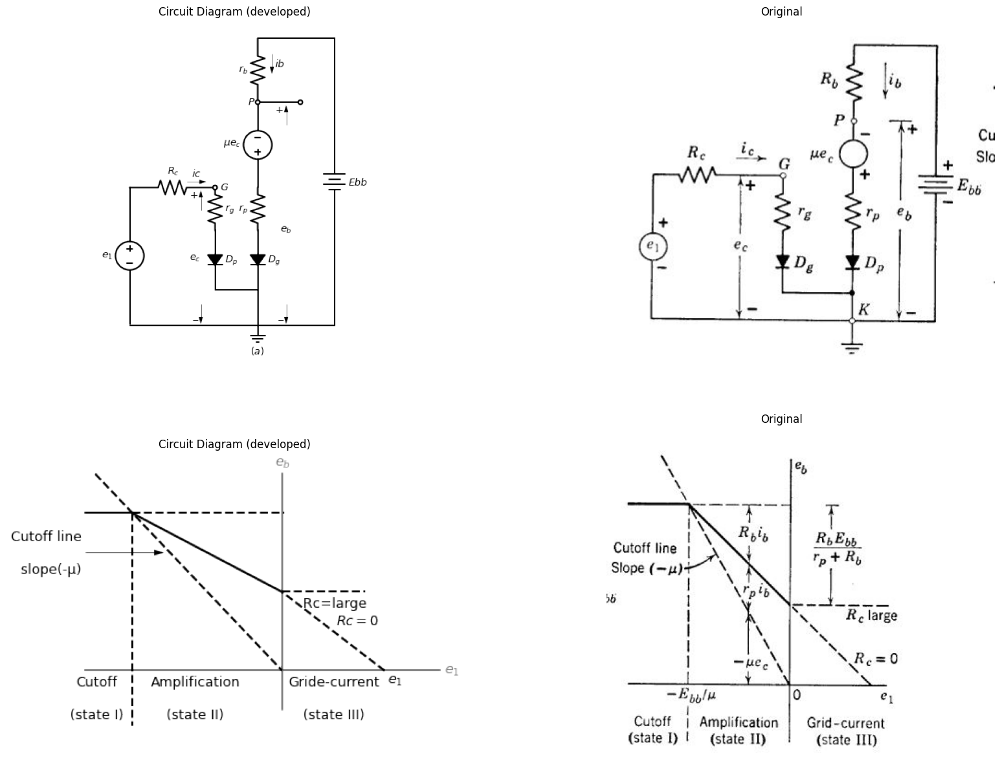

In [5]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1.6).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top').dot(open=True).label('$G$','right'))
d +=(R2:= elm.Resistor().down(d.unit*.5).label('$r_g$','bottom'))
d +=(D1:= elm.Diode(fill=True).down(d.unit*.7).label('$D_p$','bottom'))
d += elm.Line().right(d.unit*.5)
d +=(D2:= elm.Diode(fill=True).up(d.unit*.7).reverse().label('$D_g$','bottom'))
d +=(R3:= elm.Resistor().up(d.unit*.5).label('$r_p$','top'))
d += (V2:=elm.SourceV().up(d.unit*1).label('$μe_c$','top').reverse().dot(open=True))
d += elm.Line().right(d.unit*.5).dot(open=True).label('$P$','left')
d +=(R3:= elm.Resistor().up(d.unit*.75).label('$r_b$','top').at(V2.end))
d += elm.Line().right(d.unit*.9)
d += (E1 := elm.Battery().down().length(10.1).label('$E{bb}$','bottom'))
d += elm.Line().left(d.unit*2.4)
d +=(l5:= elm.Line().down(d.unit*.4).at(D2.start))
d += elm.Ground().label('$(a)$','bottom').at(l5.end)
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.5,7))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.5,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=0.3). at((6,3.5))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((2.5,4))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2.5,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_c$', loc='start', color='black',ofst=0.3). at((2.8,2.5))
d += elm.Arrow().right().length(.7).linewidth(0.6).color('black').label('$i{c}$','top'). at((2,5))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label('$i{b}$','bottom'). at((5,9.5))
d.save('images/6-16a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-16a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-16a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Line().up(d.unit*2).color('gray').label('$e_b$','right')
d += elm.Line().right(d.unit*3).at((-5,1)).color('gray').label('$e_1$','right')
d += (l1:=elm.Line().right(d.unit*.4).at((-5,5)))
d += (l2:=elm.Line().right(d.unit*.7).at((0,3)).linestyle('--').label('     Rc=large','bottom'))
d += elm.Line().up(d.unit*2).color('black').endpoints(l1.end,l2.start)
d += (l3:=elm.Line().right(d.unit*.2).color('gray').at((2,1)))
d += elm.Line().up(d.unit*2).color('black').endpoints(l3.end,l2.start).linestyle('--').label('$e_1$','right').label('$Rc=0$','top')
d += (l4:=elm.Line().right(d.unit*.002).color('gray').at((0,1)))
d += (l5:=elm.Line().right(d.unit*.002).color('black').at((-4.75,6)))
d += elm.Line().up(d.unit*2).color('black').endpoints(l5.end,l4.start).linestyle('--')
d += (l6:=elm.Line().down(d.unit*1.8).color('black').at(l1.end).linestyle('--'))
d += (l6:=elm.Line().right(d.unit*1.29).color('black').at(l1.end).linestyle('--'))
d += (l7:=elm.Line().right(d.unit*.2).color('gray').at((-5,1)).label('Cutoff\n\n(state I)','bottom',color='black'))
d += (l7:=elm.Line().right(d.unit*.2).color('gray').at((-2.5,1)).label('Amplification\n\n(state II)','bottom',color='black'))
d += (l7:=elm.Line().right(d.unit*.2).color('gray').at((1,1)).label('Gride-current\n\n(state III)','bottom',color='black'))
d += elm.Arrow().right().length(2).linewidth(0.6).color('black').label('Cutoff line\n\n slope(-μ)','left'). at((-5,4))
d.save('images/6-16b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-16b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-16b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

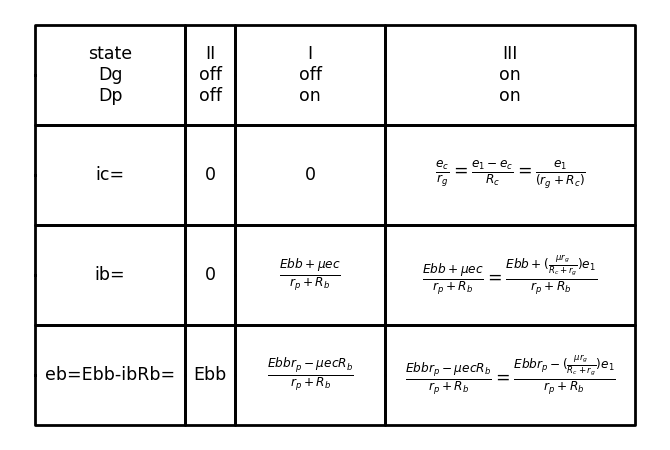

In [7]:
import schemdraw
import schemdraw.elements as elm
from schemdraw import dsp
with schemdraw.Drawing() as d:
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('state\nDg\nDp'))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('ic=').at((0,-2)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('ib=').at((0,-4)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('eb=Ebb-ibRb=').at((0,-6)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('II\noff\noff').at((3,0)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('0').at((3,-2)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('0').at((3,-4)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('Ebb').at((3,-6)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('I\noff\non').at((4,0)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('0').at((4,-2)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label(r'$\frac {Ebb+μec}{r_p+R_b}$').at((4,-4)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label(r'$\frac {E{bb}r_p-μecR_b}{r_p+R_b}$').at((4,-6)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label('III\non\non').at((7,0)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac{e_c}{r_g}=\frac{e_1-e_c}{R_c}=\frac{e_1}{(r_g+R_c)}$').at((7,-2)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac {Ebb+μec}{r_p+R_b}=\frac {E{bb}+(\frac {μr_g}{R_c+r_g})e_1}{r_p+R_b}$').at((7,-4)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac {Ebbr_p-μecR_b}{r_p+R_b}=\frac {E{bb}r_p-(\frac {μr_g}{R_c+r_g})e_1}{r_p+R_b}$').at((7,-6)))
    
    

## Fig. 6.16, Relations between total voltages and currents in grounded-cathode circuit (using a piecewise-linear triode model).

The curves of Fig. 6.15(c), (d), (e), and (f) can be compared directly
with the corresponding curves of Fig. 6.14. Note that the graphical
constructions for the piecewise-linear circuits are greatly simplified by
the fact that all variables must be related by piecewise-linear curves,
so that two points (break points) suffice to plot each segment. In
Fig. 6.15(c) and (d), the dotted lines show the nonlinear solution ob-
tained from Fig. 6.14(c) and (d). The quiescent point $Q ̅$ for the approxi-
mation does not coincide with Q for the actual curves. For some
applications it may be preferable to match the piecewise-linear model
to the actual curves at the desired quiescent point rather than at P,
and to let other portions of the approximate transfer curves deviate
from the actual ones.

The use of piecewise-linear models permits simple algebraic solution
of resistive-circuit problems. Nevertheless, free-hand graphical sketches
provide a worth-while visual supplement. For the grounded-cathode
circuit, algebraic results can be written by mspection. They are pre-
sented in tabular form in Fig. 6.16. The sketch of $e_b vs. e_1$; in Fig. 6.16
shows the influence of the various circuit: parameters on the dimensions
of the transfer curve $e_b$ vs. $e_1$. Observe from the tabulation that state I
corresponds to removal of the triode from the circuit, and is analytically
trivial. Nevertheless, in many circuit applications the cutoff state
occurs during the cycle of operation.

# 6.11 Polarizing the Grounded-Cathode Circuit

The grounded-cathode circuit is useful for virtually all of the functions performed by electronic circuits; namely, voltage amplification, power amplification, wave shaping, waveform generation, modulation, and demodulation. Various modes of operation are determined by the relative values of polarizing voltages and signal voltages applied to the circuit. Energy-storage elements also play a vital role in the behavior of the circuit but detailed consideration of these effects is deferred to Chapters 8 and 9. For the present we shall use capacitances only as "ideal coupling elements" to illustrate practical methods of providing polarizing voltages and of coupling one amplifier circuit to another. Ideal coupling implies a capacitance (or an inductance) so large that the stored energy does not change appreciably due to a-c signal variations. The capacitance is then effectively a short circuit for a-c but an open circuit for d-c. A reasonable model for the capacitor in this case is a battery whose voltage equals the capacitor voltage. Such a battery provides a zero resistance path for a-c and holds the average current at the proper value (zero).

If a polarizing battery or voltage source carries direct current in the reverse direction, the source can be replaced by a parallel combination of resistance and capacitance. The resistance is chosen to produce a voltage drop equal to the battery voltage when the specified d-c current



Text(0.5, 1.0, 'Original')

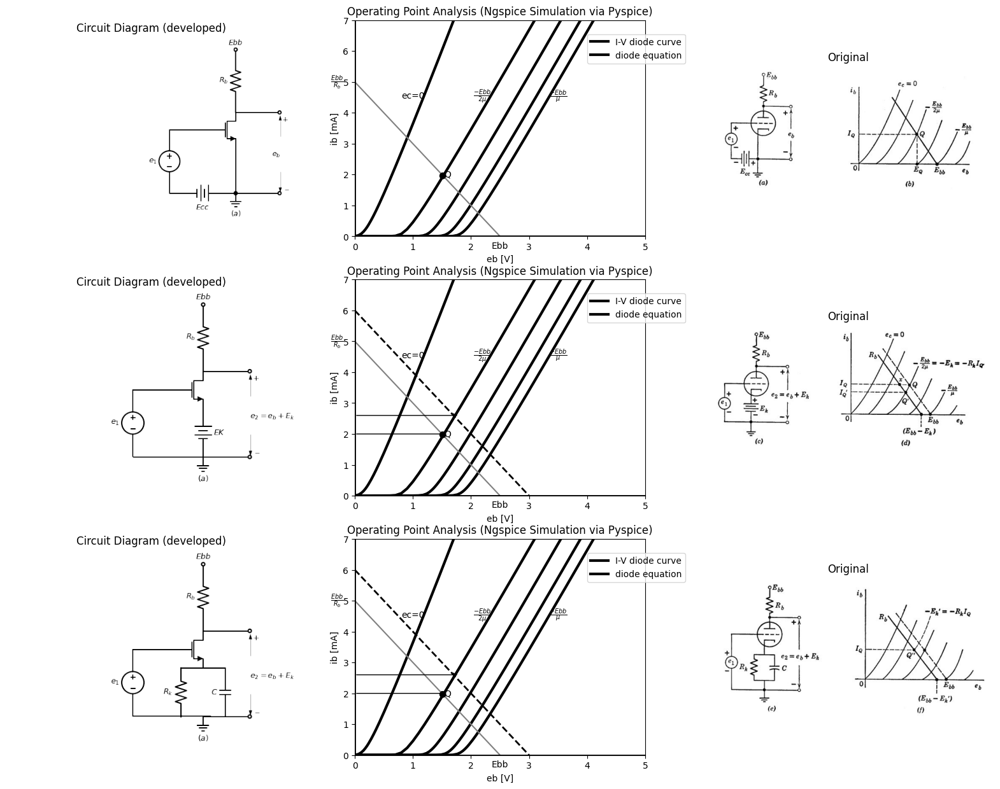

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Line().right(d.unit*.75)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += elm.Line().down(d.unit*.73).at(M1.source).dot()
d += (E1 := elm.Battery().left().length(3.15).label('$E{cc}$','bottom'))
d += elm.Ground().label('$(a)$','bottom').at(E1.start)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_b$','top').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.7).at(M1.drain).dot(open=True))
d += (l1:=elm.Line().right(d.unit*.7).at(E1.start).dot(open=True))
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=-12.3). at((-7,2))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.3,2.7))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.3,1))
d.save('images/6-17a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-17a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')



circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[0,1].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5) 
axs[0,1].axhline(0, color='black', linewidth=2)
axs[0,1].axvline(0, color='black', linewidth=2) 
axs[0,1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[0,1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[0,1].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[0,1].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[0,1].text( 1.5, 2, '●', ha='center', va='center')
axs[0,1].text( 1.6, 2, 'Q', ha='center', va='center')
axs[0,1].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[0,1].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[0,1].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[0,1].set_xlim(0, 5)
axs[0,1].set_ylim(0, 7)
axs[0,1].set_xlabel('eb [V]')
axs[0,1].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-17a.jpg')  # Load the PNG file
axs[0,2].imshow(img_sample)
axs[0,2].axis('off')  # Hide axes for image display
axs[0,2].set_title('Original')
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Line().right(d.unit*.75)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += (E1 := elm.Battery().down().length(2.2).label('$E{K}$','bottom').at(M1.source))
d += (l11 := elm.Line().left().length(3.15))
d += elm.Ground().label('$(a)$','bottom').at(E1.end)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_b$','top').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.7).at(M1.drain).dot(open=True))
d += (l1:=elm.Line().right(d.unit*.7).at(E1.end).dot(open=True))
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_2=e_b+E_k$', loc='start', color='black',ofst=-12.3). at((-5,2))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.3,2.7))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.3,1))
d.save('images/6-17b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-17b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')



circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[1,1].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5) 
circuit = Circuit('thev')
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 3@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[1,1].plot(analysis['1'],u_mA(analysis.Vth),'black',linewidth=2,linestyle='--') 
axs[1,1].axhline(0, color='black', linewidth=2)
axs[1,1].axvline(0, color='black', linewidth=2) 
axs[1,1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,1].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[1,1].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[1,1].text( 1.5, 2, '●', ha='center', va='center')
axs[1,1].text( 1.6, 2, 'Q', ha='center', va='center')
axs[1,1].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[1,1].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[1,1].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[1,1].annotate('', xy=(1.6, 2), xytext=(0, 2), arrowprops=dict(arrowstyle='->'))
axs[1,1].annotate('', xy=(1.8, 2.6), xytext=(0, 2.6), arrowprops=dict(arrowstyle='->'))
axs[1,1].set_xlim(0, 5)
axs[1,1].set_ylim(0, 7)
axs[1,1].set_xlabel('eb [V]')
axs[1,1].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-17b.jpg')  # Load the PNG file
axs[1,2].imshow(img_sample)
axs[1,2].axis('off')  # Hide axes for image display
axs[1,2].set_title('Original')
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Line().right(d.unit*.75)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += (l3 := elm.Line().left().length(1))
d += (l4 := elm.Line().right().length(1).at(l3.start))
d +=(R2:= elm.Resistor().down(d.unit*.74).label('$R_k$','top').at(l3.end))
d +=(C1:= elm.Capacitor().down(d.unit*.74).label('$C$','top').at(l4.end))
d += (l5 := elm.Line().right().length(3.5).at(V.start))
d += elm.Ground().label('$(a)$','bottom').at(E1.end)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_b$','top').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.7).at(M1.drain).dot(open=True))
d += (l2:=elm.Line().right(d.unit*.7).at(E1.end).dot(open=True))
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_2=e_b+E_k$', loc='start', color='black',ofst=-12.3). at((-5,2))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.3,2.7))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.3,1))
d.save('images/6-17c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-17c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[2,1].plot(analysis['1'],u_mA(analysis.Vth),'gray',linewidth=1.5) 
circuit = Circuit('thev')
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 3@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))
axs[2,1].plot(analysis['1'],u_mA(analysis.Vth),'black',linewidth=2,linestyle='--') 
axs[2,1].axhline(0, color='black', linewidth=2)
axs[2,1].axvline(0, color='black', linewidth=2) 
axs[2,1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[2,1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[2,1].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[2,1].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[2,1].text( 1.5, 2, '●', ha='center', va='center')
axs[2,1].text( 1.6, 2, 'Q', ha='center', va='center')
axs[2,1].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[2,1].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[2,1].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[2,1].annotate('', xy=(1.6, 2), xytext=(0, 2), arrowprops=dict(arrowstyle='->'))
axs[2,1].annotate('', xy=(1.8, 2.6), xytext=(0, 2.6), arrowprops=dict(arrowstyle='->'))
axs[2,1].set_xlim(0, 5)
axs[2,1].set_ylim(0, 7)
axs[2,1].set_xlabel('eb [V]')
axs[2,1].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-17c.jpg')  # Load the PNG file
axs[2,2].imshow(img_sample)
axs[2,2].axis('off')  # Hide axes for image display
axs[2,2].set_title('Original')

## Fig. 6.17. Grounded-cathode circuit polarized for linear amplification.



is flowing. The capacitance provides a path for alternating currents and must be large enough to maintain a nearly constant voltage. Grid polarizing voltages are normally provided in this way, since it is more economical than a separate source.

The circuit shown in Fig. 6.17 (a) uses a separate source Ecc to polarize the grid somewhere between plate-current cutoff and grid-current conduction. To provide the maximum range of linear operation the value of Ece should be approximately Ebb/2µ, which results in the quiescent point Q shown in (b) of Fig. 6.17. The circuit shown in (c) yields essentially the same result if we let Et have the same value as Ecc. Since Ebb/2µ is appreciably smaller than Ebb, the operating point


Text(0.5, 1.0, 'Original')

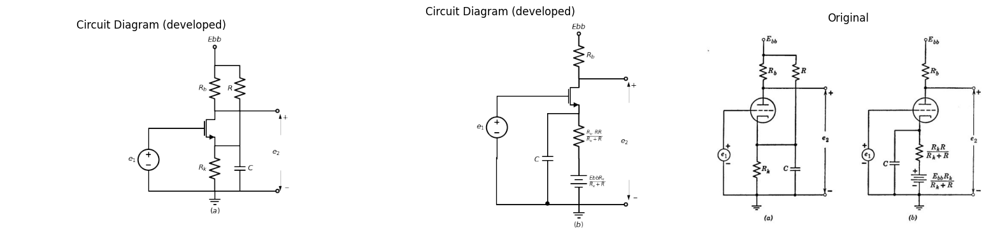

In [20]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Line().right(d.unit*.75)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R1:= elm.Resistor().down(d.unit*.72).label('$R_k$','top').at(M1.source))
d += elm.Line().right(d.unit*.4).at(M1.source)
d +=(C1:= elm.Capacitor().down(d.unit*.72).label('$C$','bottom'))
d += elm.Line().left(d.unit*1.45)
d += elm.Ground().label('$(a)$','bottom').at(R1.end)
d +=(R2:= elm.Resistor().up(d.unit*.72).label('$R_b$','top').at(M1.drain))
d += elm.Line().right(d.unit*.4)
d +=(R3:= elm.Resistor().down(d.unit*.72).label('$R$','top'))
d += elm.Line().down(d.unit*.7)
d += elm.Line().right(d.unit*1).dot(open=True).at(M1.drain)
d += elm.Line().right(d.unit*.6).dot(open=True).at(C1.end)
d += elm.Line().up(d.unit*.3).dot(open=True).at(R2.end).label('$E{bb}$','right')
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=-12.3). at((-6,2))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((6.3,2.7))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((6.3,1))
d.save('images/6-18a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-18a1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d += elm.Line().right(d.unit*1)
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R1:= elm.Resistor().down(d.unit*.72).label(r'$\frac {R_k.RR}{R_k+R}$','bottom').at(M1.source))
d += (E1 := elm.Battery().down().length(2.2).label(r'$\frac{E{bb}R_k}{R_k+R}$','bottom'))
d += elm.Line().left(d.unit*1.309)
d += elm.Line().up(d.unit*.75)
d += elm.Line().left(d.unit*.5).at(M1.source)
d +=(C1:= elm.Capacitor().down(d.unit*1.439).label('$C$','top').dot())
d +=(R2:= elm.Resistor().up(d.unit*.72).label('$R_b$','bottom').at(M1.drain).dot(open=True).label('$E{bb}$','right'))
d += elm.Line().right(d.unit*.75).at(M1.drain).dot(open=True)
d += elm.Line().right(d.unit*.75).at(E1.end).dot(open=True)
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=-12.3). at((-6,1))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((6.3,2.7))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((6.3,-1))
d += elm.Ground().label('$(b)$','bottom').at(E1.end)
d.save('images/6-18b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-18b1.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6-18.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

## Fig. 6.18. Polarizing circuit that permits plate-current cutoff.


Q' shown in (d) differs only slightly from that of (b). Since plate current passes through Ek we can replace the battery by a resistance Ek/IQ in parallel with a large capacitance, as shown in (e). Alternatively, the operating point can be maintained at the current IQ by reducing Ex to the value Ex' as shown in (f). The value of Re required is then Ek'/IQ.

The values of Rk, Rb, and Ebb in Fig. 6.17(e) can be chosen to place the operating point at nearly any point in the first quadrant. However, since the cathode voltage depends on plate current, this circuit can never produce plate-current cutoff under quiescent conditions. Current is positive for all finite values of Rk. A circuit that yields a greater range of possibilities in this regard is shown in Fig. 6.18(a). The equivalent form (b) places in evidence the effective battery produced by the current through R and Rk with plate current equal to zero

# 6.12 Incremental Analysis of Grounded-Cathode Amplifier

Within a given state of the piecewise-linear model, we can further simplify calculations by using a linear incremental model. The equations relating incremental voltages and currents in Fig. 6.19 (a) and (b) can be obtained by total differentiation of the appropriate equations in

Text(0.5, 1.0, 'Original')

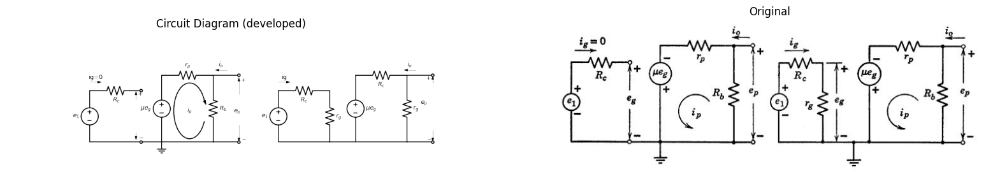

In [21]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','bottom').dot(open=True))
d += elm.Line().right(d.unit*1).dot(open=True).at(V.start)
d += elm.Line().right(d.unit*.4)
d += (V1:=elm.SourceV().up(d.unit*1.3).label('$μe_g$','top'))
d +=(R2:=elm.Resistor().right(d.unit*1).label('$r_p$','top'))
d +=(R3:=elm.Resistor().down(d.unit*1.3).label('$R_b$','bottom'))
d += (l1:=elm.Line().left(d.unit*1))
d += elm.Ground().at(V1.start)
d += elm.Line().right(d.unit*.5).dot(open=True).at(R3.start)
d += elm.Line().right(d.unit*.5).dot(open=True).at(R3.end)
d += elm.LoopCurrent([R2,R3,l1,V1] , pad = 0.2).label('$i_p$')
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=-12.3). at((-3.5,2))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((8.7,2.79))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8.7,1))
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('ig=0'). at((0,3.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_o$'). at((8,4.2))
    #d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$e_g$', loc='start', color='black',ofst=-12.3). at((.5,2))
d += elm.Arrow().up().length(.5).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((2.7,2.49))
d += elm.Arrow().down().length(.5).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((2.7,.6))
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top').at((11,0)))
d +=(R4:= elm.Resistor().right(d.unit*1).label('$R_c$','bottom'))
d +=(R5:= elm.Resistor().down(d.unit*1).label('$r_g$','bottom'))
d += (l5:=elm.Line().left(d.unit*1))
d += elm.Line().right(d.unit*.5).at(l5.start)
d += (V1:=elm.SourceV().up(d.unit*1.3).label('$μe_g$','bottom'))
d +=(R6:= elm.Resistor().right(d.unit*1).label('$R_c$','bottom'))
d +=(R7:= elm.Resistor().down(d.unit*1.3).label('$r_g$','bottom'))
d += (l6:=elm.Line().left(d.unit*1))
d += (l5:=elm.Line().right(d.unit*.5).dot(open=True).at(R7.start))
d += (l5:=elm.Line().right(d.unit*.5).dot(open=True).at(R7.end))
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('ig'). at((11,3.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_o$'). at((19,4.2))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((20,3.2))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((20,.7))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$e_p$', loc='start', color='black',ofst=0.3). at((20,2.5))
d.save('images/6-19b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-19b1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

img_sample = mpimg.imread('images/6-19.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

$i_g=0;e_1=e_g$  →       $ig=\frac{e_g}{r_g}=\frac{e_1-e_g}{R_c}=\frac{e_1}{R_c+r_g}$

$i_p=\frac {μe_g}{r_p+R_b}$→ $i_p=\frac{μe_g}{r_p+R_b}$


$e_p= -\frac {μe_gR_b}{R_b+r_p}$ → $e_b= -\frac{μe_gR_b}{r_p+R_b}$ 


$G= \frac {e_p}{e_g}=- \frac {μR_b}{R_b+r_p}$ → $G= \frac {e_p}{e_g}= \frac {-μR_b}{R_b+r_p}$


$R_o= \frac {e_p}{i_o}= \frac {r_pR_b}{R_b+r_p}$ → $G_1= \frac {e_p}{e_1}= -(\frac {μR_b}{R_b+r_p})(\frac {r_g}{r_g+R_c})$


$R_i=\frac {e_1}{i_g}$→ $R_o= \frac {e_p}{i_o}=\frac {r_pR_b}{R_b+r_p}$


$(a)$  → $R_i=\frac {e_1}{i_g}=r_g+R_c$

## Fig. 6.19. Incremental analysis of grounded-cathode circuit. (a) Negative grid, ec < 0 (state II). (6) Positive grid, ec > 0 (state III).


Fig. 6.16 and replacement of dib by gip, deb by ep, etc. The circuit models in Fig. 6.19 follow directly from these incremental equations. When the equations relating total quantities are totally differentiated, the direct components of voltage and current always disappear. Thus the linear incremental model can be obtained directly from the linear model by short-circuiting all d-c voltage sources and open-circuiting all d-c current sources.

The voltage gain

$G = de_b/de_c =e_p/e_g(6.17)$


is the slope of the transfer curve $e_b$ vs. $e_c$, and


$G1 = de_b/de_l = e_p/e_1	(6.18)$


is the slope of eb vs. e1. Referring to the graphical plots of these transfer curves [Fig. 6.15(d) and (f )1, we see that in state I


$G = G_1 = 0 (6.19)$


and in state II

$G=G_1= \frac {-μR_b}{R_b+r_p} (6.20)$

whereas in state III

$ G= \frac {-μR_b}{R_b+r_p} (6.21)$


and

$G_1=G \frac {r_g}{r_g+R_c} (6.22)$



For the nonlinear transfer curves e6 vs. ec, or eb vs. el, we see that the slope varies smoothly instead of abruptly as the triode operation passes from one region to another. Such discrepancy is the price we must pay in return for the convenience of linear approximation. When necessary, a better approximation can be made at the transition between two regions of operation.
Expressions for incremental input resistance R, and output resistance R0 are also given in Fig. 6.19. Assuming R, to he part of the amplifier, we see that the incremental input resistance faced by the source ei is
$Ri= r_g + R_c	(6.23)$
If R, is considered as part of the source, the input resistance to the amplifier will be simply
$Ri = e_g/_ = r_g	(6.24)$
The output resistance Ho may be interpreted as the increment of output voltage produced by a unit change of external current $i0$. This is clearly equal to the output conductance $Go = 1/Ro.$ Alternatively, we may calculate $R0$ by applying Thevenints theorem to the output ter-minals, whence R9 is the ratio of open-circuit voltage $μe_gR_b/(Rb +r_p)$ to short-circuit current $μe_g/r_p$ at the output terminals. In either case the result is

$R_o = R_br_p/(R_b+r_p) (6.25)$


Voltage amplification for the grounded-cathode circuit is seen to be a fraction of the triode amplification factor p. The range of values of
in different types of readily available triodes is quite large, say from 3 to 100. The incremental plate resistance is apt to be nearly propor¬tional to A for triodes of comparable size and power rating. In other words, gm = yin, is largely determined by the power rating of the tube. For triodes operating at power levels of a few watts, g„, ranges from 1000 to 10,000 micromhos. The value of plate-load resistance $R_b$, relative to $r_p$,, determines the fraction of A available as voltage amplifi¬cation. For triode amplifier circuits Rb is commonly made comparable to rp.
# 6.13 The Cathode-Follower Circuit
Slight rearrangement of the circuit elements used in the plate-loaded amplifier yields the cathode-follower circuit shown in Fig. 6.20(a), The load resistance Rk and the polarizing battery Ebb are connected in series with the plate and cathode, just as before. The terminal common to input and output voltage is at a different position in the plate-circuit loop, but this does not affect the determination of plate current $i_b$ for a given grid-to-cathode voltage$ e_c$


Assume that the triode plate current is specified by the curves of Fig. 6.20(0. The linear load constraint is given (as before) by

$i_b=(Ebb — e_b)/R_k	(6.26)$

When plotted on the tube curves, this constraint is exactly the same (for ieb =Rk) as for the plate-loaded case. Accordingly, for negative values of e, the transfer curve 4 vs. e, shown in Fig. 6.20 (e) is the same as that of Fig. 6.14 (a). For positive $e_c$, the grid current must be taken into account, since $i_b + i_c $is the current in the load resistor Rk. The effect on the transfer curve is shown by the dotted line in Fig. 6.20(c), The curve of e2 vs. ec in (d) corresponds to the curve of $e_b$, vs. $e_c$ in Fig. 6.14(d), except that it rises from zero $(e_2 = i_bR_k)$ instead of falling from Ebb as ec increases from$ —E{co}$. In the positive-grid region


$e_2 =(i_b	+ i_c)R_k	(6.27)$


hence, the curve can rise above the value $E{bb}$. if $e_2$ is greater than$ E{bb}$; then $e_b$ is less than 0 and $i_b = 0$ so that

$e_2 =i_c R_k = e_1 R_k/ (R_K+	r_g	+R_c)	(6.28)$


This circuit state, with the grid-cathode diode conducting and the plate-


Text(0.5, 1.0, 'Circuit Diagram (developed)')

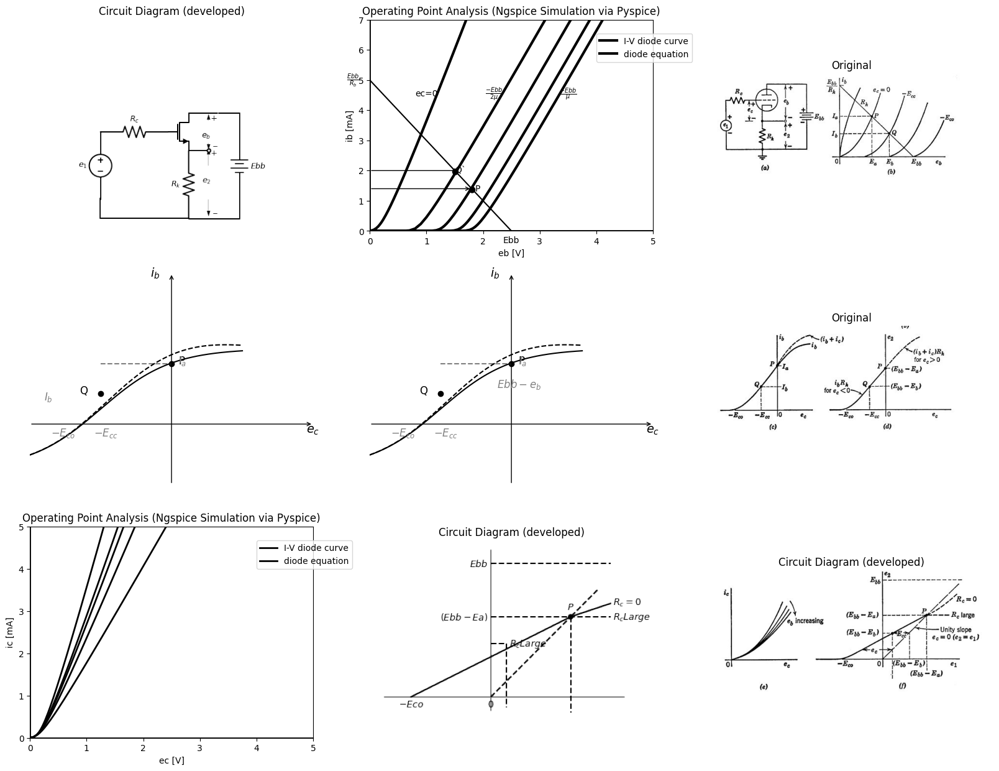

In [12]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_k$','top').at(M1.source))
d += (l1:=elm.Line().left(d.unit*1.308))
d += (l2:=elm.Line().up(d.unit*.3))
d += (l3:=elm.Line().right(d.unit*.75).at(M1.drain))
d += (E1 := elm.Battery().down().length(4.7).label('$E{bb}$','bottom').at(l3.end))
d += (l4:=elm.Line().left(d.unit*.75))
d += (l5:=elm.Line().right(d.unit*.3).at(M1.source).dot(open=True))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=0.3). at((5.2,1))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.8,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((4.8,0))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=0.3). at((5.2,3))
d += elm.Arrow().up().length(.3).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.8,3.5))
d += elm.Arrow().down().length(.3).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((4.8,2.5))
d.save('images/6-20a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-20a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0,1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[0,1].plot(analysis['1'],u_mA(analysis.Vth),'black',linewidth=1.5) 
circuit = Circuit('thev')
axs[0,1].axhline(0, color='black', linewidth=2)
axs[0,1].axvline(0, color='black', linewidth=2) 
axs[0,1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[0,1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[0,1].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[0,1].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[0,1].text( 1.8, 1.4, '●', ha='center', va='center')
axs[0,1].text( 1.5, 2, '●', ha='center', va='center')
axs[0,1].text( 1.9, 1.4, 'P', ha='center', va='center')
axs[0,1].text( 1.6, 2, 'Q`', ha='center', va='center')
axs[0,1].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[0,1].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[0,1].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[0,1].set_xlim(0, 5)
axs[0,1].set_ylim(0, 7)
axs[0,1].set_xlabel('eb [V]')
axs[0,1].set_ylabel('ib [mA]')
axs[0,1].annotate('', xy=(1.6, 2), xytext=(0, 2), arrowprops=dict(arrowstyle='->'))
axs[0,1].annotate('', xy=(1.8, 1.4), xytext=(0, 1.4), arrowprops=dict(arrowstyle='->'))
img_sample = mpimg.imread('images/6-20a.jpg')  # Load the PNG file
axs[0,2].imshow(img_sample)
axs[0,2].axis('off')  # Hide axes for image display
axs[0,2].set_title('Original')

axs[1,0].annotate('', xy=(2, 0), xytext=(-2, 0), arrowprops=dict(facecolor='black', arrowstyle='->'))
axs[1,0].annotate('', xy=(0, 5), xytext=(0, -2), arrowprops=dict(facecolor='black', arrowstyle='->'))

# Axis labels
axs[1,0].text(2, -0.3, '$e_c$', fontsize=14, ha='center')
axs[1,0].text(-0.3, 5, '$i_b$', fontsize=14, va='center')

# Points P and Q
P = (0, 2)
Q = (-1, 1)
axs[1,0].plot(*P, 'ko')
axs[1,0].plot(*Q, 'ko')
axs[1,0].text(P[0]+0.1, P[1], 'P', fontsize=12)
axs[1,0].text(Q[0]-0.3, Q[1], 'Q', fontsize=12)

# Horizontal dashed lines for Ia and Ib
axs[1,0].hlines(P[1], Q[0], P[0], colors='gray', linestyles='--')
x1 = np.linspace(-2, 1, 500)
i_b = P[1]*np.tanh(x1+1) + 0.5
i_b_dashed = i_b + 0.3*np.exp(- (x1 - 0.3)**2)

axs[1,0].plot(x1, i_b, 'k-', label='$i_b$ (solid)')
axs[1,0].plot(x1, i_b_dashed, 'k--', label='$i_b$ (dashed)')

axs[1,0].text(0.1, P[1], r'$I_a$', color='gray', fontsize=12)
axs[1,0].text(Q[0]-0.8, Q[1]-0.2, r'$I_b$', color='gray', fontsize=12)
axs[1,0].text(Q[0]-0.1, -0.4, r'$-E_{cc}$', color='gray', fontsize=12)
axs[1,0].text(-1.7, -0.4, r'$-E_{co}$', color='gray', fontsize=12)

# Hide ticks and frame
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])
axs[1,0].spines['top'].set_visible(False)
axs[1,0].spines['right'].set_visible(False)
axs[1,0].spines['left'].set_visible(False)
axs[1,0].spines['bottom'].set_visible(False)
axs[1,0].set_xlim(-2, 2)
axs[1,0].set_ylim(-2, 5)
# Draw axes with arrows
axs[1,1].annotate('', xy=(2, 0), xytext=(-2, 0), arrowprops=dict(facecolor='black', arrowstyle='->'))
axs[1,1].annotate('', xy=(0, 5), xytext=(0, -2), arrowprops=dict(facecolor='black', arrowstyle='->'))

# Axis labels
axs[1,1].text(2, -0.3, '$e_c$', fontsize=14, ha='center')
axs[1,1].text(-0.3, 5, '$i_b$', fontsize=14, va='center')

# Points P and Q
P = (0, 2)
Q = (-1, 1)
axs[1,1].plot(*P, 'ko')
axs[1,1].plot(*Q, 'ko')
axs[1,1].text(P[0]+0.1, P[1], 'P', fontsize=12)
axs[1,1].text(Q[0]-0.3, Q[1], 'Q', fontsize=12)

# Horizontal dashed lines for Ia and Ib
axs[1,1].hlines(P[1], Q[0], P[0], colors='gray', linestyles='--')
x1 = np.linspace(-2, 1, 500)
i_b = P[1]*np.tanh(x1+1) + 0.5
i_b_dashed = i_b + 0.3*np.exp(- (x1 - 0.3)**2)

axs[1,1].plot(x1, i_b, 'k-', label='$i_b$ (solid)')
axs[1,1].plot(x1, i_b_dashed, 'k--', label='$i_b$ (dashed)')

# Labels I_a, I_b, -E_cc, -E_co on the plot
axs[1,1].text(0.1, P[1], r'$I_a$', color='gray', fontsize=12)
axs[1,1].text(Q[0]+0.8, Q[1]+0.2, r'$E{bb}-e_b$', color='gray', fontsize=12)
axs[1,1].text(Q[0]-0.1, -0.4, r'$-E_{cc}$', color='gray', fontsize=12)
axs[1,1].text(-1.7, -0.4, r'$-E_{co}$', color='gray', fontsize=12)
# Hide ticks and frame
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])
axs[1,1].spines['top'].set_visible(False)
axs[1,1].spines['right'].set_visible(False)
axs[1,1].spines['left'].set_visible(False)
axs[1,1].spines['bottom'].set_visible(False)
axs[1,1].set_xlim(-2, 2)
axs[1,1].set_ylim(-2, 5)
img_sample = mpimg.imread('images/6-20b.jpg')  # Load the PNG file
axs[1,2].imshow(img_sample)
axs[1,2].axis('off')  # Hide axes for image display
axs[1,2].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 250@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 270@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 310@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 420@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[2,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2) 
axs[2,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[2,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[2,0].set_xlim(0, 5)
axs[2,0].set_ylim(0, 5)
axs[2,0].set_xlabel('ec [V]')
axs[2,0].set_ylabel('ic [mA]')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((1,0)).label('$-Eco$','bottom'))
d += (l4:=elm.Line().right(d.unit*.0003).color('black').at((4,0)).label('$0$','bottom'))
d += (l5:=elm.Line().right(d.unit*.0003).color('black').at((7,3)).label('$P$','top').dot())
d += (l6:=elm.Line().right(d.unit*.0003).color('black').at((8,4)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l3.end,l5.end))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l4.end,l5.end).linestyle('--'))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l6.end,l5.end).linestyle('--'))
d += (l8:=elm.Line().right(d.unit*.0003).color('black').at((8.5,3.5)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l5.end,l8.end).linestyle('-').label('$R_c=0$','right'))
d += (l9:=elm.Line().right(d.unit*1.5).color('black').at((4,3)).linestyle('--').label('$R_c Large$','right').label('$(Ebb-Ea)$','left'))
d += (l10:=elm.Line().right(d.unit*1.5).color('black').at((4,5)).linestyle('--').label('$E{bb}$','left'))
d += (l11:=elm.Line().right(d.unit*.2).color('black').at((4,2)).linestyle('--').label('$R_c Large$','right'))
d += (l12:=elm.Line().down(d.unit*.8).color('black').linestyle('--'))
d += (l13:=elm.Line().down(d.unit*1.2).color('black').at((7,3)).linestyle('--'))
d.save('images/6-20d1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-20d1.png')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-20c.jpg')
axs[2,2].imshow(img)
axs[2,2].axis('off')  # Hide axes for image display
axs[2,2].set_title('Circuit Diagram (developed)')

## Fig. 6.20. Cathode-follower circuit-transfer curies

cathode diode cut off, was not realizable in the plate-loaded circuit merely by varying e.1. Although possible in the cathode follower, it is neither a useful nor a likely mode of operation. In the positive-grid region, grid-current curves such as those shown in Fig. 6.20 (e), or some equivalent grid-circuit data, are required for quantitative determination of the $(i_b +i_c)$ vs. $e_c $or $e_2 $vs. $e_c$ curves.
The over-all voltage transfer curve $(e_2 vs. e_1)$ for the cathode follower
 
is plotted in Fig. 6.20(f). The voltage $e_1 = e_c e_2 $is obtained from the curve of $e_2$ vs. $e_c$ plotted in (d) by adding output voltage $e_2 $to$ e_c$ to end the new abscissa e1. This effectively shears the original curve to the right. The unity-slope dashed line through the origin indicates the amount by which the curve in (d) is sheared to the right for various values of $e_2$; for example, $e_2 = 0$ means $i_b 0$ ; hence $e_1 = e_c =-E{co}$ a common point on the two curves. The curve of $e_2 vs. e_l$ can also be derived directly from the $i_b$ vs. $e_b$ curve (b) as follows:

**1.**	Assume a value of $e_c.$
**2.** From Fig. 6.20 (b) find the corresponding value of $i_b$.
**3.**	Find e2 using $e_2 = i_bR_k$.
**4.**	Find e1 using $e_l = e_c + e_2$.

At point $P$, $e_c = 0 $and $e_1 = (E{bb} — E_a)$. For el greater than this value, the curve is horizontal if R, is large, since e, remains zero regardless of el. If Rc = 0, the slope of the curve remains about the same, or it may actually increase slightly because of grid current through RK. If rg is negligibly small compared with Rh, then for Rc = 0

$e_2= e_1R_K/(R_Kr_g)≈e_1 (6.29)$


In this case the curve would approach the unity-slope line very closely.
The transfer curve e2 VS. e1 shown in Fig. 6.20(f) specifies the circuit behavior over a range of values of the input voltage. If only a single operating point is sought (say for $e_1= E_1$), we can determine $e_2$ by the procedure outlined in Fig. 6.21. Assuming $e_c$ is less than zero, we must satisfy the three conditions

$E_1 =e_c+e_2 (6.30)$

$i_b = \frac{E{bb}-e_b}{R_K}(6.31)$

$i_b= f(e_b,e_c) (6.32)$


In Fig. 6.21, the load line (Eq. 6.31) is designated by Rk. Equation 6.30 can be plotted on the tube curves by substituting ibRk for e2, so that

$E1 = e_c i_bR_k	(6.33)$

Or

$i_b= (E_1 — e_c)/R_k	(6.34)$

Equation 6.34 thus assumes the same form as Eq. 6.31, but with ec appearing in place of eb. We might therefore designate this as a transfer line, since one input and one output variable are involved. The relation, shown by dotted lines on the tube curves of Fig. 6.21, is commonly called a "bias line." Intersection of this line with the plate-circuit load

line determines the required operating point. If E1 is greater than $(E{bb} — E_a)$, so that ec is greater than zero at the required operating point, any of several similar procedures can be followed to effect a
solution. Note that in this case


$E_1=	e_c+	e_2 =e_c+	(i_b	+i_c)R_k(6.35)$

and

$(i_b	+i_c)=(E{bb}-e_b)R_K (6.36)$

Text(0.5, 1.0, 'Original')

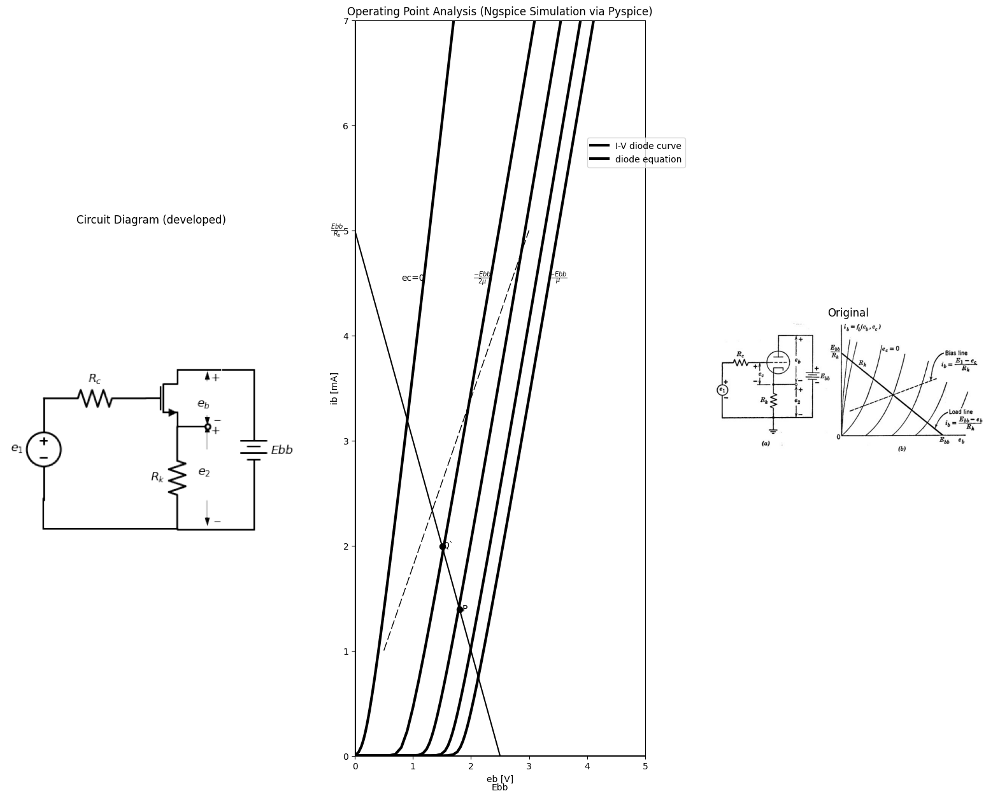

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_k$','top').at(M1.source))
d += (l1:=elm.Line().left(d.unit*1.308))
d += (l2:=elm.Line().up(d.unit*.3))
d += (l3:=elm.Line().right(d.unit*.75).at(M1.drain))
d += (E1 := elm.Battery().down().length(4.7).label('$E{bb}$','bottom').at(l3.end))
d += (l4:=elm.Line().left(d.unit*.75))
d += (l5:=elm.Line().right(d.unit*.3).at(M1.source).dot(open=True))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=0.3). at((5.2,1))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.8,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((4.8,0))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_b$', loc='start', color='black',ofst=0.3). at((5.2,3))
d += elm.Arrow().up().length(.3).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.8,3.5))
d += elm.Arrow().down().length(.3).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((4.8,2.5))
d.save('images/6-20a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-20a1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.5@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[1].plot(analysis['1'],u_mA(analysis.Vth),'black',linewidth=1.5) 
circuit = Circuit('thev')
axs[1].axhline(0, color='black', linewidth=2)
axs[1].axvline(0, color='black', linewidth=2) 
axs[1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[1].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[1].text( 1.8, 1.4, '●', ha='center', va='center')
axs[1].text( 1.5, 2, '●', ha='center', va='center')
axs[1].text( 1.9, 1.4, 'P', ha='center', va='center')
axs[1].text( 1.6, 2, 'Q`', ha='center', va='center')
axs[1].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[1].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[1].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[1].set_xlim(0, 5)
axs[1].set_ylim(0, 7)
axs[1].set_xlabel('eb [V]')
axs[1].set_ylabel('ib [mA]')
axs[1].plot([.5, 3], [1, 5],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img_sample = mpimg.imread('images/6-21.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

## Fig. 6.21. Cathode-follower operating-point determination.

Thus, if we have available the graphical plots of $i_b= f(e_b,e_c)$ and
$i_c= f(e_b,e_c)$, we can replot the curves as $i_k = (i_b + i_c) =f_K (e_b, e_c).$ The load line and bias line can then be plotted on the curves of $i_K$ vs. $e_b$, as before to locate the operating point. If we do not replot the triode data, a cut-and-try solution is required. Since this proceeds best if values of ec are assumed, it is almost as simple to form the complete transfer curve as to find a single operating point.
A piecewise-linear triode model in a cathode-follower circuit is shown in Fig. 6,22(a). Plate-current curves corresponding to the model are shown in (b), and the simple grid-current curve appears in (c), The voltage transfer curve e2 vs. ei is shown in (d), and pertinent algebraic relations for each diode state are tabulated in (0) . A fifth state, with$ D$, $ON$, $D_p$ $OFF$, and$ D_s$ $ON$, is not listed in the table. In state $V$ the circuit reduces to a simple voltage divider.

# 6.14 Incremental Analysis of the Cathode Follower

Raving determined various modes of circuit operation from the relations between total voltages and total currents, analytical simplifi-


Text(0.5, 1.0, 'Circuit Diagram (developed)')

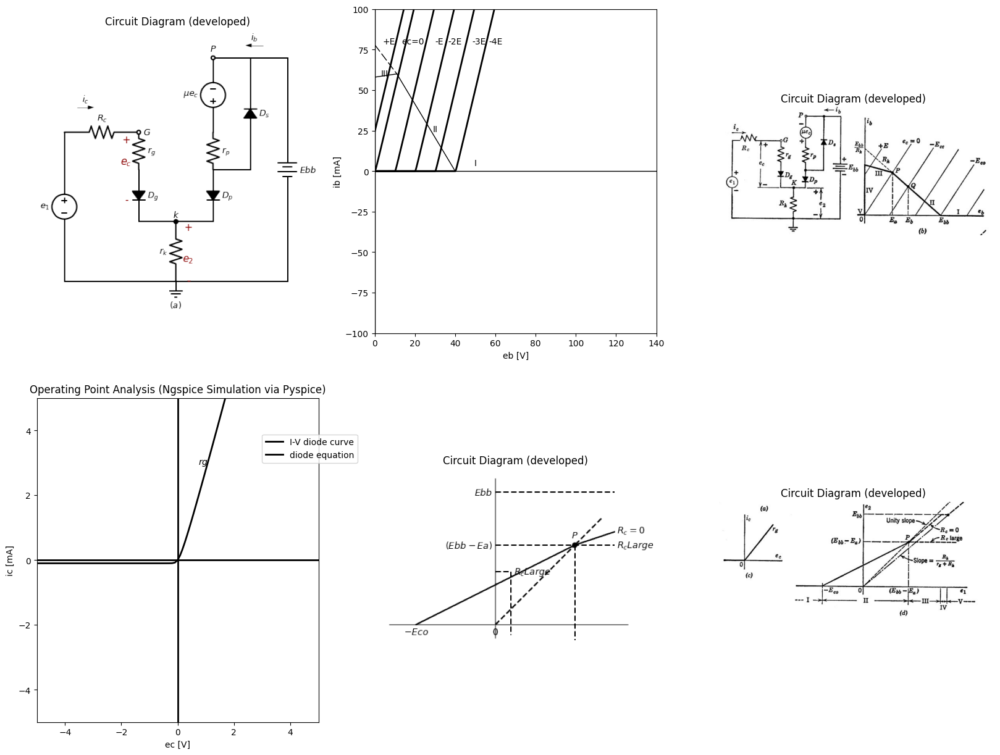

In [27]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*2).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top').dot(open=True).label('$G$','right'))
d +=(R2:= elm.Resistor().down(d.unit*.5).label('$r_g$','bottom'))
d +=(D1:= elm.Diode(fill=True).down(d.unit*.7).label('$D_g$','bottom'))
d += elm.Line().right(d.unit*.5).dot()
d +=(R3:= elm.Resistor().down(d.unit*.8).label('$r_k$','top').label('$k$','right'))
d += elm.Line().left(d.unit*1.5)
d += elm.Line().right(d.unit*.5).at(R3.start)
d +=(D2:= elm.Diode(fill=True).up(d.unit*.7).label('$D_p$','bottom').reverse())
d +=(R2:= elm.Resistor().up(d.unit*.5).label('$r_p$','bottom'))
d += (V2:=elm.SourceV().up(d.unit*1).label('$μe_c$','top').reverse().dot(open=True).label('$P$','right'))
d += elm.Line().right(d.unit*1)
d += (E1 := elm.Battery().down().length(9).label('$E{bb}$','bottom'))
d += elm.Line().left(d.unit*1.5)
d += elm.Line().right(d.unit*.5).at(D2.end)
d +=(D3:= elm.Diode(fill=True).up(d.unit*1.5).label('$D_s$','bottom'))
d += elm.Arrow().right().length(.7).linewidth(0.6).color('black').label('$i_c$').at((.5,7))
d += elm.Arrow().left().length(.7).linewidth(0.6).color('black').label('$i_b$').at((8,9.5))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e_{2}$',' ','-'] , fontsize = 16).color('darkred').at((5,2.6))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e_{c}$',' ',' ','  ','  ','-'] , fontsize = 16).color('darkred').at((2.5,6))
d += elm.Ground().label('$(a)$','bottom').at(R3.end)
d.save('images/6-22a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-22a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2',10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 0@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -20@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -30@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 15@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
axs[0,1].set_xlim(0, 140)
axs[0,1].set_xlabel('eb [V]')
axs[0,1].set_ylabel('ib [mA]')
axs[0,1].set_ylim(-100, 100)
axs[0,1].axhline(0, color='black', linewidth=1)
axs[0,1].axvline(0, color='black', linewidth=1)
axs[0,1].text( 19,80, 'ec=0', ha='center', va='center')
axs[0,1].text( 32, 80, '-E', ha='center', va='center')
axs[0,1].text(40,80, '-2E', ha='center', va='center')
axs[0,1].text(52,80, '-3E', ha='center', va='center')
axs[0,1].text(60,80, '-4E', ha='center', va='center')
axs[0,1].text( 7, 80, '+E', ha='center', va='center')
axs[0,1].plot([40, 11], [0, 60],'black', linewidth=1,linestyle='-')
axs[0,1].plot([0, 11], [78, 60],'black', linewidth=1,linestyle='--',dashes=(10, 3))
axs[0,1].plot([0, 11], [58, 60],'black', linewidth=1,linestyle='-')
axs[0,1].text( 50, 5, 'I', ha='center', va='center')
axs[0,1].text( 30, 26, 'II', ha='center', va='center')
axs[0,1].text( 5, 60, 'III', ha='center', va='center')
img = mpimg.imread('images/6-22a.jpg')
axs[0,2].imshow(img)
axs[0,2].axis('off')  # Hide axes for image display
axs[0,2].set_title('Circuit Diagram (developed)')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.R(2, '2', '3', 100@u_Ohm)
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-5, 5, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=2,linestyle='-')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2) 
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,0].set_xlim(-5, 5)
axs[1,0].set_ylim(-5, 5)
axs[1,0].set_xlabel('ec [V]')
axs[1,0].set_ylabel('ic [mA]')
axs[1,0].text( .9, 3, '$r{g}$', ha='center', va='center')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((1,0)).label('$-Eco$','bottom'))
d += (l4:=elm.Line().right(d.unit*.0003).color('black').at((4,0)).label('$0$','bottom'))
d += (l5:=elm.Line().right(d.unit*.0003).color('black').at((7,3)).label('$P$','top').dot())
d += (l6:=elm.Line().right(d.unit*.0003).color('black').at((8,4)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l3.end,l5.end))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l4.end,l5.end).linestyle('--'))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l6.end,l5.end).linestyle('--'))
d += (l8:=elm.Line().right(d.unit*.0003).color('black').at((8.5,3.5)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l5.end,l8.end).linestyle('-').label('$R_c=0$','right'))
d += (l9:=elm.Line().right(d.unit*1.5).color('black').at((4,3)).linestyle('--').label('$R_c Large$','right').label('$(Ebb-Ea)$','left'))
d += (l10:=elm.Line().right(d.unit*1.5).color('black').at((4,5)).linestyle('--').label('$E{bb}$','left'))
d += (l11:=elm.Line().right(d.unit*.2).color('black').at((4,2)).linestyle('--').label('$R_c Large$','right'))
d += (l12:=elm.Line().down(d.unit*.8).color('black').linestyle('--'))
d += (l13:=elm.Line().down(d.unit*1.2).color('black').at((7,3)).linestyle('--'))
d.save('images/6-22b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-22b1.png')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img = mpimg.imread('images/6-22b.jpg')
axs[1,2].imshow(img)
axs[1,2].axis('off')  # Hide axes for image display
axs[1,2].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

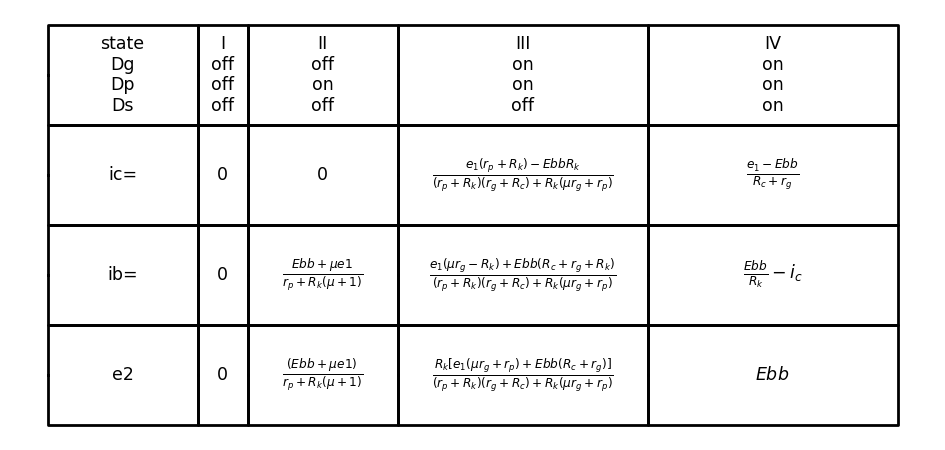

In [28]:
import schemdraw
import schemdraw.elements as elm
from schemdraw import dsp
with schemdraw.Drawing() as d:
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('state\nDg\nDp\nDs'))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('ic=').at((0,-2)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('ib=').at((0,-4)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('e2').at((0,-6)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('I\noff\noff\noff').at((3,0)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('0').at((3,-2)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('0').at((3,-4)))
    d += ( T := dsp.Box(w=1, h=2).anchor('W').fill('white').label('0').at((3,-6)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('II\noff\non\noff').at((4,0)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label('0').at((4,-2)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label(r'$\frac {Ebb+μe1}{r_p+R_k(μ+1)}$').at((4,-4)))
    d += ( T := dsp.Box(w=3, h=2).anchor('W').fill('white').label(r'$\frac {(E{bb}+μe1)}{r_p+R_k(μ+1)}$').at((4,-6)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label('III\non\non\noff').at((7,0)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac{e_1(r_p+R_k)-E{bb}R_k}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$').at((7,-2)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac {e_1(μr_g-R_k)+E{bb}(R_c+r_g+R_k)}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$').at((7,-4)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac {R_k[e_1(μr_g+r_p)+E{bb}(R_c+r_g)]}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$').at((7,-6)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label('IV\non\non\non').at((12,0)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac{e_1-E{bb}}{R_c+r_g}$').at((12,-2)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label(r'$\frac {Ebb}{R_k}-i_c$').at((12,-4)))
    d += ( T := dsp.Box(w=5, h=2).anchor('W').fill('white').label('$E{bb}$').at((12,-6)))
    

## Fig. 6.22. Piecewise-linear analysio of the cathode follower.

cation again results from the use of incremental quantities. We cannot emphasize too often the fact that nonlinear graphical analysis or its substitute, the piecewise-linear approximation, implicitly precedes incremental analysis. The total voltages and currents determine the
 operating region (the diode state in the piecewise-linear model), and on this basis an appropriate incremental model can be chosen.
 
Referring to the tabulation in Fig. 6.22(e), it is apparent that the incremental model for state I is completely trivial, since the triode is effectively removed, whereas the circuit for state IV merely amounts to a resistive voltage divider consisting of $R_c,$ $r_g$, and Rk in series.
The differentials of the expressions for state II lead to the equations relating the incremental components of the variables for negative-grid operation. These equations are given in Fig. 6.23, together with incre-mental circuit models that represent the equations. Symbols el' and e21 are used here to designate incremental quantities. The incremental circuit based on these equations does not represent the output behavior of the circuit, if an external load is connected, because Rk appears as part of the source resistance.
Dividing numerator and denominator of the equations in Fig. 6.23(a) by the quantity (μ + 1) leads to the equations and incremental circuit shown in (b). Since Ek now appears only at the output, this model is reasonable, provided we can justify the modification in apparent plate resistance and source value. Reference to the actual circuit [Fig. 6.21(a)] helps us to visualize the physical basis for a low output re-sistance. Suppose that the circuit is operating in the negative-grid
 
region and that the output voltage is raised an increment$ ∆ e_2$ by con-necting a battery $E_k ± ∆ e_k$ to the output terminals. If $e_1$ is held con-stant, then ec must become more negative by an amount Ack. The net change in voltage across rp must then be


$-r_p∆i_b=∆e_K+μ∆e_K(6.37)$

causing a corresponding decrease in plate current

$ -∆i_b= \frac {∆e_K(1+μ)}{r_p} (6.38)$

The net change in external current in the Ek + Aek battery) is

$ -∆i_b+ \frac {∆e_K}{R_K}=\frac {∆e_K(1+μ)}{r_p}+ \frac {∆e_K}{R_K} (6.39) $


The incremental output resistance is therefore

$ \frac {∆e_K}{-∆i_b+ \frac {∆e_K}{R_K}}= \frac {1}{\frac {(1+μ)}{r_p}+\frac {1}{R_K}}= \frac {R_K (\frac {r_p}{(1+μ)})}{R_K+\frac {r_p}{(1+μ)}}  (6.40)$


An alternate method of calculating output resistance is indicated in Fig. 6.23 (c).


Text(0.5, 1.0, 'Circuit Diagram (developed)')

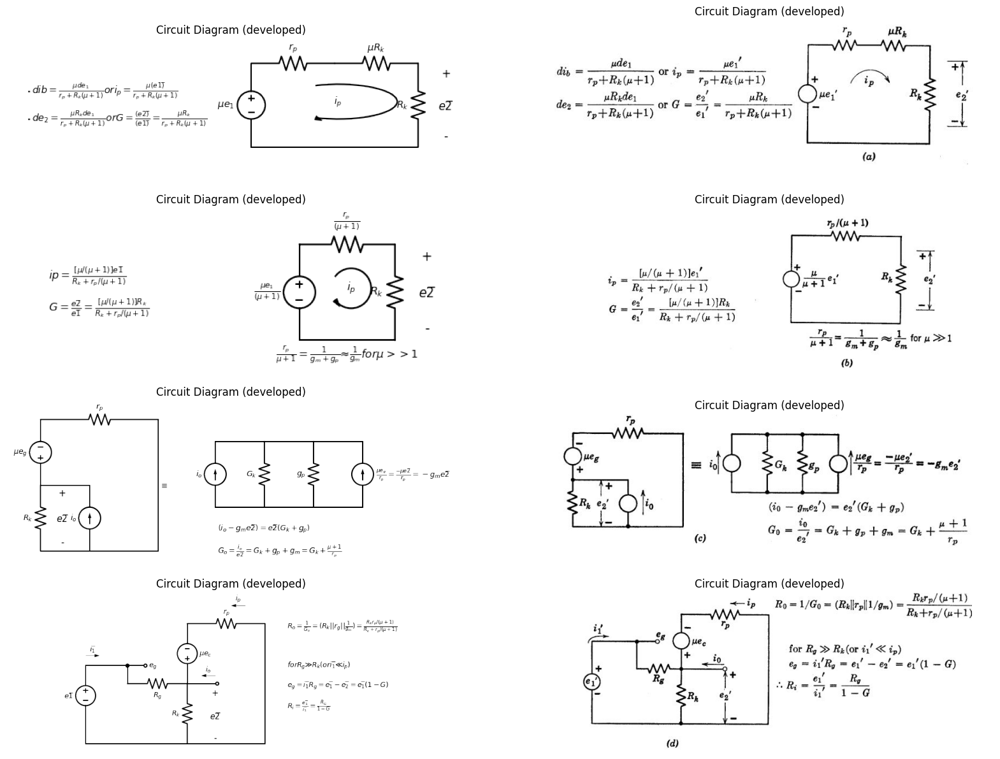

In [34]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.003).color('black').label(r'$d{ib}= \frac{μd{e_1}}{r_p+R_k(μ+1)} or i_p= \frac{μ(e1) ̅}{r_p+R_k(μ+1)}$','right'))
d += (l1:=elm.Line().right(d.unit*.003).color('black').label(r'$d{e_2}= \frac{μR_kd{e_1}}{r_p+R_k(μ+1)} or G=\frac {(e2) ̅}{(e1) ̅}= \frac{μR_k}{r_p+R_k(μ+1)}$','right').at((0,-1)))
d += (V:=elm.SourceV().up(d.unit*1).label('$μe_1$','top').at((8,-2)))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$r_p$','top'))
d +=(R2:= elm.Resistor().right(d.unit*1).label('$μR_k$','top'))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','top'))
d += (l1:=elm.Line().left(d.unit*2).color('black'))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e2 ̅$',' ',' ','-'] , fontsize = 16).color('black').at((15,1))
d += elm.LoopCurrent([V,R1,R2,R3,l1] , pad =- 1).label('$i_p$')
d.save('images/6-23a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-23a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-23a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.003).color('black').label(r'$i{p}= \frac{[μ/(μ+1)]e1 ̅} {R_k+r_p/(μ+1)}$','right'))
d += (l2:=elm.Line().right(d.unit*.003).color('black').label(r'$G= \frac{e2 ̅} {e1 ̅} = \frac{[μ/(μ+1)]R_k} {R_k+r_p/(μ+1)}$','right').at((0,-1)))
d += (V:=elm.SourceV().up(d.unit*1).label(r'$\frac {μe_1}{(μ+1)}$','top').at((8,-2)))
d +=(R1:= elm.Resistor().right(d.unit*1).label(r'$\frac {r_p}{(μ+1)}$','top'))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','top'))
d += (l1:=elm.Line().left(d.unit*1).color('black').label(r'$\frac {r_p}{μ+1}=\frac {1}{g_m+g_p}≈\frac{1}{g_m}for μ>>1$','bottom'))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e2 ̅$',' ',' ','-'] , fontsize = 16).color('black').at((12,1))
d += elm.LoopCurrent([V,R1,R2,R3,l1] , pad =- 1).label('$i_p$')
d.save('images/6-23b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-23b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-23b.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_k$','top'))
d += (V:=elm.SourceV().up(d.unit*1).label('$μe_g$','top').reverse())
d +=(R2:= elm.Resistor().right(d.unit*1.8).label('$r_p$','top'))
d += (l1:=elm.Line().down(d.unit*2).color('black').label('$≡$','bottom'))
d += (l2:=elm.Line().left(d.unit*1.8).color('black'))
d += (l3:=elm.Line().right(d.unit*.75).color('black').at(R1.end))
d += (I1:=elm.SourceI().down(d.unit*1).label('$i_o$','top').reverse())
d += elm.Gap().down().length(3).label(['+',' ',' ','$e2 ̅$',' ',' ','-'] , fontsize = 16).color('black').at((1,3))
d += (I2:=elm.SourceI().up(d.unit*1).label('$i_o$','top').at((8,2)))
d += (l4:=elm.Line().right(d.unit*.75).color('black'))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$G_k$','top'))
d += (l5:=elm.Line().left(d.unit*.75).color('black'))
d += (l6:=elm.Line().right(d.unit*.75).color('black').at(R3.start))
d += (l7:=elm.Line().right(d.unit*.75).color('black').at(R3.end))
d +=(R4:= elm.Resistor().down(d.unit*1).label('$g_p$','top').endpoints(l6.end,l7.end))
d += (l8:=elm.Line().right(d.unit*.75).color('black').at(R4.start))
d += (l9:=elm.Line().right(d.unit*.75).color('black').at(R4.end))
d += (I3:=elm.SourceI().up(d.unit*1).label(r'$\frac {μe_g}{r_p}=\frac {-μe2 ̅}{r_p}=-g_me2 ̅ $','bottom').endpoints(l8.end,l9.end).reverse())
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$(i_o-g_me2 ̅ )=e2 ̅  (G_k+g_p)$','right',color='black').at((8,1)))
d += (l11:=elm.Line().right(d.unit*.003).color('white').label(r'$G_o=\frac {i_o}{e2 ̅ }=G_k+g_p+g_m=G_k+\frac{μ+1}{r_p}$','right',color='black').at((8,0)))
d.save('images/6-23c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-23c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-23c.jpg')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e1 ̅ $','top'))
d += (l1:=elm.Line().right(d.unit*.7).color('black').dot())
d += (l2:=elm.Line().down(d.unit*.3).color('black'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_g$','bottom'))
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_k$','top'))
d += (l2:=elm.Line().left(d.unit*1.7).color('black'))
d += (l3:=elm.Line().up(d.unit*.3).color('black'))
d += (l4:=elm.Line().right(d.unit*.3).color('black').dot(open=True).label('$e_g$','right').at(l1.end))
d += (V2:=elm.SourceV().up(d.unit*1).label(r'$μe_c$','bottom').reverse().at(R2.start))
d +=(R3:= elm.Resistor().right(d.unit*1.3).label('$r_p$','top'))
d += (l5:=elm.Line().down(d.unit*2).color('black'))
d += (l6:=elm.Line().left(d.unit*1.3).color('black'))
d += (l7:=elm.Line().right(d.unit*.5).color('black').dot(open=True).at(R2.start))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e2 ̅$',' ',' ','-'] , fontsize = 16).color('black').at((6.5,2))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$R_o=\frac {1}{G_o}=(R_k||r_g||\frac {1}{g_m})=\frac {R_kr_p/(μ+1)}{R_k+r_p/(μ+1)}$','right',color='black').at((10,5)))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$for R_g≫R_k (ori_1 ̅ ≪i_p)$','right',color='black').at((10,3)))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$e_g=i_1 ̅  R_g= e_1 ̅  -e_2 ̅  =e_1 ̅ (1-G)$','right',color='black').at((10,2)))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$R_i= \frac{e_1 ̅ }{i_1 ̅ }=\frac {R_G}{1-G}$','right',color='black').at((10,1)))
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_1 ̅ $'). at((0,3.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_o$'). at((6.5,2.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_p$'). at((8,6))
d.save('images/6-23d1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-23d1.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-23d.jpg')
axs[3,1].imshow(img)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Circuit Diagram (developed)')

## Fig. 6.23. Incremental analysis of cathode follower for —Ebb/μ < ec < 0 (state II).

For ec less than 0, the incremental input resistance of the cathode-follower circuit is theoretically infinite, since the grid-cathode diode does not conduct. Suppose, however, that a resistance Rg is connected between grid and cathode, as indicated in the incremental circuit shown in Fig. 6.23(d). Let us assume that R9 is much greater than Rk and rp, or that is much less than ip. Then the incremental current will not appreciably affect the gain or other quantities previously calculated for the cathode follower. Since an increment of input voltage el' results in a nearly equal increment in output voltage e2' = Gel', we have

$e_g = e_l' — e'_2 = e'_l(1— G)	(6.41)$

But $e_g, = i'1Rg$; hence the input resistance is

$R_i=e_l'/i_l'=R_g/(1-G) (6.42)$ 


Since G is nearly unity, the input resistance appearing between grid and ground is 14 multiplied by the large factor $1/(1 — G)$. If $R_G$ is connected between the grid and any arbitrary tap point on $R_k$, the effective input resistance is $R_G/(1 — G_t),$ where $G_t$ is the gain from input $e_1'$ to output $e2t'$, with the latter measured between the tap point and ground.
An incremental circuit for positive-grid operation (state III) is shown in Fig. 6.24(a), together with the voltage equations for the two loops of the circuit. The incremental expressions for the currents and the gain
are shown in (b).
The incremental input resistance Ri given in Fig. 6.24(c) can be obtained directly from the first equation in (b). The incremental output resistance is determined by the circuit and equations of Fig. 6.24(d). In making this calculation, the incremental source el/ is set equal to zero, and the circuit is effectively being driven by a current source io.



# 6.15 Properties of the Cathode Follower
The important properties of the cathode follower circuit are its linearity, its low output resistance, and its high input resistance. Although the incremental voltage gain is always less than unity (see Fig. 6.24) the circuit yields power amplification since there is a current gain. The cathode follower is often used as an isolating circuit since it permits a source (even of relatively high internal resistance) to drive a low resistance load without the load reacting on the source.
To make maximum use of the linear range $(0 > e_c >	-E{bb}/μ)$,
the cathode follower can be polarized near $e_c = 0$ for signals that are
essentially negative-going, near $—E{bb}/μ$ for signals that are essentially 
positive-going, and near the center of the range for symmetrical signals 
like sine waves. These possibilities are illustrated in Fig. 6.25. The



Text(0.5, 1.0, 'Circuit Diagram (developed)')

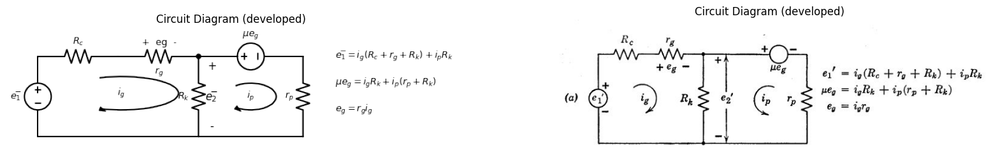

In [35]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_1 ̅ $','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d +=(R2:= elm.Resistor().right(d.unit*1).label('$r_g$','bottom').label('+  eg  -','top').dot())
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','top'))
d += (l1:=elm.Line().left(d.unit*2).color('black'))
d += (V2:=elm.SourceV().right(d.unit*1.3).label(r'$μe_g$','top').at(R3.start).reverse())
d +=(R4:= elm.Resistor().down(d.unit*1).label('$r_p$','top'))
d += (l2:=elm.Line().left(d.unit*1.3).color('black'))
d += elm.Gap().down().length(3).label(['+',' ',' ','$e_2 ̅$',' ',' ','-'] , fontsize = 16).color('black').at((6.5,3))
d += elm.LoopCurrent([V1,R1,R2,R3,l1] , pad =- 1).label('$i_g$')
d += elm.LoopCurrent([R3,V2,R4,l2] , pad =- 1).label('$i_p$')
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$e_1 ̅ =i_g(R_c+r_g+R_k)+i_pR_k$','right',color='black').at((11,3)))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$μe_g=i_gR_k+i_p(r_p+R_k)$','right',color='black').at((11,2)))
d += (l10:=elm.Line().right(d.unit*.003).color('white').label(r'$e_g=r_gi_g$','right',color='black').at((11,1)))
d.save('images/6-24a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-24a1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-24a.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')

(b)  $i_g= \frac {e_1 ̅ .(r_p+R_k)}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$

$i_g= \frac {e_1 ̅ .(r_p-R_k)}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$


(c) $G= \frac {e_2 ̅ }{e_1 ̅ }=\frac {R_k(i_p+i_g)}{e_1 ̅ }=\frac {R_k.(μr_g+r_p)}{(r_p+R_k)(r_g+R_c)+R_k(μr_g+r_p)}$

$R_i=\frac {e_1 ̅ }{i_g}=R_c+r_g+\frac {R_k.(μr_g+r_p)}{r_p+R_k}$

Text(0.5, 1.0, 'Circuit Diagram (developed)')

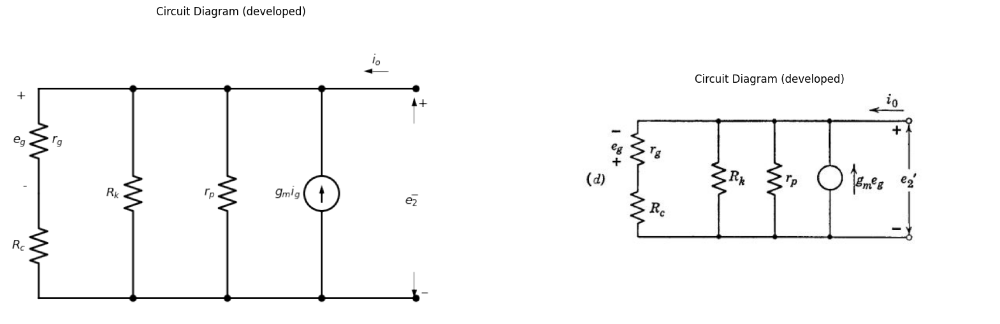

In [37]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_c$','top'))
d +=(R2:= elm.Resistor().up(d.unit*1).label('$r_g$','bottom').label(['-',' ',' ',' ',' ',' ','$e_g$',' ',' ',' ',' ',' ','+']))
d += (l1:=elm.Line().right(d.unit*.9).color('black').dot().at(R2.end))
d += (l2:=elm.Line().right(d.unit*.9).color('black').dot().at(R1.start))
d +=(R3:= elm.Resistor().up(d.unit*1).label('$R_k$','top').endpoints(l1.end,l2.end))
d += (l3:=elm.Line().right(d.unit*.9).color('black').dot().at(R3.end))
d += (l4:=elm.Line().right(d.unit*.9).color('black').dot().at(R3.start))
d +=(R4:= elm.Resistor().up(d.unit*1).label('$r_p$','top').endpoints(l3.end,l4.end))
d += (l5:=elm.Line().right(d.unit*.9).color('black').dot().at(R4.end))
d += (l6:=elm.Line().right(d.unit*.9).color('black').dot().at(R4.start))
d +=(I1:= elm.SourceI().up(d.unit*1).label('$g_mi_g$','top').endpoints(l5.end,l6.end).reverse())
d+= (l7:=elm.Line().right(d.unit*.9).color('black').dot().at(I1.end))
d += (l8:=elm.Line().right(d.unit*.9).color('black').dot().at(I1.start))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2 ̅ $', loc='start', color='black',ofst=0.3). at((11.2,3))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((10.75,5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((10.75,.75))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_o$'). at((10,6.5))
d.save('images/6-24b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-24b1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-24b.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')

$-e_g= \frac {e_2 ̅ r_g}{(r_g+R_c)}; Let G_1={1}{(R_c+r_g)}$

$ i_o-g_me_2 ̅ r_g/(R_c+r_g)=e_2 ̅ ()G_k+g_p+G_1$


$G_o=\frac {i_o}{e_2 ̅ }=\frac {1}{R_o}=\frac {1}{R_k}+\frac {1}{r_p}+\frac {1+g_mr_g}{R_c+r_g}$

## Fig. 6.24. Incremental analysis of cathode follower for ec > 0 (state III).

capacitors are assumed to be so large that they are ideal coupling ele-ments. The determination of R2 for the symmetrical case illustrated in (c) is no different than the corresponding problem for the grounded-cathode circuit. [See graphical constructions of Fig. 6.17(d) and (f).]

Text(0.5, 1.0, 'Circuit Diagram (developed)')

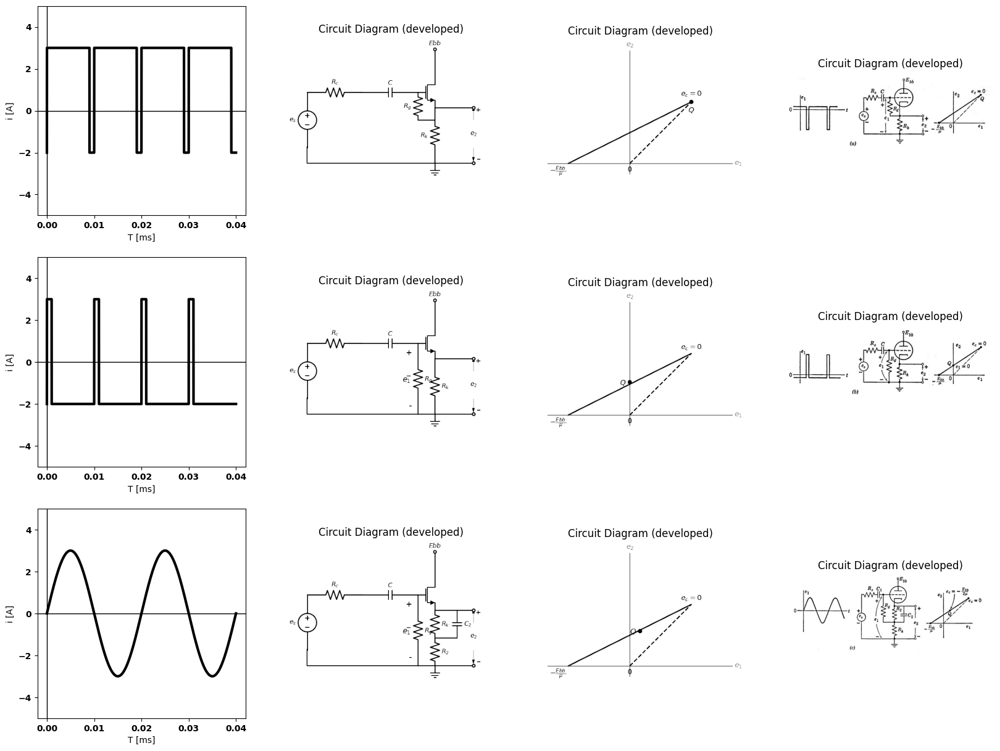

In [54]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 4, figsize=(20, 15))
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=3@u_V, pulse_width=9@u_ms, period=10@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[0,0].plot(analysis.time, analysis['1'], 'black', linewidth=3, label='e 1') 
axs[0,0].set_xlabel('T [ms]')
axs[0,0].set_ylabel('i [A]')
axs[0,0].set_ylim(-5, 5)
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_s$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d +=(C1:= elm.Capacitor().right(d.unit*1).label('$C$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*.5).label('$R_g$','top').at(C1.end))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','top').at(M1.source))
d += (l1:=elm.Line().right(d.unit*.3).color('black').at(R2.end))
d += (l2:=elm.Line().left(d.unit*2.31).color('black').at(R3.end))
d += (l3:=elm.Line().up(d.unit*.3).color('black'))
d += (l4:=elm.Line().up(d.unit*.5).color('black').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l5:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(M1.source))
d += (l6:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(R3.end))
d += elm.Ground().at(R3.end)
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$',color='black',ofst=0.3). at((9.5,-1.5))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((9,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((9,0))
d.save('images/6-25b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25b1.png')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray').label('$e_2$','right'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((1,0)))
d += (l4:=elm.Line().right(d.unit*.0003).color('black').at((4,0)).label('$0$','bottom'))
d += (l5:=elm.Line().right(d.unit*.0003).color('black').at((7,3)).label('$Q$','bottom').dot().label('$e_c=0$','top'))
d += (l6:=elm.Line().right(d.unit*.0003).color('black').at((8,4)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l3.end,l5.end).label(r'$-\frac{Ebb}{μ}$','left'))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l4.end,l5.end).linestyle('--'))
d.save('images/6-25c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25c1.png')
axs[0,2].imshow(img)
axs[0,2].axis('off')  # Hide axes for image display
axs[0,2].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-25a.jpg')
axs[0,3].imshow(img)
axs[0,3].axis('off')  # Hide axes for image display
axs[0,3].set_title('Circuit Diagram (developed)')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=3@u_V, pulse_width=1@u_ms, period=10@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[1,0].plot(analysis.time, analysis['1'], 'black', linewidth=3, label='e 1') 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('i [A]')
axs[1,0].set_ylim(-5, 5)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_s$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d +=(C1:= elm.Capacitor().right(d.unit*1).label('$C$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*1.28).label('$R_g$','bottom').at(C1.end).label(['+',' ',' ','$e_1 ̅$',' ',' ','-'] , fontsize = 16))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','bottom').at(M1.source))
d += (l2:=elm.Line().left(d.unit*2.31).color('black').at(R3.end))
d += (l3:=elm.Line().up(d.unit*.3).color('black'))
d += (l4:=elm.Line().up(d.unit*.5).color('black').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l5:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(M1.source))
d += (l6:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(R3.end))
d += elm.Ground().at(R3.end)
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$',color='black',ofst=0.3). at((9.5,-1.5))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((9,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((9,0))
d.save('images/6-25d1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25d1.png')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray').label('$e_2$','right'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((1,0)))
d += (l4:=elm.Line().right(d.unit*.0003).color('black').at((4,0)).label('$0$','bottom'))
d += (l5:=elm.Line().right(d.unit*.0003).color('black').at((7,3)).label('$e_c=0$','top'))
d += (l6:=elm.Line().right(d.unit*.0003).color('black').at((8,4)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l3.end,l5.end).label(r'$-\frac{Ebb}{μ}$','left'))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l4.end,l5.end).linestyle('--'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((4,1.6)).label('$Q$','left').dot())
d.save('images/6-25e1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25e1.png')
axs[1,2].imshow(img)
axs[1,2].axis('off')  # Hide axes for image display
axs[1,2].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-25b.jpg')
axs[1,3].imshow(img)
axs[1,3].axis('off')  # Hide axes for image display
axs[1,3].set_title('Circuit Diagram (developed)')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.SinusoidalVoltageSource('V1', '1', circuit.gnd, amplitude=3@u_V) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[2,0].plot(analysis.time, analysis['1'], 'black', linewidth=3, label='e 1') 
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('i [A]')
axs[2,0].set_ylim(-5, 5)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray').label('$e_2$','right'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((1,0)))
d += (l4:=elm.Line().right(d.unit*.0003).color('black').at((4,0)).label('$0$','bottom'))
d += (l5:=elm.Line().right(d.unit*.0003).color('black').at((7,3)).label('$e_c=0$','top'))
d += (l6:=elm.Line().right(d.unit*.0003).color('black').at((8,4)))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l3.end,l5.end).label(r'$-\frac{Ebb}{μ}$','left'))
d += (l7:=elm.Line().right(d.unit*.0003).color('black').endpoints(l4.end,l5.end).linestyle('--'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((4.5,1.7)).label('$Q$','left').dot())
d.save('images/6-25g1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25g1.png')
axs[2,2].imshow(img)
axs[2,2].axis('off')  # Hide axes for image display
axs[2,2].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_s$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d +=(C1:= elm.Capacitor().right(d.unit*1).label('$C$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*1.28).label('$R_g$','bottom').at(C1.end).label(['+',' ',' ','$e_1 ̅$',' ',' ','-'] , fontsize = 16))
d +=(R3:= elm.Resistor().down(d.unit*.5).label('$R_k$','bottom').at(M1.source))
d +=(R33:= elm.Resistor().down(d.unit*.5).label('$R_2$','bottom').at(R3.end))
d += (l2:=elm.Line().left(d.unit*2.31).color('black').at(R33.end))
d += (l3:=elm.Line().up(d.unit*.3).color('black'))
d += (l4:=elm.Line().up(d.unit*.5).color('black').dot(open=True).label('$E{bb}$','right').at(M1.drain))
d += (l5:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(M1.source))
d += (l6:=elm.Line().right(d.unit*.7).color('black').dot(open=True).at(R33.end))
d += elm.Ground().at(R33.end)
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$',color='black',ofst=0.3). at((9.5,-1.5))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((9,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((9,0))
d += (l3:=elm.Line().right(d.unit*.4).color('black').at(R33.start))
d +=(C2:= elm.Capacitor().up(d.unit*.5).label('$C_2$','bottom'))
d.save('images/6-25h1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25h1.png')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-25c.jpg')
axs[2,3].imshow(img)
axs[2,3].axis('off')  # Hide axes for image display
axs[2,3].set_title('Circuit Diagram (developed)')

## Fig. 6.25. Polarizing the cathode follower.

# 6.16 General Grid-Driven Triode Circuit
The cathode-follower circuit (grounded plate) and the plate-loaded circuit (grounded cathode) are special cases of a more general circuit with both plate and cathode loads. The circuit is shown schematically in Fig. 6.26(a) with outputs indicated between cathode and ground as well as between plate and ground. A simplified schematic diagram for the circuit is shown in Fig. 6.26(b). The voltages Ebb, e1, e2, and e3 designated at the various terminals are assumed to be measured from ground. Voltages like eb and ec that are not measured from ground must
be designated as before. This form of circuit diagram can, of course, be applied to the cathode follower, the plate-loaded amplifier, transistor circuits, etc. It will be used extensively in subsequent articles and chapters. 


Text(0.5, 1.0, 'Circuit Diagram (developed)')

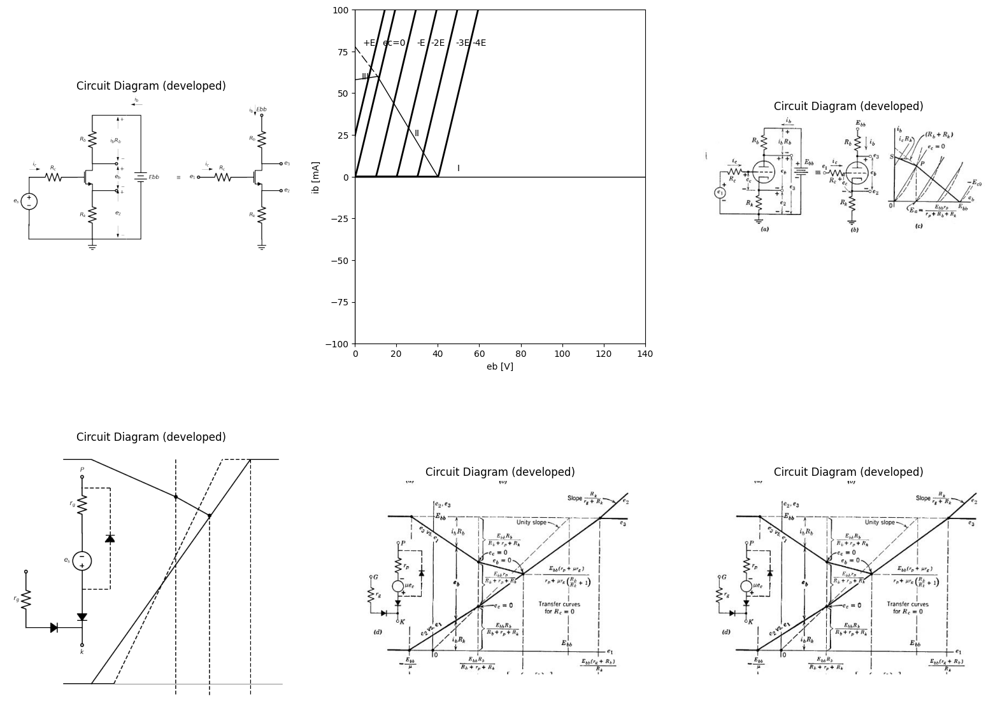

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_s$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_c$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_k$','top').at(M1.source))
d += (l1:=elm.Line().left(d.unit*1.31).color('black'))
d += (l2:=elm.Line().up(d.unit*.31).color('black'))
d +=(R3:= elm.Resistor().up(d.unit*1).label('$R_b$','top').at(M1.drain))
d += (l3:=elm.Line().right(d.unit*1).color('black'))
d += (E1 := elm.Battery().down().length(7.67).label('$E{bb}$','bottom'))
d += (l4:=elm.Line().left(d.unit*1).color('black'))
d += (l5:=elm.Line().right(d.unit*.5).color('black').dot(open=True).at(M1.source))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_b$'). at((7,7.5))
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_c$'). at((0,3.5))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_2$',color='black',ofst=0.3). at((6,-1.5))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,1.5))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.5,0))
d += (l5:=elm.Line().right(d.unit*.5).color('black').dot(open=True).at(M1.drain))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$e_b$',color='black',ofst=0.3). at((6,.75))
d += elm.Arrow().up().length(.5).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,3.2))
d += elm.Arrow().down().length(.5).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.5,2.75))
d += elm.Arrow().up().length(4.5).linewidth(0.6).color('white').label('$i_bR_b$',color='black',ofst=0.3). at((6,3))
d += elm.Arrow().up().length(.75).linewidth(.4).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,6))
d += elm.Arrow().down().length(.75).linewidth(.4).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.5,4.75))
d += (l4:=elm.Line().left(d.unit*0.00001).color('white').at((9,3)).label('$≡$','right',color='black'))
d +=(R4:= elm.Resistor().right(d.unit*1).label('$R_c$','top').idot(open=True).at((10.5,3)).label('$e_1$','left'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(R5:= elm.Resistor().up(d.unit*1).label('$R_b$','top').at(M2.drain).dot(open=True).label('$E{bb}$','right'))
d +=(R6:= elm.Resistor().down(d.unit*1).label('$R_k$','top').at(M2.source))
d += elm.Ground().at(R6.end)
d += elm.Ground().at(R2.end)
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_c$'). at((10.7,3.5))
d += elm.Arrow().down().length(.7).linewidth(.6).color('black').label('$i_b$'). at((14,7.5))
d += (l5:=elm.Line().right(d.unit*0.4).color('black').at(M2.drain).label('$e_3$','right',color='black').dot(open=True))
d += (l6:=elm.Line().right(d.unit*0.4).color('black').at(M2.source).label('$e_2$','right',color='black').dot(open=True))
d.save('images/6-26a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-26a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# circuit 1
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2',10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 0@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -10@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 4
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -20@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 5
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', -30@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 6
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 8.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '4',  circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 10@u_Ohm)
circuit.V('i', '3', '2', 15@u_V)
circuit.V('i1', '3', '4', 10@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
axs[0,1].set_xlim(0, 140)
axs[0,1].set_xlabel('eb [V]')
axs[0,1].set_ylabel('ib [mA]')
axs[0,1].set_ylim(-100, 100)
axs[0,1].axhline(0, color='black', linewidth=1)
axs[0,1].axvline(0, color='black', linewidth=1)
axs[0,1].text( 19,80, 'ec=0', ha='center', va='center')
axs[0,1].text( 32, 80, '-E', ha='center', va='center')
axs[0,1].text(40,80, '-2E', ha='center', va='center')
axs[0,1].text(52,80, '-3E', ha='center', va='center')
axs[0,1].text(60,80, '-4E', ha='center', va='center')
axs[0,1].text( 7, 80, '+E', ha='center', va='center')
axs[0,1].plot([40, 11], [0, 60],'black', linewidth=1,linestyle='-')
axs[0,1].plot([0, 11], [78, 60],'black', linewidth=1,linestyle='--',dashes=(10, 3))
axs[0,1].plot([0, 11], [58, 60],'black', linewidth=1,linestyle='-')
axs[0,1].text( 50, 5, 'I', ha='center', va='center')
axs[0,1].text( 30, 26, 'II', ha='center', va='center')
axs[0,1].text( 5, 60, 'III', ha='center', va='center')
img = mpimg.imread('images/6-26a.jpg')
axs[0,2].imshow(img)
axs[0,2].axis('off')  # Hide axes for image display
axs[0,2].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().down(d.unit*1).label('$r_g$','top').idot(open=True))
d +=(D1:= elm.Diode(fill=True).right(d.unit*1))
d += (l1:=elm.Line().down(d.unit*.31).color('black').dot(open=True).label('$k$','left'))
d +=(D2:= elm.Diode(fill=True).up(d.unit*1).at(l1.end).reverse())
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$e_s$','top').reverse())
d +=(R2:= elm.Resistor().up(d.unit*1).label('$r_g$','top').dot(open=True).label('$P$','right'))
d += (l2:=elm.Line().right(d.unit*.5).color('black').linestyle('--').at(D2.end))
d +=(D3:= elm.Diode(fill=True).up(d.unit*1.8).linestyle('--'))
d += (l3:=elm.Line().left(d.unit*.52).color('black').linestyle('--'))
d += (l4:=elm.Line().right(d.unit*.5).color('black').at((2,-6)))
d += (l5:=elm.Line().right(d.unit*.5).color('black').at((12,6)))
d += (l6:=elm.Line().right(d.unit*.5).color('black').endpoints(l4.end,l5.start))
d += (l7:=elm.Line().right(d.unit*.4).color('black').at(l4.end))
d += (l8:=elm.Line().left(d.unit*.5).color('black').at(l5.start).linestyle('--'))
d += (l9:=elm.Line().left(d.unit*.5).color('black').endpoints(l7.end,l8.end).linestyle('--'))
d += (l10:=elm.Line().right(d.unit*.5).color('black').at((2,6)))
d += (l11:=elm.Line().right(d.unit*.005).color('black').at((8,4)).dot())
d += (l12:=elm.Line().right(d.unit*.005).color('black').at((9.8,3)).dot())
d += (l9:=elm.Line().left(d.unit*.5).color('black').endpoints(l11.end,l12.end))
d += (l9:=elm.Line().left(d.unit*.5).color('black').endpoints(l11.end,l10.end))
d += (l13:=elm.Line().right(d.unit*3).color('black').at(l7.end).linewidth(1))
d += (l14:=elm.Line().down(d.unit*4.2).color('black').at(l5.start).linewidth(2).linestyle('--'))
d += (l15:=elm.Line().down(d.unit*3.2).color('black').at(l12.start).linewidth(2).linestyle('--'))
d += (l16:=elm.Line().down(d.unit*4.2).color('black').at((8,6)).linewidth(2).linestyle('--'))
d.save('images/6-26b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-26b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-26c.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-26c.jpg')
axs[1,2].imshow(img)
axs[1,2].axis('off')  # Hide axes for image display
axs[1,2].set_title('Circuit Diagram (developed)')

## Fig. 6.26. Pieeewise-linear analysis of grid-driven circuit with plate and cathode load.

The piecewise-linear analysis, Fig. 6.26 (d), and the incremental analysis, Fig. 6.27, follow the same pattern as the corresponding analyse in the preceding articles. If we let $Rb = Rk$, then from Fig. 6.27 we see

Text(0.5, 1.0, 'Circuit Diagram (developed)')

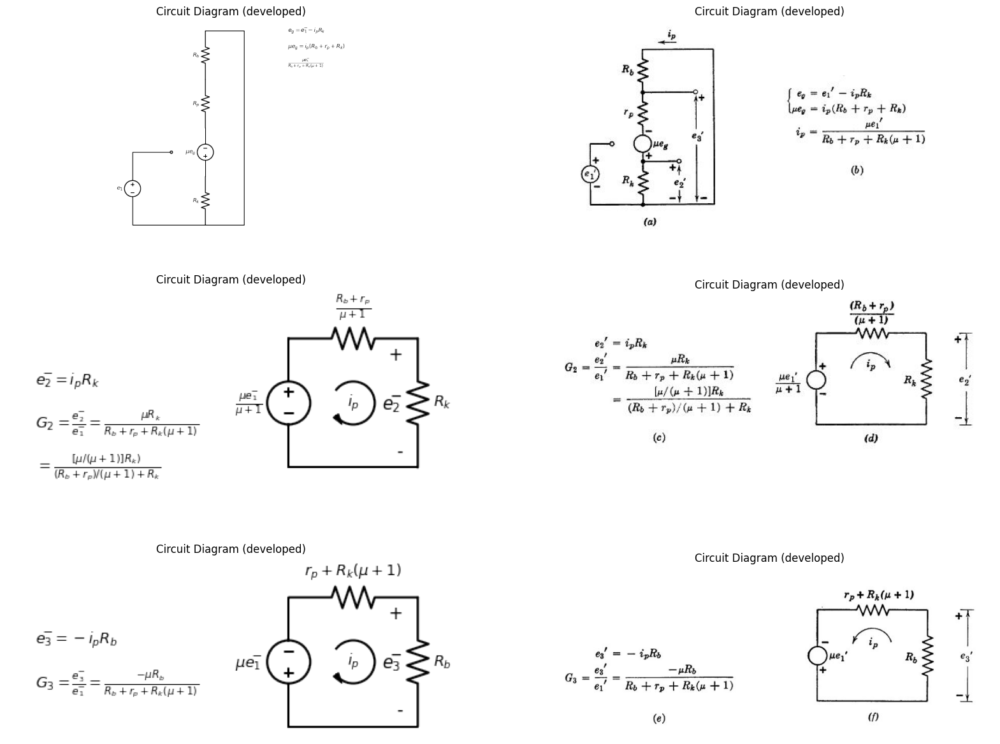

In [12]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().down(d.unit*1).label('$R_b$','top'))
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_p$','top'))
d += (V1:=elm.SourceV().down(d.unit*1).label('$μe_g$','top'))
d +=(R3:= elm.Resistor().down(d.unit*1).label('$R_k$','top'))
d += (l1:=elm.Line().left(d.unit*1.5).color('black'))
d += (V1:=elm.SourceV().up(d.unit*1.5).label('$e_1$','top'))
d += (l1:=elm.Line().right(d.unit*.8).color('black').dot(open=True))
d += (l2:=elm.Line().right(d.unit*.8).color('black').at(R1.start))
d += (l2:=elm.Line().down(d.unit*4).color('black'))
d += (l3:=elm.Line().left(d.unit*.8).color('black'))
d += (l4:=elm.Line().right(d.unit*.0001).color('white').at((5,0)).label(r'$ e_g=e_1 ̅ -i_pR_k$','right',color='black'))
d += (l5:=elm.Line().right(d.unit*.0001).color('white').at((5,-1)).label(r'$ μe_g=i_p(R_b+r_p+R_k)$','right',color='black'))
d += (l6:=elm.Line().right(d.unit*.0001).color('white').at((5,-2)).label(r'$\frac {μe_1 ̅ }{R_b+r_p+R_k(μ+1)}$','right',color='black'))
d.save('images/6-27a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-27a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-27a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.0001).color('white').at((0,0)).label(r'$ e_2 ̅ =i_pR_k$','right',color='black'))
d += (l2:=elm.Line().right(d.unit*.0001).color('white').at((0,-1)).label(r'$ G_2=\frac {e_2 ̅ }{e_1 ̅ }=\frac {μR_k}{R_b+r_p+R_k(μ+1)}$','right',color='black'))
d += (l2:=elm.Line().right(d.unit*.0001).color('white').at((0,-2)).label(r'$ =\frac {[μ/(μ+1)]R_k)}{(R_b+r_p)/(μ+1)+R_k}$','right',color='black'))
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$\frac {μe_1 ̅ }{μ+1}$','top').at((6,-2)))
d +=(R1:= elm.Resistor().right(d.unit*1).label(r'$\frac {R_b+r_p}{μ+1}$','top'))
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_k$','bottom').label(['+',' ',' ','$e_2 ̅$',' ',' ','-'] , fontsize = 16))
d += (l1:=elm.Line().left(d.unit*1).color('black'))
d += elm.LoopCurrent([V1,R1,R2,l1] , pad =- 1).label('$i_p$')
d.save('images/6-27b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-27b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-27b.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.0001).color('white').at((0,0)).label(r'$ e_3 ̅ =-i_pR_b$','right',color='black'))
d += (l2:=elm.Line().right(d.unit*.0001).color('white').at((0,-1)).label(r'$ G_3=\frac {e_3 ̅ }{e_1 ̅ }=\frac {-μR_b}{R_b+r_p+R_k(μ+1)}$','right',color='black'))
d += (V1:=elm.SourceV().up(d.unit*1).label('$ {μe_1 ̅ }$','top').at((6,-2)).reverse())
d +=(R1:= elm.Resistor().right(d.unit*1).label('$r_p+R_k(μ+1)$','top'))
d +=(R2:= elm.Resistor().down(d.unit*1).label('$R_b$','bottom').label(['+',' ',' ','$e_3 ̅$',' ',' ','-'] , fontsize = 16))
d += (l1:=elm.Line().left(d.unit*1).color('black'))
d += elm.LoopCurrent([V1,R1,R2,l1] , pad =- 1).label('$i_p$')
d.save('images/6-27c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-27c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-27c.jpg')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')

## Fig. 6.27. Incremental analysis of circuit with plate and cathode load for ec < 0 (state II).


that G2 equals G3 for e, less than zero. With this choice of element values the circuit is used extensively in audio amplifiers to drive bal¬anced circuits.

Text(0.5, 1.0, 'Circuit Diagram (developed)')

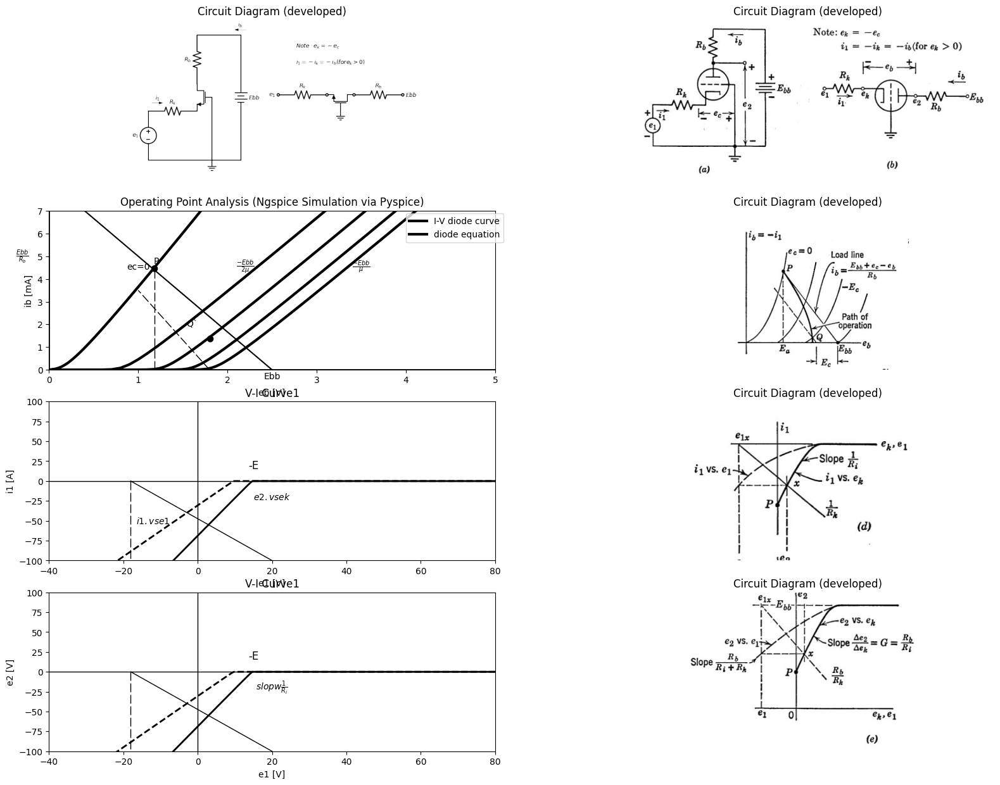

In [23]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label('$e_1$','top'))
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_k$','top'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0))
d +=(R2:= elm.Resistor().up(d.unit*1).label('$R_b$','top').at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.9).color('black'))
d += (E1 := elm.Battery().down().length(7.67).label('$E{bb}$','bottom'))
d += (l2:=elm.Line().left(d.unit*1.9).color('black'))
d += (l3:=elm.Line().down(d.unit*1.28).color('black').at(M1.gate))
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_1$'). at((.2,3.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_b$'). at((6,8))
d +=(R3:= elm.Resistor().right(d.unit*1).label('$R_k$','top').idot(open=True).label('$e_1$','left').at((8,4)).dot(open=True))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(270))
d +=(R4:= elm.Resistor().right(d.unit*1).label('$R_b$','top').idot(open=True).label('$E{bb}$','right').at(M2.drain).dot(open=True))
d += elm.Ground().at(M2.gate)
d += elm.Ground().at(l3.end)
d += (l4:=elm.Line().right(d.unit*.0001).color('white').at((9,7)).label(r'$ Note: e_k=-e_c$','right',color='black'))
d += (l5:=elm.Line().right(d.unit*.0001).color('white').at((9,6)).label(r'$ i_1=-i_k=-i_b(for e_k>0)$','right',color='black'))
d.save('images/6-28a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-28a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-28a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .000000010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-')
circuit = Circuit('thev')

Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', '2', 0.3@u_kOhm )
circuit.V(2, '2', circuit.gnd, 2.5@u_V)


simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 25, 0.1))

axs[1,0].plot(analysis['1'],u_mA(analysis.Vth),'black',linewidth=1.5) 
circuit = Circuit('thev')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2) 
axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[1,0].text( 1, 4.545, 'ec=0', ha='center', va='center')
axs[1,0].text( 2.2, 4.545, r'$\frac {-Ebb}{2μ}$', ha='center', va='center')
axs[1,0].text( 1.8, 1.4, '●', ha='center', va='center')
axs[1,0].text( 1.18, 4.5, '●', ha='center', va='center')
axs[1,0].text( 1.2, 4.8, 'P', ha='center', va='center')
axs[1,0].text( 1.6, 2, 'Q`', ha='center', va='center')
axs[1,0].text( 3.5, 4.545, r'$\frac {-Ebb}{μ}$', ha='center', va='center')
axs[1,0].text( 2.5, -.3, 'Ebb', ha='center', va='center')
axs[1,0].text( -.3, 5, r'$\frac {E{bb}}{R_b}$', ha='center', va='center')
axs[1,0].set_xlim(0, 5)
axs[1,0].set_ylim(0, 7)
axs[1,0].set_xlabel('eb [V]')
axs[1,0].set_ylabel('ib [mA]')
axs[1,0].plot([1.18, 1.18], [0, 4.5],'black', linewidth=1,linestyle='--',dashes=(10, 3))
axs[1,0].plot([1.8, 1], [0, 3.5],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img = mpimg.imread('images/6-28c.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .20@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 10@u_V)
circuit.R(1, '2','3' , .30@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[2,0].annotate('-E', xy=(15, 0), xytext=(0, 14),
textcoords='offset points', ha='center', color='black', fontsize=12, fontweight='medium')
axs[2,0].set_title('V-I Curve1')
axs[2,0].set_xlim(-40, 80)
axs[2,0].set_xlabel('e1 [V]')
axs[2,0].set_ylabel('i1 [A]')
axs[2,0].set_ylim(-100, 100)
axs[2,0].text( 20, -20, r'$e2.vs ek$', ha='center', va='center')
axs[2,0].text( -12, -50, r'$i1.vs e1$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
axs[2,0].plot([-18, 20], [0, -100],'black', linewidth=1,linestyle='-')
axs[2,0].plot([-18, -18], [0, -100],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img = mpimg.imread('images/6-28d.jpg')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .20@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 10@u_V)
circuit.R(1, '2','3' , .30@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[3,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[3,0].annotate('-E', xy=(15, 0), xytext=(0, 14),
textcoords='offset points', ha='center', color='black', fontsize=12, fontweight='medium')
axs[3,0].set_title('V-I Curve1')
axs[3,0].set_xlim(-40, 80)
axs[3,0].set_xlabel('e1 [V]')
axs[3,0].set_ylabel('e2 [V]')
axs[3,0].set_ylim(-100, 100)
axs[3,0].text( 20, -20, r'$slopw\frac {1}{R_i}$', ha='center', va='center')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].plot([-18, 20], [0, -100],'black', linewidth=1,linestyle='-')
axs[3,0].plot([-18, -18], [0, -100],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img = mpimg.imread('images/6-28e.jpg')
axs[3,1].imshow(img)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Circuit Diagram (developed)')

## Fig. 6.28. Grounded-grid amplifier.

# 6.17 Grounded-Grid Amplifier
The grounded-grid amplifier shown in Fig. 6.28(a) and (b) can also be described as a cathode-driven triode with plate load. For negative-grid operation, we see from Fig. 6.28(5) that

$eb = Ebb — ek-ibRb	(6.43)$

Solving this equation for 4 we obtain

$i_b=(E{bb}	-ek	-eb)/Rb	(6.44)$

or

$i_b= (E{bb} + e_c -e_b)i Rb	(6.45)$

Equation 6.45 can be plotted on the 4 vs. eb plane, as indicated in Fig. 6.28(c). Note that the load-line moves as ec is varied. For $e_c = 0,$ the operating point P is determined by the solid load-line. For $e_c = —E_c(ek =E_c)$ the operating point is at Q, as indicated by the dotted load-line. The path of operation, shown by the heavy line, is the locus of intersections of the tube curves with load-lines that shift to the left as ec is made more negative.
Since $i_b=-i_1$this locus of the operating point can be replotted as
$i_1$vs.$ e_k$. The plot of $i_1$ VS.$e_ k$, shown in Fig. 6.28(d), represents the driving-point relation for the circuit. The slope of the curve determines the incremental resistance at the cathode terminal:


$R_i=∆e_k/∆ i_1 (6.46)$

The resistance between the input terminal and ground is merely the sum of $R_i$ and $R_k$.
The transfer curve (e2 vs. ek) shown in Fig. 6.28(e) is related to the input curve by the linear equation


$e_2=E{bb}+i_1R_b(6.47)$

The gain $G2k = de_2/de_k$ is slightly higher than the corresponding gain
 
$G{2c} = de_2/de_c$, for a grounded-cathode amplifier, assuming the same tube, load resistance, and operating point. This fact may be seen from Fig. 6.28(c), where a given change of e, produces a slightly larger change n ib along the $PQ$ locus than along the load-line.
The incremental form of Eq. 6.47 is

$∆e_2=∆i_1R_b (6.48)$

Solving Eqs. 6.46 and 6.48 for $∆e_2/∆e_k$ yields



Equation 6.49 indicates that if $G2k = 10 $and $Rb = 10k$, then Ri = 1k, We see, therefore, that the grounded-grid connection exhibits a relatively low incremental input resistance.
If the cathode voltage ek is produced by a source el driving the circuit through a resistance $R_k$, the transfer curve of interest is $e_2$ vs. $e_l$. From the circuit diagram of Fig. 6.28 (a) or (b), we see that

$e_1=e_k+i_1R_K (6.50)$

Equation 6.50 is plotted on the $i_1 vs. e_k$ plane in Fig. 6.28(d), The intersection x with the input curve relates e1 to ek and therefore also relates e2 to e1, since the transfer curve in Fig. 6,25(e) relates e2 to ek. Since the input, and transfer curves have the same general shape, this

Text(0.5, 1.0, 'Circuit Diagram (developed)')

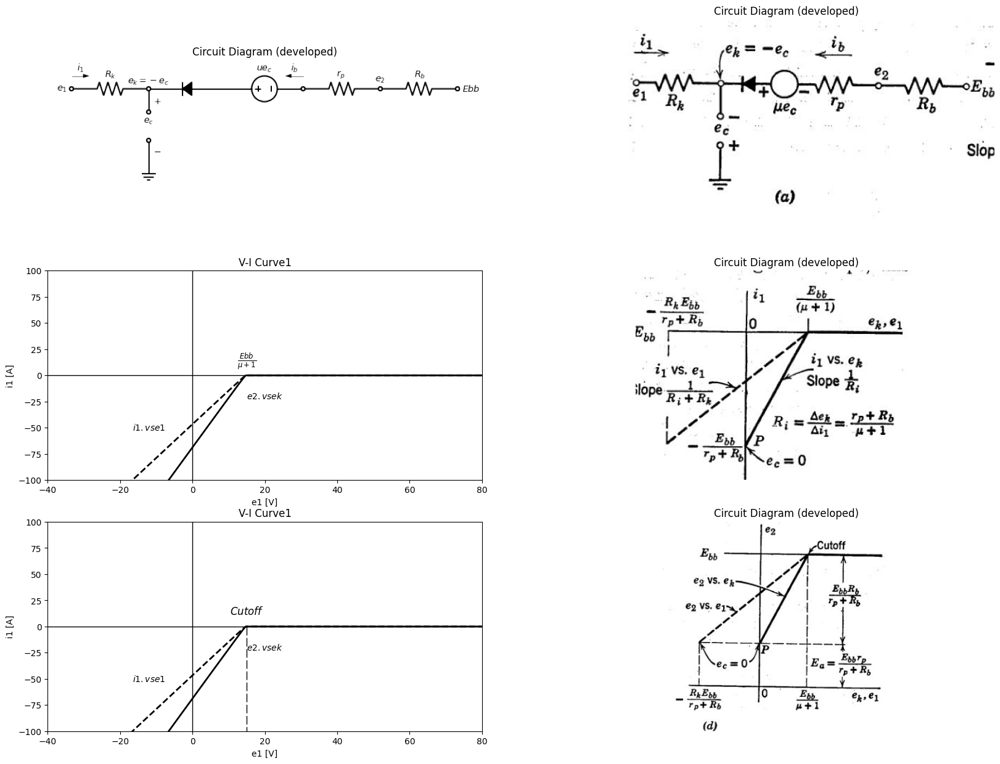

In [30]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_k$','top').idot(open=True).label('$e_1$','left').dot(open=True))
d +=(D1:= elm.Diode(fill=True).right(d.unit*1).reverse())
d +=(R2:= elm.Resistor().right(d.unit*1).label('$r_p$','top').idot(open=True).at(V1.end))
d += (l1:=elm.Line().right(d.unit*.000031).color('black').dot(open=True).label('$e_2$','top'))
d +=(R2:= elm.Resistor().right(d.unit*1).label('$E{bb}$','right').dot(open=True).label('$R_b$','top'))
d += (l2:=elm.Line().down(d.unit*.3).color('black').dot(open=True).label('$e_c$','left').label('$e_k=-e_c$','right').label('$+$','bottom').at(R1.end))
d += (l3:=elm.Line().down(d.unit*.3).color('black').idot(open=True).label('$-$','bottom').at((3,-2)))
d += elm.Ground().at(l3.end)
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_1$'). at((0,.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_b$'). at((9,.5))
d += (V1:=elm.SourceV().right(d.unit*1).label('$ue_c$','top').at(D1.end).reverse())
d.save('images/6-29a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-29a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-29a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .20@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .30@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[1,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[1,0].annotate(r'$\frac {E{bb}}{μ+1}$', xy=(15, 0), xytext=(0, 14),
textcoords='offset points', ha='center', color='black', fontsize=12, fontweight='medium')
axs[1,0].set_title('V-I Curve1')
axs[1,0].set_xlim(-40, 80)
axs[1,0].set_xlabel('e1 [V]')
axs[1,0].set_ylabel('i1 [A]')
axs[1,0].set_ylim(-100, 100)
axs[1,0].text( 20, -20, r'$e2.vs ek$', ha='center', va='center')
axs[1,0].text( -12, -50, r'$i1.vs e1$', ha='center', va='center')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img = mpimg.imread('images/6-29b.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .20@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .30@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[2,0].annotate(r'$Cutoff$', xy=(15, 0), xytext=(0, 14),
textcoords='offset points', ha='center', color='black', fontsize=12, fontweight='medium')
axs[2,0].set_title('V-I Curve1')
axs[2,0].set_xlim(-40, 80)
axs[2,0].set_xlabel('e1 [V]')
axs[2,0].set_ylabel('i1 [A]')
axs[2,0].set_ylim(-100, 100)
axs[2,0].text( 20, -20, r'$e2.vs ek$', ha='center', va='center')
axs[2,0].text( -12, -50, r'$i1.vs e1$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
axs[2,0].plot([15, 15], [0, -100],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img = mpimg.imread('images/6-29c.jpg')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')

$e_1=e_k+i_1R_k$

$e_c=-e_k$

$i_1=-i_b.since i_c=0 for e_c<0$

$E{bb}= i_b(R_b+r_p)-μec+e_k$

$= i_b(R_b+r_p)-+(μ+1)e_k$


$R_i=\frac {∆e_k}{∆i_1}=\frac{r_p+R_b}{μ+1}$

$G{2k}=\frac {∆e_2}{∆e_k}=\frac{(μ+1)R_b}{r_p+R_b}=\frac {R_b}{R_i}$

$G{21}=\frac {∆e_2}{∆e_1}=\frac{(μ+1)R_b}{r_p+R_b+R_k(μ+1)}$


$=\frac {R_i}{R_i+R_k}.\frac {(μ+1)R_b}{r_p+R_b}=G{2k}\frac {R_i}{R_i+R_k}$

$= \frac {R_b}{R_i+R_k}$

## Fig. 6.29. Piecewiae-linear analysis of grounded-grid circuit for ec < 0.

source line can be trangferred directly to the 62 vs. ek plane, where its 
slope is determined by RbiRk, and et is its intercept on the line 62 — Ebb- 
Reference to the curves shown in Fig. 6.28 (d) and (e) shows, for a 
given operating point, that the incremental gains are related as follows:

$G{k1}= de_k/de_1 =R_i/(R_i+ R_k)	(6.51)$

and

$G{2k }= de_2/de_k = R_b/R_i	(6.52)$

Therefore
 
A piecewise-linear model of a grounded-grid amplifier, applicable in the negative-grid region (ec < 0), is shown in Fig. 6.29 (a), Inspection of this circuit yields the equations given in (b). Application of the break¬point method of analysis leads directly to the driving-point curve plotted in (c) and the voltage transfer curve given in (d).
The incremental quantities given in rig. 6.29 (e) are for state II which is determined by the conditions


$E{bb}/(1+μ)>e_k>0 (6.54)$



These limits on state II are readily determined from the dimensions of the curves in (c) and (d). Note particularly the fact that the circuit has a very low input resistance which. enters directly into the expression for incremental voltage gain.
Although the grounded-grid amplifier requires driving power at the input terminals, the input signal controls a much larger incremental power variation in the load. Because the input and load currents are identical (for ec < 0), the ratio of incremental output power to incre-mental input power is numerically equal to the voltage gain Gp = G21
The more general piecewise-linear model for the grounded-grid circuit shown in Fig. 6.30(a) applies to both the negative-grid and the positive-grid regions. The equations given in (b) are written for e, greater than O.
 
The transfer curve e2 vs. ek, plotted in Fig_ 6.30(c), shows the negative-grid behavior in dashed lines.
The grounded-grid circuit is less widely used than the grounded-cathode or grounded-anode (cathode follower) circuits. It is used in the input stage of the intermediate-frequency amplifier of many receivers. It is also used in high-frequency amplifier circuits where the grounded grid provides a natural isolation between input and output circuits. The electrostatic shielding action of a grounded grid is discussed further in Chapter 7.
In conjunction with a cathode-follower, the grounded-grid circuit forms a commonly used two-triode circuit called a cathode-coupled amplifier. This circuit is widely used as an inverting amplifier and as the basis for a relaxation oscillator called the cathode-coupled multi-vibrator.
# 6.18 Direct-coupled Grounded-Cathode Circuits
The basic circuits discussed above can be coupled together in a variety of ways when more than one triode is to be used. A few of the possible two-triode configurations will be described here and in succeeding articles.


Text(0.5, 1.0, 'Circuit Diagram (developed)')

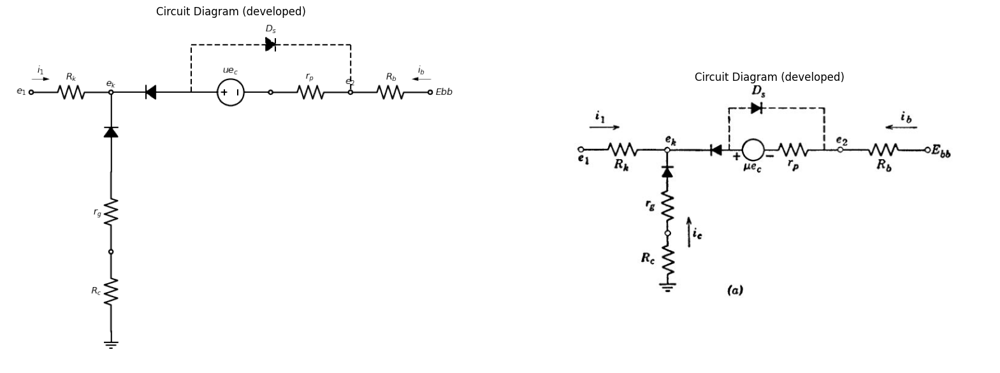

In [32]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().right(d.unit*1).label('$R_k$','top').idot(open=True).label('$e_1$','left').dot(open=True))
d +=(D1:= elm.Diode(fill=True).right(d.unit*1).reverse())
d +=(R2:= elm.Resistor().right(d.unit*1).label('$r_p$','top').idot(open=True).at(V1.end))
d += (l1:=elm.Line().right(d.unit*.000031).color('black').dot(open=True).label('$e_2$','top'))
d +=(R2:= elm.Resistor().right(d.unit*1).label('$E{bb}$','right').dot(open=True).label('$R_b$','top'))
d +=(D2:= elm.Diode(fill=True).down(d.unit*1).reverse().at(R1.end).label('$e_k$','right'))
d +=(R3:= elm.Resistor().down(d.unit*1).dot(open=True).label('$r_g$','top'))
d +=(R4:= elm.Resistor().down(d.unit*1).label('$R_c$','top'))
d += elm.Ground().at(R4.end)
d += elm.Arrow().right().length(.7).linewidth(.6).color('black').label('$i_1$'). at((0,.5))
d += elm.Arrow().left().length(.7).linewidth(.6).color('black').label('$i_b$'). at((15,.5))
d += (V1:=elm.SourceV().right(d.unit*1).label('$ue_c$','top').at(D1.end).reverse())
d += (l3:=elm.Line().up(d.unit*.6).color('black').linestyle('--').at(D1.end))
d +=(D3:= elm.Diode(fill=True).right(d.unit*2).label('$D_s$','top').linestyle('--'))
d += (l4:=elm.Line().down(d.unit*.6).color('black').linestyle('--'))
d.save('images/6-30a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-30a1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-30a.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')

$$i_1= -(i_b+i_c); $$

$$e_c=i_cr_g $$

$$e_1=-i_b.R_k-i_c(r_g+R_k+R_c)$$

$$E{bb}=i_b(R_b+r_p)-i_c(R_c+r_g)-ue_c $$

$$ = i_b(r_p+R_b)-i_c[R_c+r_g(u+1)]$$

Text(0.5, 1.0, 'Circuit Diagram (developed)')

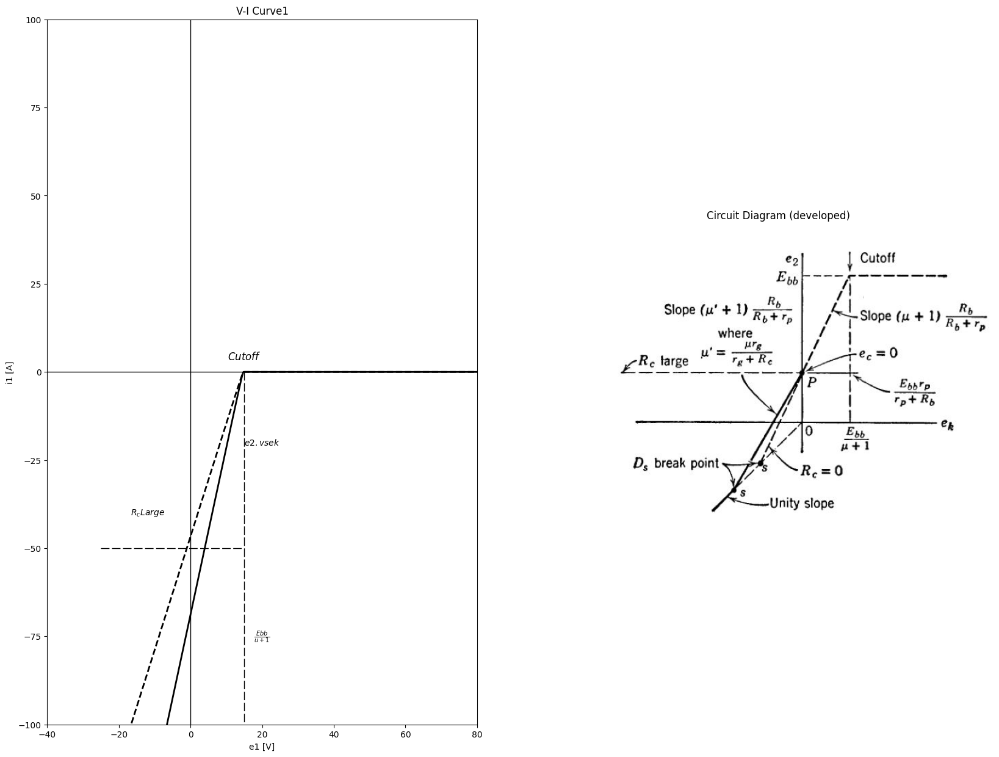

In [35]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .20@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2)
# circuit 2 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 1000@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 0.01@u_kOhm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','1' , model = 'BAV21')
circuit.V(1, '3',circuit.gnd , 15@u_V)
circuit.R(1, '2','3' , .30@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-40, 100, 0.1))
axs[0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=2,linestyle='--')
axs[0].annotate(r'$Cutoff$', xy=(15, 0), xytext=(0, 14),
textcoords='offset points', ha='center', color='black', fontsize=12, fontweight='medium')
axs[0].set_title('V-I Curve1')
axs[0].set_xlim(-40, 80)
axs[0].set_xlabel('e1 [V]')
axs[0].set_ylabel('i1 [A]')
axs[0].set_ylim(-100, 100)
axs[0].text( 20, -20, r'$e2.vs ek$', ha='center', va='center')
axs[0].text( 20, -75, r'$\frac {Ebb}{u+1}$', ha='center', va='center')
axs[0].text( -12, -40, r'$R_c Large$', ha='center', va='center')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
axs[0].plot([15, 15], [0, -100],'black', linewidth=1,linestyle='--',dashes=(10, 3))
axs[0].plot([-25, 15], [-50, -50],'black', linewidth=1,linestyle='--',dashes=(10, 3))
img = mpimg.imread('images/6-30b.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')

## Fig. 6.30. Piecewisc-linear analysis of grounded-grid circuit for ec > O.


In this chapter, we shall restrict ourselves to interstage coupling net-works that involve only resistive circuit elements: namely, resistances, batteries, and diodes. Such circuits are said to be direct-coupled, since they respond to frequencies down to and including zero  in other words, they can be used to amplify d-c as well as a-c signals. The assumption of "ideal coupling" by a large capacitor, as mentioned in Article 6.11, does
not apply for d-c voltages. The use of energy-storage elements for inter-stage coupling is discussed in Chapter 8.
One of the main reasons for using two or more triodes or other electronic devices) in a circuit is to obtain greater amplification than a single triode can supply. The particular combination of basic single-triode circuits chosen for this purpose usually depends upon factors other than amplification. Among these may be linearity, dynamic range, input resistance, output resistance, interchangeability of triodes, etc.
A simple two-triode circuit is shown in Fig, 6.31(a). It consists of two plate-loaded, grounded-cathode circuits coupled together by means of a battery E. The transfer curve en vs. el for the first triode circuit, shown in (b), assumes the battery E to be disconnected. The transfer curve e2 vs. ec2 for the second circuit alone is similar in form and is shown in (c).
Since the maximum value of em is Ebb, the maximum value of ea is (Ebb — E) when the two circuits are coupled together. If we choose E equal to Ebb, then the maximum value of 6,2 is equal to zero, a con¬venient choice for preliminary consideration, since the second circuit never loads the first one. Thus, the curve of e,2 vs, ei shown in (d) is the same as (b) with a change in reference level. The over-all transfer curve ec2 vs. el, plotted in (e), is obtained from the curves in (c) and (d).

The break point P corresponds to plate-current cutoff in the first triode, and Q corresponds to cutoff in the second. The choice of a grid-polariz¬ing voltage E that avoids the grid-current states of both of the triodes is highly desirable because i and rp are more nearly constant in the nega¬tive-grid region. Thus, selecting the voltage E in this manner favors Tin earity in the amplification state of the circuit (both triodes con¬ducting plate current) and yields good clipping (due to cutoff).
A variation of this circuit is shown in Fig. 6.32(a). If we again wish to have zero as the maximum excursion of ec, as in the previous circuit, we require that Ecc/Rg equal Ebb/R, assuming Rb1 is much. less than R. The individual transfer curves eb1 vs. el and e2 vs. ec2 are the same as those shown in Fig. 6.31 (b) and (c), However, in this case there is a loss of amplification in going from the plate of the first triode to the grid of the second


$\frac {∆ec2}{∆eb1}	=A=R_g/(R_g+R) (6.55)$

The over-all transfer curve is shown in Fig. 6.32(0 with break points and slopes dimensioned. The over-all gain of this amplifier in the range between break points $P$ and $Q$ is $G1G2A$, where $G_1$ and $G_2$ are the gains of the individual stages and A is the resistive attenuation. These values
apply for signal frequencies su_fficiently low to permit omission of the 
effects of interelectrode capacitances. The inadequacy of resistive-


Text(0.5, 1.0, 'Circuit Diagram (developed)')

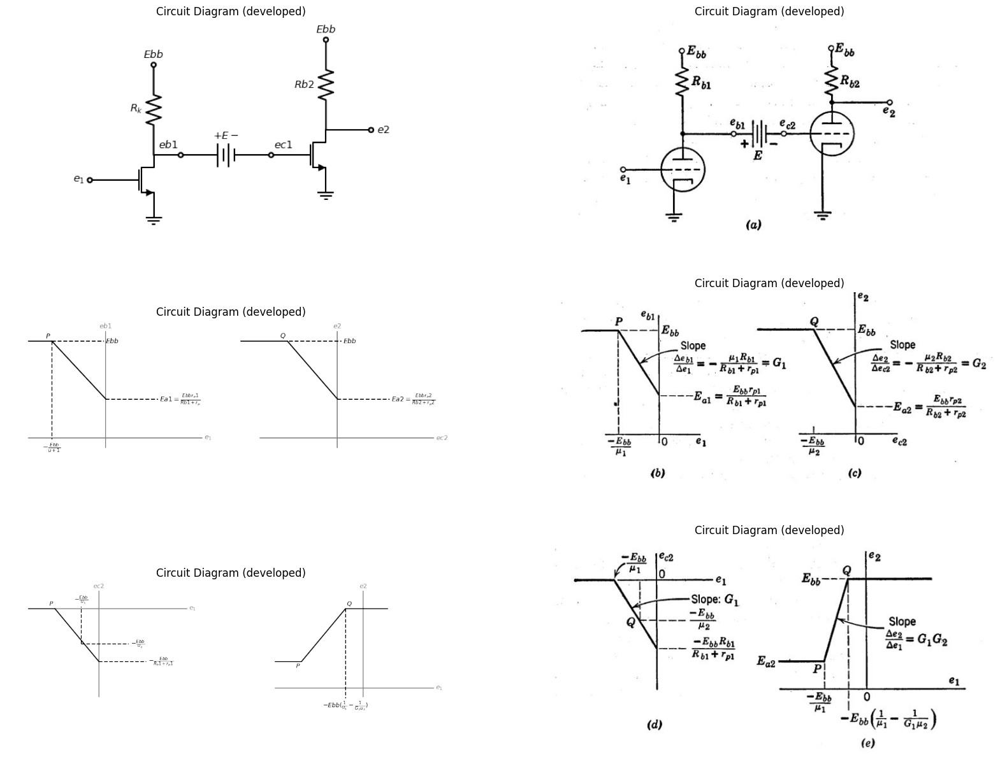

In [40]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.4).color('black').idot(open=True).label('$e_1$','left'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += elm.Ground().at(M1.source)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_k$','top').label('$E{bb}$','right').dot(open=True).at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.3).color('black').dot(open=True).label('$e{b1}$','top').at(M1.drain))
d += (E1:=elm.Battery().right(d.unit*1).label('$+ E -$','top'))
d += (l1:=elm.Line().right(d.unit*.3).color('black').idot(open=True).label('$e{c1}$','top'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += elm.Ground().at(M2.source)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R{b2}$','top').label('$E{bb}$','right').dot(open=True).at(M2.drain))
d += (l1:=elm.Line().right(d.unit*.5).color('black').dot(open=True).label('$e{2}$','right').at(M2.drain))
d.save('images/6-31a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-31a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-31a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-.5)).color('gray').label('$e{b1}$','right'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((4,2)))
d += (l4:=elm.Line().right(d.unit*.4).color('black').at((0,5)))
d += (l5:=elm.Line().right(d.unit*.00003).color('black').endpoints(l3.end,l4.end).label('$P$','left'))
d += (l6:=elm.Line().down(d.unit*1.7).color('black').at((1.2,5)).linestyle('--').label(r'$-\frac{Ebb}{u+1}$','left'))
d += (l6:=elm.Line().right(d.unit*.9).color('black').at((1.2,5)).linestyle('--').label('$E{bb}$','right'))
d += (l6:=elm.Line().right(d.unit*.9).color('black').at((4,2)).linestyle('--').label(r'$E{a1}=\frac{Ebbr_p1}{R{b1}+r_p}$','right'))
d += (l7:=elm.Line().right(d.unit*3).color('gray').label('$e{c2}$','right').at((12,0)))
d += (l8:=elm.Line().up(d.unit*2).at((16,-.5)).color('gray').label('$e{2}$','right'))
d += (l9:=elm.Line().right(d.unit*.00003).color('black').at((16,2)))
d += (l10:=elm.Line().right(d.unit*.8).color('black').at((11,5)))
d += (l5:=elm.Line().right(d.unit*.00003).color('black').endpoints(l10.end,l9.end).label('$Q$','left'))
d += (l11:=elm.Line().right(d.unit*.9).color('black').at((13.5,5)).linestyle('--').label('$E{bb}$','right'))
d += (l6:=elm.Line().right(d.unit*.9).color('black').at((16,2)).linestyle('--').label(r'$E{a2}=\frac{Ebbr_p2}{R{b2}+r_p2}$','right'))
d.save('images/6-31b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-31b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-31b.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right'))
d += (l2:=elm.Line().up(d.unit*2).at((4,-5)).color('gray').label('$e{c2}$','right'))
d += (l3:=elm.Line().right(d.unit*.00003).color('black').at((4,-3)))
d += (l4:=elm.Line().right(d.unit*.5).color('black').at((0,0)))
d += (l5:=elm.Line().right(d.unit*.00003).color('black').endpoints(l3.end,l4.end).label('$P$','left'))
d += (l6:=elm.Line().right(d.unit*.9).color('black').at((4,-3)).linestyle('--').label(r'$-\frac{E{bb}}{R_b1+r_p1}$','right'))
d += (l7:=elm.Line().right(d.unit*.9).color('black').at((3,-2)).linestyle('--').label(r'$-\frac{E{bb}}{u_2}$','right'))
d += (l8:=elm.Line().up(d.unit*.7).color('black').at((3,-2)).linestyle('--').label(r'$-\frac{E{bb}}{u_1}$','right'))
d += (l9:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right').at((14,-4.5)))
d += (l10:=elm.Line().up(d.unit*2).at((19,-5)).color('gray').label('$e{2}$','right'))
d += (l11:=elm.Line().right(d.unit*.5).color('black').at((14,-3)))
d += (l12:=elm.Line().right(d.unit*.8).color('black').at((18,0)))
d += (l5:=elm.Line().right(d.unit*.00003).color('black').endpoints(l11.end,l12.start).label('$Q$','right').label('$P$','left'))
d += (l8:=elm.Line().down(d.unit*1.7).color('black').at((18,0)).linestyle('--').label(r'$-Ebb(\frac{1}{u_1}-\frac{1}{G_2u_2})$','left'))
d.save('images/6-31c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-31c1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-31c.jpg')
axs[2,1].imshow(img)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Circuit Diagram (developed)')

## Fig. 6.31. Direct-coupled grounded-cathode circuits.

circuit models for representing high-frequency circuit behavior is considered in Chapter 8.

Text(0.5, 1.0, 'Circuit Diagram (developed)')

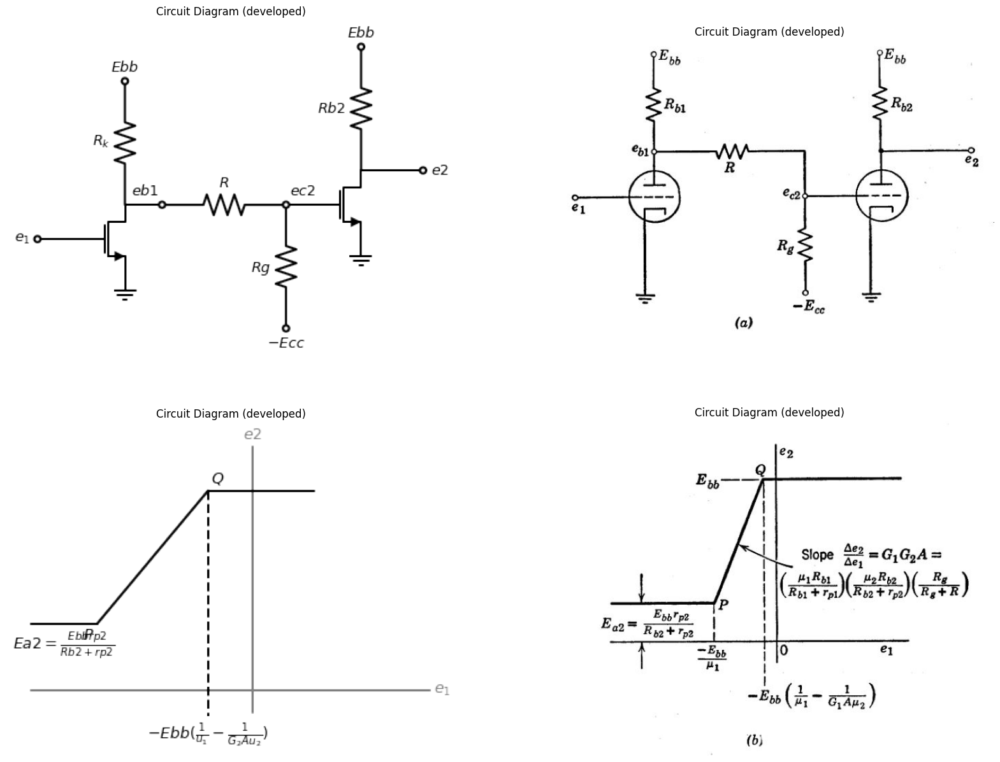

In [43]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (l1:=elm.Line().right(d.unit*.4).color('black').idot(open=True).label('$e_1$','left'))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += elm.Ground().at(M1.source)
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_k$','top').label('$E{bb}$','right').dot(open=True).at(M1.drain))
d += (l1:=elm.Line().right(d.unit*.3).color('black').dot(open=True).label('$e{b1}$','top').at(M1.drain))
d +=(R2:= elm.Resistor().right(d.unit*1).label('$R$','top'))
d += (l1:=elm.Line().right(d.unit*.3).color('black').idot(open=True).label('$e{c2}$','top'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d += elm.Ground().at(M2.source)
d +=(R3:= elm.Resistor().up(d.unit*1).label('$R{b2}$','top').label('$E{bb}$','right').dot(open=True).at(M2.drain))
d += (l1:=elm.Line().right(d.unit*.5).color('black').dot(open=True).label('$e{2}$','right').at(M2.drain))
d +=(R4:= elm.Resistor().down(d.unit*1).label('$R{g}$','top').label('$-E{cc}$','left').dot(open=True).at(R2.end))
d.save('images/6-32a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-32a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-32a.jpg')
axs[0,1].imshow(img)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (l9:=elm.Line().right(d.unit*3).color('gray').label('$e_1$','right').at((14,-4.5)))
d += (l10:=elm.Line().up(d.unit*2).at((19,-5)).color('gray').label('$e{2}$','right'))
d += (l11:=elm.Line().right(d.unit*.5).color('black').at((14,-3)).label(r'$E{a2}=\frac {E{bb}r{p2}}{R{b2}+r{p2}}$','bottom'))
d += (l12:=elm.Line().right(d.unit*.8).color('black').at((18,0)))
d += (l5:=elm.Line().right(d.unit*.00003).color('black').endpoints(l11.end,l12.start).label('$Q$','right').label('$P$','left'))
d += (l8:=elm.Line().down(d.unit*1.7).color('black').at((18,0)).linestyle('--').label(r'$-Ebb(\frac{1}{u_1}-\frac{1}{G_2Au_2})$','left'))
d.save('images/6-32b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-32b1.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-32b.jpg')
axs[1,1].imshow(img)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Circuit Diagram (developed)')

## Fig. 6.32. Grounded-cathode circuits coupled by resistance attenuator.

# 6.19 Cathode-Coupled Circuit
The cathode-coupled circuit shown schematically in Fig, 6,33(a) can be considered to consist of a cathode follower driving a grounded-grid amplifier. The plate load Rbl has only a minor effect on the over-all transfer curve e3 vs. el, since it merely augments the plate resistance rp1. However, inclusion of 141 makes the circuit somewhat more genera', since an additional output voltage e2 may be taken from the plate of the first triode. The grid of the second triode is shown connected to a polarizing source E„. For incremental voltages, this amounts to


grounding the grid. The effects of E„ on the behavior of the circuit will become apparent as the analysis proceeds.
Use of the break-point method facilitates the determination of the transfer curves e2 vs. el and el vs. el. Although we shall use piecewise-
linear models for the triodes, the graphical sketches could be applied equally well to the actual triode curves if a nonlinear resistive analysis is required. As always, some judicious physical reasoning about the circuit behavior results in a considerable reduction of algebraic effort. Rather than analyze all possible states, let us first determine which ones are likely to occur. We can then calculate break points from the simplest of these and thus avoid making any calculations at all for the more coma. plicated circuit-model configurations. For example, let el take on a negative value sufficiently large to cut off plate current in the first triode. Then the second triode conducts at a fixed operating point P, determined
only by $Ebb$, $Ecc$ $Rb2$ and Rk•
As et is made less negative, carried through zero, and finally made positive, no changes can occur until the first triode conducts. This must occur when e1 is slightly less than $E{ cc}$ since the conduction of the second triode establishes a quiescent value of $ek$ near $E {cc}.$ Now if el is increased further, the conduction of the first triode tends to increase ek. Since Ece is fixed, this tends to make ec2 more negative and will eventually cause plate-current cutoff in the second triode. At that point the first triode operates as a basic grid-driven circuit with plate and cathode load. We see, therefore, that for large positive or negative values of el the circuit behavior is determined by single-triode circuits, which we have
 
already analyzed. Break points between each of these circuit states and the one in which both triodes conduct plate current can be determined from the analysis of the two single-triode circuits. Since the transfer relations e3 vs. e1 or e2 VS, el. must be piecewise-linear, we can join the break points to complete the curve.
The transfer curves e2 vs. el and e3 vs. el are shown in Fig. 6.33 (f). In each case, ek vs. el is plotted on the same coordinates. The differences between the two curves on each plot are ebl and 42, respectively. Note that e3 is independent of el to the left of break point A and to the right of break point B. The break point B lies on the transfer curves of e2 vs. e1 and ek vs. e1 for the first triode alone with RE,' and Ric as loads). For values of el beyond those at break point C (ec1 = 0), the detailed behavior of e2 and ek may be obtained from Fig. 6,26, One is usually interested in having a linear range between A and B; hence Ecc and the circuit elements are chosen so that break point B occurs before the grid-current point for tube 1. The quiescent conduction level of tube 2 is usually set at ec2 < 0; hence the grid-current states do not affect the output e3. The voltage amplification in the region AB can be expressed in terms of the break-point coordinates; for example.

$G{31}=∆e3/∆e1=(e3b-e3a)/(e1b-e1a) (6.56)$

In a numerical problem, the voltages at the break points yield the gain very readily. The literal expressions for G31 and G21 are somewhat cumbersome.


Text(0.5, 1.0, 'Circuit Diagram (developed)')

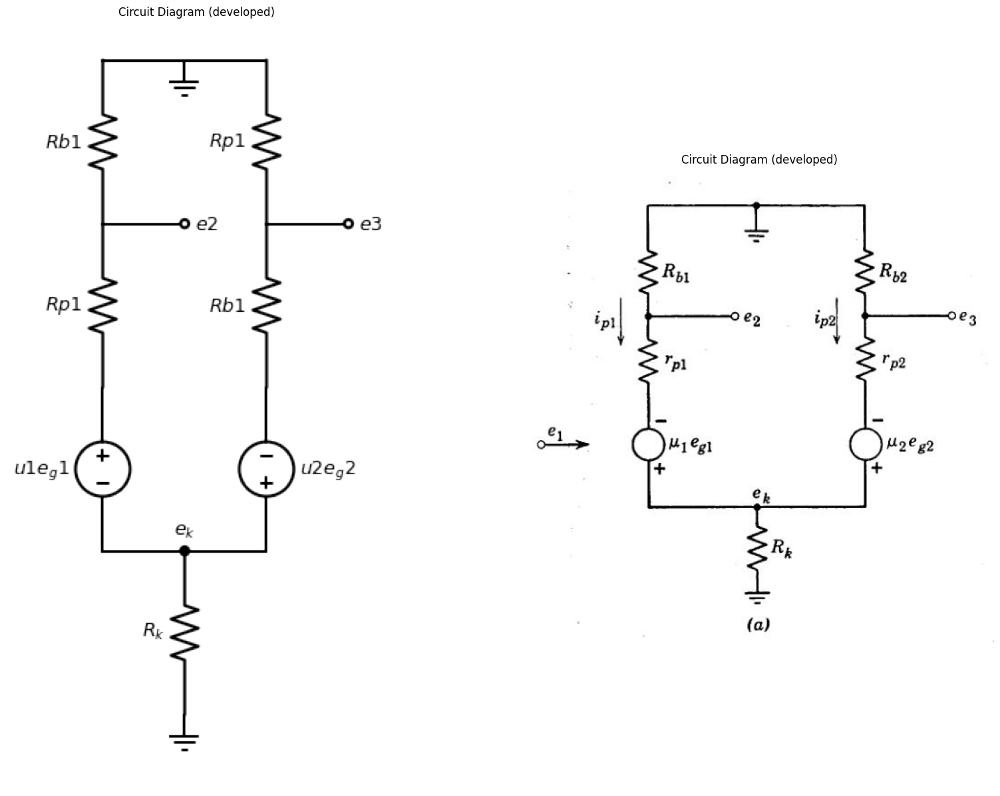

In [45]:
## import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(R1:= elm.Resistor().up(d.unit*1).label('$R_k$','top').dot().label('$e_k$','right'))
d += (l1:=elm.Line().left(d.unit*.5).color('black'))
d += (V1:=elm.SourceV().up(d.unit*1).label(r'$u1e_g1$','top'))
d +=(R2:= elm.Resistor().up(d.unit*1).label('$R{p1}$','top'))
d +=(R3:= elm.Resistor().up(d.unit*1).label('$R{b1}$','top'))
d += (l2:=elm.Line().right(d.unit*.5).color('black'))
d += (l3:=elm.Line().right(d.unit*.5).color('black'))
d +=(R4:= elm.Resistor().down(d.unit*1).label('$R{p1}$','top'))
d +=(R5:= elm.Resistor().down(d.unit*1).label('$R{b1}$','top'))
d += (V2:=elm.SourceV().down(d.unit*1).label(r'$u2e_g2$','bottom'))
d += (l4:=elm.Line().left(d.unit*.5).color('black'))
d += elm.Ground().at(R1.start)
d += elm.Ground().at(l2.end)
d += (l4:=elm.Line().right(d.unit*.5).color('black').dot(open=True).at(R2.end).label('$e{2}$','right'))
d += (l4:=elm.Line().right(d.unit*.5).color('black').dot(open=True).at(R5.start).label('$e{3}$','right'))
d.save('images/6-33b1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-33b1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
img = mpimg.imread('images/6-33a.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')

$μ1e{g1}=i{p1}(R_b1+r_p1+R_k)+i{p2} R_K$

$ μ2e{g2}=i{p2}(R_b2+r_p2+R_k)+i{p1} R_K$

$ e{g1}=e_1-(i{p1}i{p2})R_k$


$ e{g2}=-e_k=-(i{p1}i{p2})R_k$

$μ_1e_1=ip1[R{b1}+r{p1}+R_k(μ_1+1)]+ip2R_k(μ_1+1) $


$ G{21}= \frac {e_2}{e_1}=- \frac {ip1Rb1}{e_1}$

$ = \frac {-μ1Rb1[R{b2}+r{p2}+R_k(μ_2+1)]}{[R{b1}+r{p1}+R_k(μ_1+1)][R{b2}+r{p2}+R_k(μ_2+1)]-R_k^2(μ_2+1)(μ_1+1) }$


$ G{31}= \frac {e_3}{e_1}=- \frac {ip2Rb2}{e_1}$ 

$ = \frac {μ1Rb1R_k(μ_2+1)}{[R{b1}+r{p1}+R_k(μ_1+1)][R{b2}+r{p2}+R_k(μ_2+1)]-R_k^2(μ_2+1)(μ_1+1) }$


$ G{31}= \frac {e_k}{e_1}=- \frac {(ip2+ip2)R_k}{e_1}$ 


$ = \frac {R_kμ1(Rb2+r_p2)(μ_2+1)}{[R{b1}+r{p1}+R_k(μ_1+1)][R{b2}+r{p2}+R_k(μ_2+1)]-R_k^2(μ_2+1)(μ_1+1) }$

## Fig. 6.33. Incremental analysiE of cathode-coupled amplifier.

The circuit of Fig. 6.34(a) is a. linear incremental model for the cathode-coupled amplifier in the region AB, where both triodes conduct plate current but with negative grid-to-cathode voltages. The four equations given in (b) are readily reduced to the two given in (c), and
 
these in turn lead to the desired expressions for gain given in (d). Al-though the two triodes are normally of the same type, subscripts are used to designate A and rp, so that the contributions of each triode can be traced in the final results.
# SUPPLEMENTARY READING
**L. B. Arguimbau, R. B. Adler, Vacuum Tube Circuits and Transistors, John Wiley and Sons, New York, 1956.**

**B. Chance, Waveforms, McGraw-Hill, New York, 1948.**

**W. G. Dow, Fundamentals of Engineering Electronics, John Wiley and Sons, New York, 1952.**

**D.	V. Leppert, Basic Electron Tubes, McGraw-Hill, New York, 1951.**

**T. S. Gray, Applied Electronics, 2nd edition, John Wiley and Sons, New York, 1954.**

**E.	A. Guillemin, Introductory Circuit Theory, John Wiley and Sons, New York, 1953. Willis W. Harman, Fundamentals of Electronic Motion, McGraw-Hill, New York, 1953.**

**Samuel Seely, Electron-Tube Circuits, McGraw-Hill, New York, 1950,**

**Samuel Seely, Electronic Engineering, McGraw-Hill, New York, 1956.**

**Karl R. Spangenberg, Fundamentals of Electron Devices, McGraw-Hill, New York, 1957.**

**Robert L. Sproull, Modern Physics: A Textbook for Engineers, John Wiley and Sons, New York, 1956.**

**G. E. Valley and H. Will'man, Vacuum Tube Amplifiers, McGraw-Hill, New York1948.**


# PROBLEMS (See Appendix B for triode curves)
**6.1**. **(a)** Two high-vacuum triodes have the same grid-to-plate spacing, but triode B has a larger cathode-to-grid spacing than triode A. What are
the qualitative differences between their plate curves?

**(b)**	Two high-vacuum triodes are identical except that the grid wires of
triode B are smaller in diameter than the grid wires of triode A, the center-to- 
center grid-wire spacing being the same in both tubes. What are the qualita-
tive differences between their plate curves?

**(c)**	Triode B is exactly twice as large in all dimensions as triode A. What
are the differences between their plate curves?

**6.2.** In what regions of the eb vs. a plane is the approximation K (eb Atec)), where K and p. are constants, not valid for a high-vacuum
triode, and why? Consider the entire plane.

**6.3.** Describe the measurements necessary to determine the capacitances C pk, C kg, and C gp in Fig. 6.6.

**6.4.** The volt-ampere characteristics of a triode vacuum tube are character-ized by the expression

$i_b= 10^{-5} .(eb	+20e_c)^\frac {3}{2} (amperes, volts)$

Text(0.5, 1.0, 'Original')

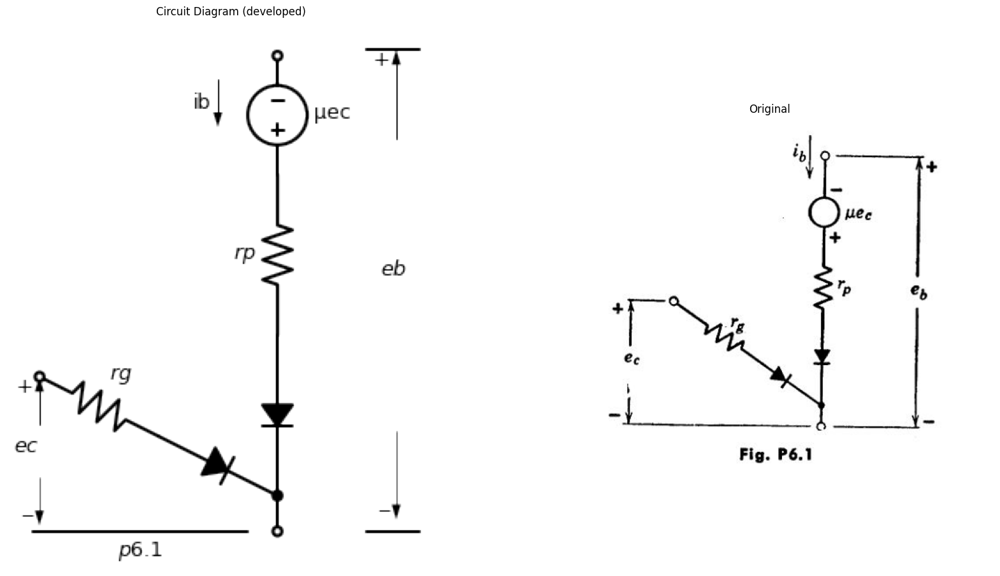

In [56]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True))
d +=(l2:= elm.Line().right(d.unit*.001).at((2,-1)))
d +=(l3:= elm.Line().right(d.unit*.001).at((4,-2)).dot())
d +=( R1:=elm.Resistor().up(d.unit*.9).label('$r{g} $','top').endpoints(l1.end,l2.end))
d +=( D1:=elm.Diode(fill=True).up(d.unit*.9).endpoints(l2.end,l3.end))
d +=( D2:=elm.Diode(fill=True).up(d.unit*.9).reverse())
d +=( R2:=elm.Resistor().up(d.unit*.9).label('$r{p} $','top'))
d += (E3 := elm.SourceV().up().length(2).label('μec','bottom').reverse().dot(open=True))
d +=(l4:= elm.Line().down(d.unit*.2).dot(open=True).at(D1.end))
d +=(l5:= elm.Line().left(d.unit*1.2).at((3.5,-2.6)).label('$p6.1$','bottom'))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-1.7))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{c}$', loc='start', color='black',ofst=0.3). at((0.3,-1))
d +=(l6:= elm.Line().right(d.unit*.3).at((5.5,-2.6)))
d +=(l7:= elm.Line().right(d.unit*.3).at((5.5,5.5)))
d += elm.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((6,4))
d += elm.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((6,-.9))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((6.5,2))
d += elm.Arrow().down().length(.8).linewidth(1).color('black').label('ib'). at((3,5))
d.save('images/6-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-1.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**(a)** Plot on graph paper a family of plate characteristics for this tube over the region
$$0 < eb < 400 volts$$
$$0 < ib < 14 ma$$
$$ec = 0, —2, —4, • • • —16 volts$$

(Note that when one curve for a given grid potential has been constructed, the other curves can be obtained by properly displacing this curve along the # axis.)

**(b)** From the graphical plot of part (a), determine the values of gn,,, and rp at the following operating points

(i) ib = 2.5 ma	     (ii) ib = ?      (iii) ib=13 ma

eb = 360 volts	     eb = 240 volts     eb=?

ec = ?	               ec = —8 volts    ec=0 volts

Does $μ= mr_p$, at each point?

**(c)** Determine from the analytical function above, expressions for rp and gm. of the form

$r_p=f (i_b)$

$g_m= g(i_b)$

Plot both quantities as a, function of ib on one set of coordinates over the
range 0 < 4 < 14 ma. Locate on this plot the values of rp and g,,determined graphically in part (b).
 
**6.5** From the Type I triode plate characteristics:

**(a)** Plot constant-current characteristics (eb vs. ec) for 4 ---- 0.2, 2, 4, 6, 8, and 10 ma.

**(b)**	Plot transfer characteristics (4 vs. ec) for eb	20, 100, 200, and 300 
volts.

At the operating point eb = 200, ec = —6, determine:

**(c)** rp and At from the plate characteristics.

**(d)**	gm from the transfer characteristics.

**(e)**	Check the relation $r_p g_m =μ$




Text(0.5, 1.0, 'Original')

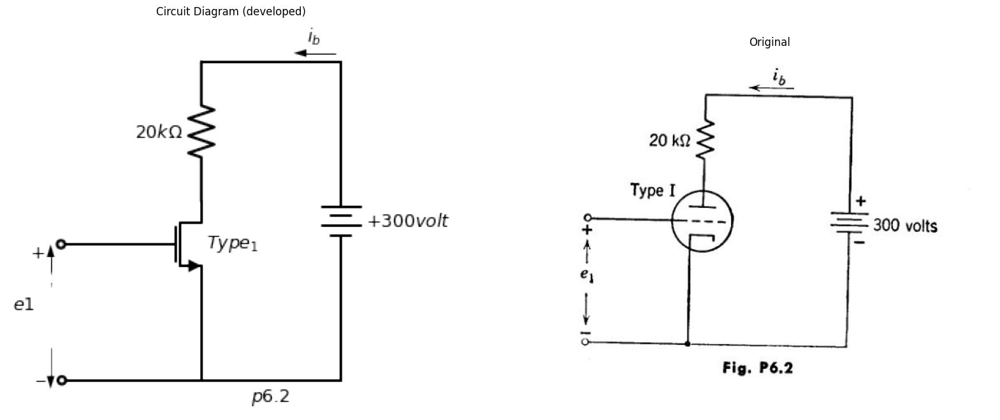

In [53]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().label('$Type_1 $','right'))
d +=(l1:= elm.Line().left(d.unit*.6).at(M1.gate).dot(open=True))
d +=(l2:= elm.Line().down(d.unit*.6).at(M1.source))
d +=(l3:= elm.Line().left(d.unit*.9).dot(open=True))
d +=(l4:= elm.Line().right(d.unit*.9).at(l3.start).label('$p6.2$','bottom'))
d +=( R1:=elm.Resistor().up(d.unit*.9).label('$20{kΩ} $','top').at(M1.drain))
d +=(l5:= elm.Line().right(d.unit*.9))
d += (E1 := elm.Battery().down().length(2).label('$+300{volt} $','bottom').endpoints(l5.end,l4.end))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2,-.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2,-2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{1}$', loc='start', color='black',ofst=0.3). at((-2,-1))
d += elm.Arrow().left().length(.8).linewidth(1).color('black').label('$i_b$'). at((3.5,3.7))
d.save('images/6-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-2.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-2.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.6.** A Type I triode is to be approximated by the piecewise-linear model shown in Fig. P6.1.

**(a)** Choose the constants rp and Az, so that the model draws the same plate current as the actual tube at each of the two points (e& ---- 80, ec = 0) and (eb = 360, ec = —16 volts).

**(b)**	Plot the plate curves of the model upon the plate curves of the tube. Outline the area within which the plate current in the model is in error by about 1 ma.


Text(0.5, 1.0, 'Original')

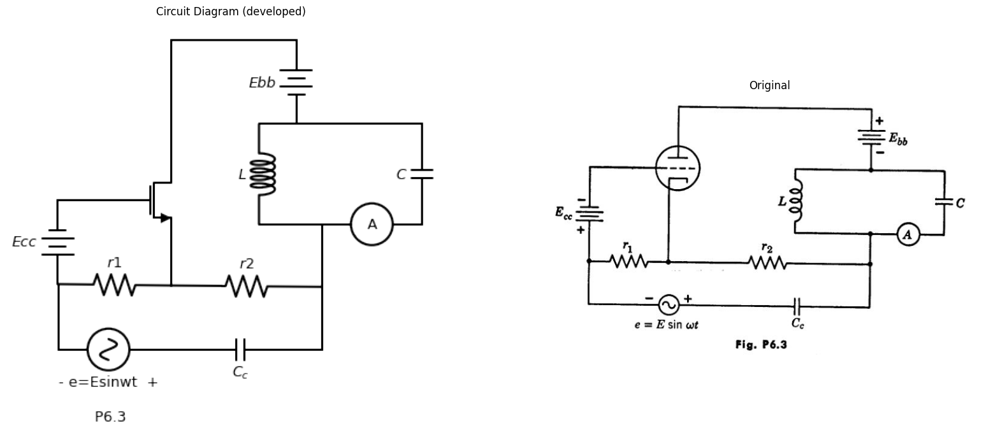

In [51]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(l1:= elm.Line().left(d.unit*.6).at(M1.gate))
d +=(l2:= elm.Line().up(d.unit*1).at(M1.drain))
d +=(l3:= elm.Line().down(d.unit*.4).at(M1.source))
d += (E1 := elm.Battery().down().length(2).label('$E{cc} $','top').reverse().at(l1.end))
d +=( R1:=elm.Resistor().right(d.unit*1.3).label('$r{1} $','top').endpoints(l3.end,E1.end))
d +=(l4:= elm.Line().right(d.unit*1).at(l2.end))
d += (E2 := elm.Battery().down().length(2).label('$E{bb} $','top'))
d +=(l4:= elm.Line().left(d.unit*.3))
d +=(L1:= elm.Inductor2().down(d.unit*.8).label('$L $','top'))
d +=(l5:= elm.Line().right(d.unit*1).at(l4.start))
d +=(C1:= elm.Capacitor().down(d.unit*.8).label('$C $','top'))
d +=(Me1:= elm.MeterA().left(d.unit*.8))
d +=(l6:= elm.Line().left(d.unit*.5))
d +=(l7:= elm.Line().down(d.unit*.5).at(l6.start))
d +=( R2:=elm.Resistor().right(d.unit*1.3).label('$r{2} $','top').endpoints(l7.end,R1.start))
d +=(l8:= elm.Line().down(d.unit*.5).at(l7.end))
d +=(C2:= elm.Capacitor().left(d.unit*1.3).label('$C_c $','bottom'))
d += (E3 := elm.SourceSin().left().length(2.40).label('- e=Esinwt  +\n\n P6.3','bottom').reverse())
d +=(l7:= elm.Line().up(d.unit*.52))
d.save('images/6-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-3.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-3.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.7.** Using the circuit of Fig. P6.2 and the results obtained in Problem 6.6 (a) plot the the curve of 4 versus el for the negative-grid-voltage region of operation

Text(0.5, 1.0, 'Original')

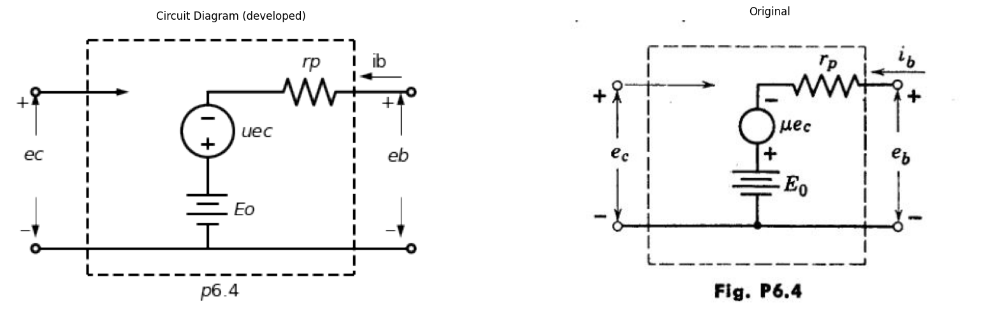

In [50]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(l1:= elm.Line().right(d.unit*.0006).dot(open=True))
d +=(l2:= elm.Arrow().right(d.unit*.6))
d +=(l3:= elm.Line().right(d.unit*.0006).dot(open=True).at((0,-3)))
d +=(l4:= elm.Line().right(d.unit*1.1))
d += (E1 := elm.Battery().up().length(1.5).label('$E{o} $','bottom').reverse())
d += (E2 := elm.SourceV().up().length(1.5).label('$uec$','bottom').reverse())
d +=( R1:=elm.Resistor().right(d.unit*1.3).dot(open=True).label('$r{p} $','top'))
d +=(l4:= elm.Line().right(d.unit*1.3).dot(open=True).at(E1.start))
d +=(l5:= elm.Line().up(d.unit*1.5).at((1,-3.5)).linestyle('--'))
d +=(l5:= elm.Line().right(d.unit*1.7).linestyle('--'))
d +=(l5:= elm.Line().down(d.unit*1.5).linestyle('--'))
d +=(l5:= elm.Line().left(d.unit*1.7).linestyle('--').label('$p6.4$','bottom'))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{c}$', loc='start', color='black',ofst=0.3). at((0.5,-1))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((7,-.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((7,-2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{b}$', loc='start', color='black',ofst=0.3). at((7.5,-1))
d += elm.Arrow().left().length(.8).linewidth(1).color('black').label('ib'). at((7,0.3))
d.save('images/6-4.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-4.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-4.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.8.** With the circuit of Fig. P6.3 the of a triode can be measured by ad-justing ri and r2 until the ammeter A reads zero. Assume that amplitude E is sufficiently small so that operation is linear. Assume ca., > > ilcoC so that ammeter A reads all of the alternating component of plate current. The reactances of C and Cc are very small at the frequency of operation. The ammeter offers negligible resistance.

**(a)**	Draw the a-c linear incremental equivalent circuit of the system.

**(b)**	Suppose that resistances r1 and r2 are adjusted to yield zero ammeter current. Under this condition, derive an expression for in terms of the parameters of the equivalent circuit.
 
**(c)** If r1 = 200 ohms, r2 = 20 kilohms and rp= 80 kilohms when the ammeter A reads zero, find the AA of the tube.


Text(0.5, 1.0, 'Original')

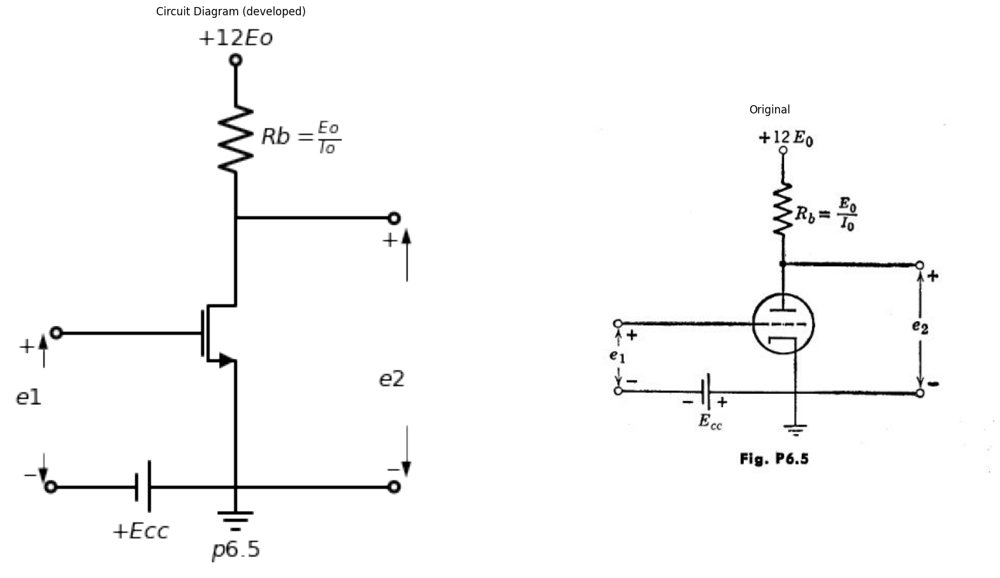

In [48]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
d +=(l1:= elm.Line().left(d.unit*.6).at(M1.gate).dot(open=True))
d +=(l2:= elm.Line().up(d.unit*.3).at(M1.drain))
d +=(l3:= elm.Line().down(d.unit*.5).at(M1.source))
d += (E2 := elm.BatteryCell().left().length(2.8).label('$+E{cc} $','bottom').at(l3.end).dot(open=True))
d +=(l4:= elm.Line().right(d.unit*.8).at(l2.end).dot(open=True))
d +=(l5:= elm.Line().right(d.unit*.8).at(l3.end).dot(open=True))
d +=( R1:=elm.Resistor().up(d.unit*.8).label(r'$Rb=\frac {Eo}{Io}$','bottom').at(l2.end).dot(open=True).label('$+12E{o} $','right'))
d += elm.Ground().at(l3.end).label('$p6.5$','bottom')
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2,-.5))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2,-1.8))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{1}$', loc='start', color='black',ofst=0.3). at((-1.7,-.8))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.5,.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.5,-1.4))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((3.8,-.5))
d.save('images/6-5.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-5.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-5.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.9.** Determine the values of the constants in the linear circuit model of Fig. P6.4 such that it behaves like the Type 11 triode in the neighborhood of eb T 200 volts, ec = —2 volts.

**(b)** Sketch and give values for the corresponding current-source model.

**6.10.** A certain triode which can be described by the equations

$ \frac {ib}{I_o}=(\frac {e_b+18e_c}{E_o})^ 2 for e_b>0 ,e_b+18e_c≥ 0$

$\frac {ib}{I_o}=0 for e_b<0$

$\frac {ib}{I_o}=0 for e_b+18e_c≤0$

is to be used as an amplifier in the circuit shown in Fig. P6,5 (El] and .to are positive constants).



Text(0.5, 1.0, 'Original')

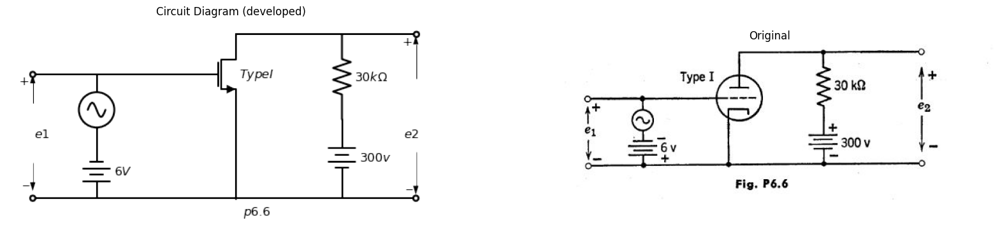

In [47]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(l1:= elm.Line().right(d.unit*.0006).dot(open=True))
d +=(l2:= elm.Line().right(d.unit*.6))
d += (E1 := elm.SourceSin().down().length(2).reverse())
d += (E2 := elm.Battery().down().length(1.5).label('$6{V} $','bottom').reverse())
d +=(l3:= elm.Line().left(d.unit*.6).dot(open=True))
d +=(l4:= elm.Line().right(d.unit*1).at(E1.start))
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().label('$Type{I}$','right'))
d +=(l5:= elm.Line().right(d.unit*3).at(E2.end).dot(open=True).label('$p6.6$','bottom'))
d +=(l6:= elm.Line().down(d.unit*.9).at(M1.source))
d +=(l7:= elm.Line().up(d.unit*.1).at(M1.drain))
d +=(l8:= elm.Line().right(d.unit*1))
d +=( R1:=elm.Resistor().down(d.unit*.8).label('$30{kΩ}$','bottom'))
d += (E2 := elm.Battery().down().length(2.2).label('$300{v} $','bottom'))
d +=(l8:= elm.Line().right(d.unit*.7).dot(open=True).at(R1.start))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((10.8,-.1))
d += elm.Arrow().down().length(1.2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((10.8,-2.2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((11.2,-1.5))
d += elm.Arrow().up().length(.8).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-.8))
d += elm.Arrow().down().length(.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.5))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{1}$', loc='start', color='black',ofst=0.3). at((0.8,-1.5))
d.save('images/6-6.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-6.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-6.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**(a)** Sketch and dimension the eb/E0 vs, iblio characteristics for this tube and find a linear model that describes the tube in the vicinity of the operating point for .$E{cc} =1/3 E_0$.

**(b)** Determine the incremental gain$ ∆e2/∆e1$ for $Ecc/E0$ = 1/3, and sketch this incremental gain as a function of $Ecc/Eo•$

**6.11.** Using the Type I triode characteristics, plot the load line and locate the operating point for the circuit in Fig. P6.6. Plot the transfer curve e2 versus ei for negative grid-to-cathode voltage only.

Text(0.5, 1.0, 'Original')

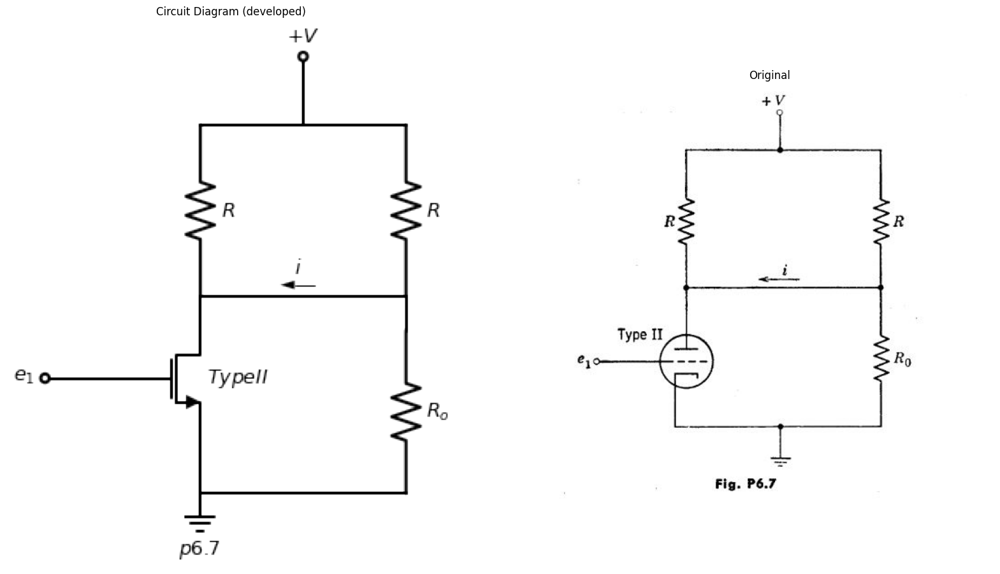

In [44]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type{II}$','right'))
d +=(l1:= elm.Line().left(d.unit*.6).at(M1.gate).dot(open=True).label('$e_1$','left'))
d +=(l2:= elm.Line().up(d.unit*.2).at(M1.drain))
d +=(l3:= elm.Line().down(d.unit*.4).at(M1.source))
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R$','bottom').at(l2.end))
d +=(l4:= elm.Line().right(d.unit*.6))
d +=(l5:= elm.Line().up(d.unit*.4).dot(open=True).label('$+V$','right'))
d +=(l6:= elm.Line().right(d.unit*.6).at(l5.start))
d +=( R2:=elm.Resistor().down(d.unit*1).label('$R$','bottom'))
d +=(l7:= elm.Line().left(d.unit*1.2))
d +=(l8:= elm.Line().down(d.unit*.2).at(R2.end))
d +=( R3:=elm.Resistor().down(d.unit*.95).label('$R_o$','bottom'))
d +=(l7:= elm.Line().left(d.unit*1.2))
d += elm.Ground().at(l3.end).label('$p6.7$','bottom')
d += elm.Arrow().left().length(.6).linewidth(1).color('black').label('$i$'). at((2,.8))
d.save('images/6-7.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-7.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-7.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.12.** Construct a set of piecewise-linear curves which approximates the Type I curves. Make the piecewise-linear curve for e = —6v tangent to the actual ec = —6v curve at the operating point.
Locate the load line and operating point of the circuit shown in Fig. P. on these piecewise-linear curves. Plot the transfer curve e2 versus ei obtained from these curves on the same graph used in Problem 6.11.
Draw the piecewise-linear model for total currents and voltages, using the values for the triode parameters determined above. Determine the slope of the e2 versus el curve.


Text(0.5, 1.0, 'Original')

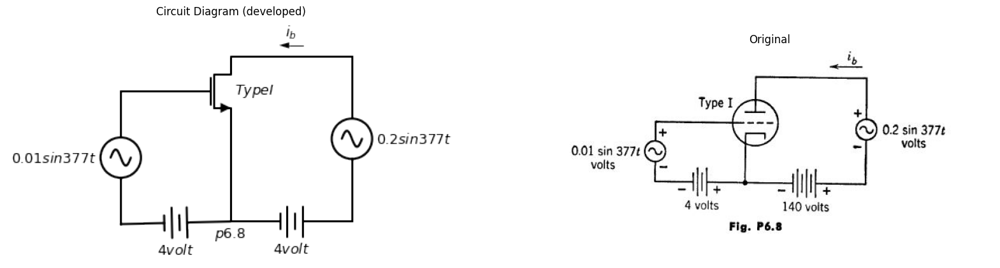

In [41]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type{I}$','right'))
d +=(l1:= elm.Line().left(d.unit*.6).at(M1.gate))
d += (E1 := elm.SourceSin().down().length(3.3).label('$0.01 sin377t $','top').reverse())
d +=(l2:= elm.Line().down(d.unit*.8).at(M1.source).label('$p6.8$','left'))
d += (E2 := elm.Battery().right().length(6.8).label('$4{volt} $','bottom').endpoints(E1.end,l2.end).reverse())
d += (E3 := elm.Battery().right().length(3).label('$4{volt} $','bottom').reverse())
d += (E4 := elm.SourceSin().up().length(4.1).label('$0.2 sin377t $','bottom').reverse())
d +=(l1:= elm.Line().left(d.unit*1))
d += elm.Arrow().left().length(.6).linewidth(1).color('black').label('$i_b$'). at((1.8,.3))
d.save('images/6-8.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-8.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-8.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.13.** (a) Referring to the Type II triode curves, show how you would choose R 0 in Fig. P6.7 to make i have the value zero when el has the value zero.

(b)	Using a piecewise-linear triode model, adjusted to match the conditions of part (a), and assuming that Ro is fixed at the value found in part (a), sketch and dimension a curve of i versus ei. Show only the region in which grid
voltage is negative and plate current is positive. How does this approximate curve differ (qualitatively) from the actual i vs. ei relationship?

(c)	For small values of ei a linear incremental circuit model may be used to calculate i from ei. Explain how you would determine suitable values for the tube parameters r and i to be used in this incremental model.

(d)	Calculate i1in terms of the constants of the incremental circuit model.


Text(0.5, 1.0, 'Original')

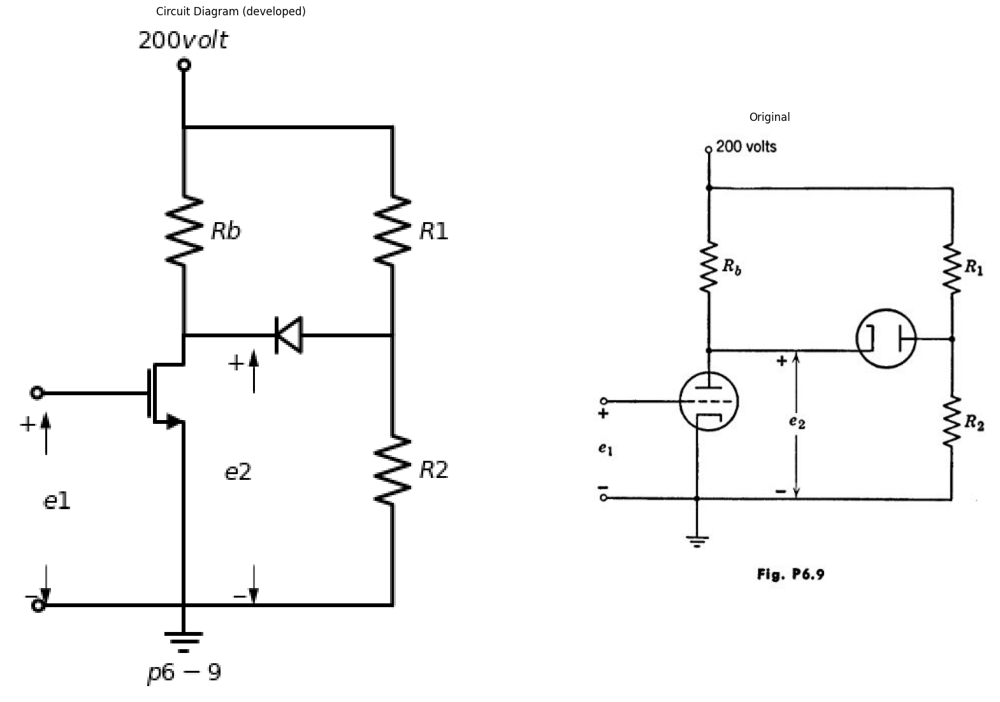

In [39]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R{b}$','bottom').at(M1.drain))
d +=(l1:= elm.Line().left(d.unit*.4).dot(open=True).at(M1.gate))
d +=(l2:= elm.Line().down(d.unit*.75).at(M1.source))
d +=( D1:=elm.Diode().right(d.unit*1).at(M1.drain).reverse())
d +=( R2:=elm.Resistor().up(d.unit*1).label('$R{1}$','bottom').at(D1.end))
d +=( R3:=elm.Resistor().down(d.unit*1.3).label('$R{2}$','bottom').at(D1.end))
d +=(l3:= elm.Line().left(d.unit*1))
d +=(l4:= elm.Line().left(d.unit*1).at(R2.end))
d +=(l5:= elm.Line().up(d.unit*.3).dot(open=True).label('$200{volt}$','right'))
d +=(l6:= elm.Line().left(d.unit*.7).dot(open=True).at(l3.end))
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((1,-.8))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((1,-3.3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((1.3,-1.8))
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2,-1.7))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2,-3.3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{1}$', loc='start', color='black',ofst=0.3). at((-1.3,-2.2))
d += elm.Ground().at(l2.end).label('$p6-9$','bottom')
d.save('images/6-9.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-9.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-9.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.14.** Write an expression for 4 in milliamperes as a function of time for the circuit shown in Fig. P6.8. Use a pieeewise-linear model for the Type I triode.

Text(0.5, 1.0, 'Original')

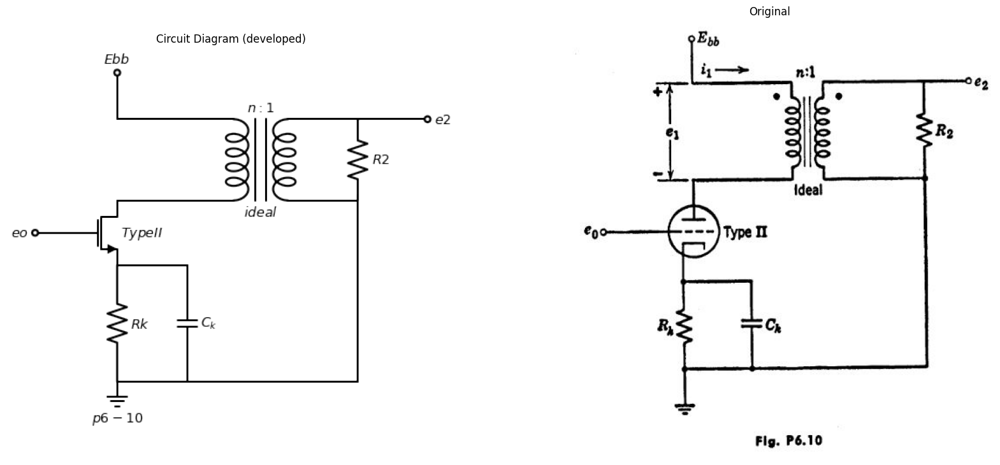

In [38]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type{II}$','right'))
d +=( R1:=elm.Resistor().down(d.unit*1).label('$R{k}$','bottom').at(M1.source))
d += elm.Ground().at(R1.end).label('$p6-10$','bottom')
d +=(l1:= elm.Line().left(d.unit*.4).dot(open=True).label('$e{o}$','left').at(M1.gate))
d +=(l2:= elm.Line().right(d.unit*2.07).at(R1.end))
d +=(l3:= elm.Line().right(d.unit*.6).at(R1.start))
d +=(C1:= elm.Capacitor().down(d.unit*1).label('$C_k$','bottom'))
d +=(l4:= elm.Line().right(d.unit*1).at(M1.drain))
d += (T1:=elm.Transformer(loop=True).right().anchor('p2').label('$ideal$','bottom').label('$n:1$','top'))
d +=(l5:= elm.Line().left(d.unit*1).at(T1.p1))
d +=(l6:= elm.Line().up(d.unit*.4).dot(open=True).label('$E{bb}$','right'))
d +=(l7:= elm.Line().right(d.unit*.6).at(T1.s1))
d +=(l8:= elm.Line().right(d.unit*.6).at(T1.s2))
d +=( R2:=elm.Resistor().down(d.unit*1).label('$R{2}$','bottom').endpoints(l7.end,l8.end))
d +=(l9:= elm.Line().right(d.unit*.6).at(l7.end).dot(open=True).label('$e{2}$','right'))
d +=(l10:= elm.Line().up(d.unit*1.6).at(l2.end))
d.save('images/6-10.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-10.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-10.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.15.** Assume the triode in the circuit shown in Fig. P6.9 can be represented by linear characteristics with 20 and rp = 10 kilohms. The following conditions are to be met:

For —10 < e1 < —5, G = | ∆e2/∆ei | = 15 

For —5 < ei < 0, G= | ∆e2/∆le| = 10

The diode may be assumed to be ideal. Determine the required values of Re,, R1, and R2.


**6.16**. In the circuit of Fig. P6.10 the transformer is assumed to be ideal, that is aide = 0, ez" = ei•c/n, and eeiciii" = n2R2. Also let Ck be so large that the cathode potential is nearly constant. Assume μ= 40, rp = 12 kilohms.

Text(0.5, 1.0, 'Original')

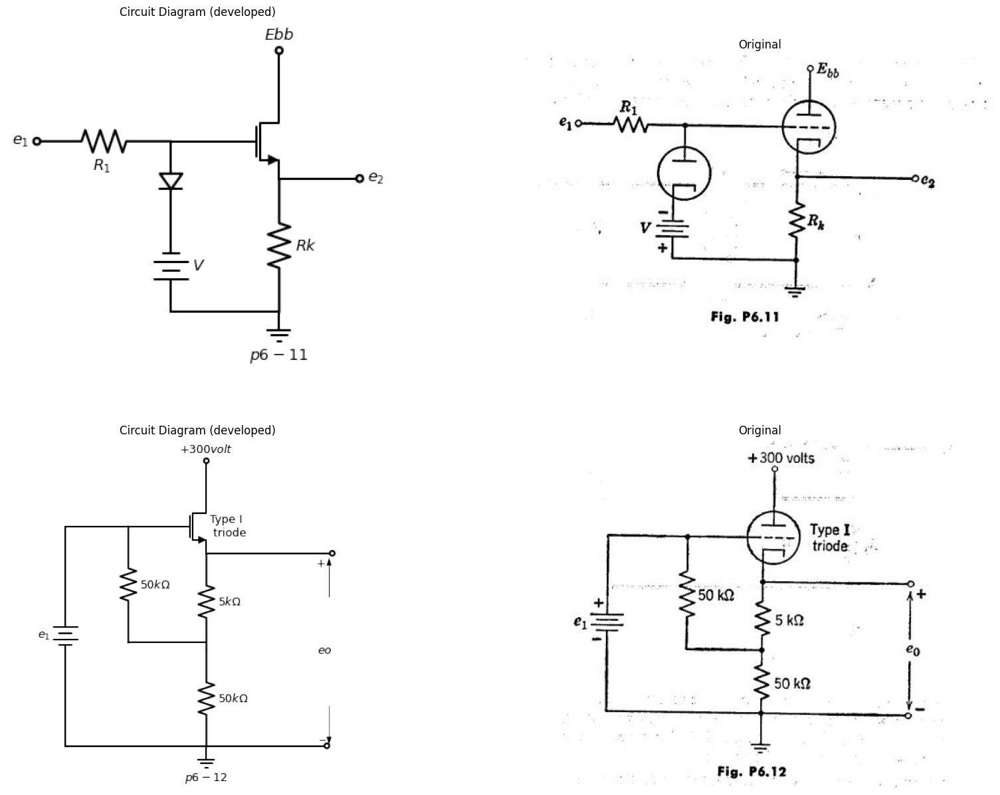

In [37]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=( R1:=elm.Resistor().down(d.unit*1).label('$Rk$','bottom').at(M1.source))
d +=(l1:= elm.Line().up(d.unit*.4).dot(open=True).label('$E{bb}$','right').at(M1.drain))
d +=(l2:= elm.Line().left(d.unit*.5).at(M1.gate))
d +=(l3:= elm.Line().right(d.unit*.6).dot(open=True).label('$e_2$','right').at(M1.source))
d +=( D1:=elm.Diode().down(d.unit*.6).at(l2.end))
d += (E1 := elm.Battery().down().length(2).label('$V $','bottom').reverse())
d +=(l4:= elm.Line().right(d.unit*.8))
d += elm.Ground().at(R1.end).label('$p6-11$','bottom')
d +=( R2:=elm.Resistor().left(d.unit*1).label('$R_1$','bottom').at(D1.start).dot(open=True).label('$e_1$','left'))
d.save('images/6-11.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-11.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-11.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('Type I\n triode','right'))
d +=( R1:=elm.Resistor().down(d.unit*1).label('$5{kΩ}$','bottom').at(M1.source))
d +=(l1:= elm.Line().up(d.unit*.4).dot(open=True).label('$+300{volt}$','right').at(M1.drain))
d +=(l2:= elm.Line().left(d.unit*.5).at(M1.gate))
d +=( R2:=elm.Resistor().down(d.unit*1).label('$50{kΩ}$','bottom').at(R1.end))
d +=( R3:=elm.Resistor().down(d.unit*1.2).label('$50{kΩ}$','bottom').at(l2.end))
d +=(l3:= elm.Line().right(d.unit*.8))
d +=(l4:= elm.Line().left(d.unit*.65).at(R3.start))
d += (E1 := elm.Battery().down().length(6.8).label('$e_1 $','top'))
d +=(l5:= elm.Line().right(d.unit*2.7).dot(open=True))
d +=(l6:= elm.Line().right(d.unit*1.3).dot(open=True).at(M1.source))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.8,-3))
d += elm.Arrow().down().length(1.2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.8,-6.4))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{o}$', loc='start', color='black',ofst=0.3). at((4.2,-4.5))
d += elm.Ground().at(R2.end).label('$p6-12$','bottom')
d.save('images/6-12.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-12.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-12.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

(a)	With e0 a small sine wave voltage of fixed amplitude E0, find the value of the turns-ratio n which maximizes the a-c output voltage e2.

(b)	With n and E0 fixed, find  the value of R2 for maximum power delivered to R2. Compare with the results of part (a).

**6.17.** As the grid voltage of a triode passes from positive to negative, the grid current becomes very small. In some applications even an exceedingly small grid current is significant, however, and the following scheme is proposed for finding out something about the low grid currents flowing in the negative¬grid-voltage region of operation. The triode is connected as a grounded-cathode amplifier and a point-by-point plot of versus ec is made. The adjustable input source is then removed and an uncharged 0,1 f capacitor is connected from ground to grid at time zero. The capacitor was previously checked for low leakage by observing that it would hold a charge for many minutes without appreciable diminution. Voltage et, is recorded and plotted as a function of time. How do you find the grid-current versus grid-voltage curve of the amplifier from the available data and what portions of the curve are reliably determined by this method?

**6.18.** Sketch and dimension the static e2 vs. ei curve of the amplifier shown in Fig. P6.11. Assume piecewise-linear behavior of the tube. The external diode is to be treated as an ideal rectifier.

**6.19.** Using the Type I triode characteristic, find eo for the circuit shown in Fig. P6.12 when (a) ei — 0 and (b) ei = 50 volts.


Text(0.5, 1.0, 'Original')

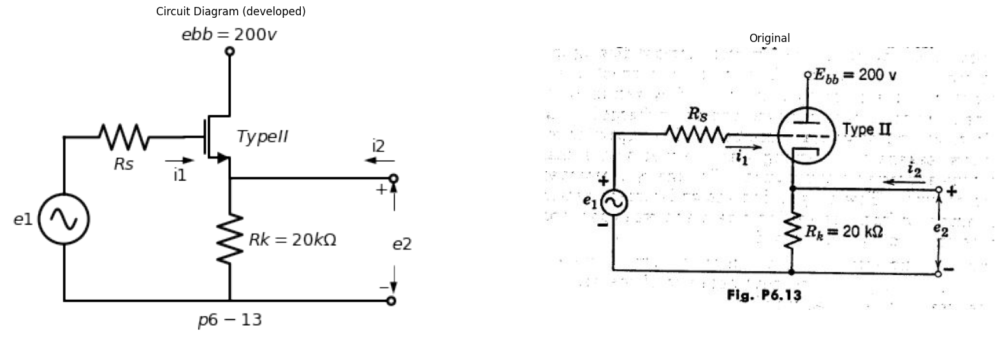

In [33]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type II$','right'))
d +=( R1:=elm.Resistor().down(d.unit*.81).label('$Rk=20{kΩ}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().left(d.unit*.81).label('$R{s}$','bottom').at(M1.gate))
d += (E1 := elm.SourceSin().down().length(3.3).label('$e{1} $','top').reverse())
d +=(l1:= elm.Line().right(d.unit*2.2).dot(open=True).label('$p6-13$','bottom'))
d +=(l1:= elm.Line().up(d.unit*.3).at(M1.drain).label('$ebb={200v}$','right').dot(open=True))
d +=(l1:= elm.Line().right(d.unit*1.1).dot(open=True).at(M1.source))
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.3,-2.3))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.3,-3.4))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((4,-2.8))
d += elm.Arrow().left().length(.6).linewidth(1).color('black').label('i2'). at((3.3,-1.3))
d += elm.Arrow().right().length(.6).linewidth(1).color('black').label('i1','bottom'). at((-1.3,-1.3))
d.save('images/6-13.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-13.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-13.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.20.** (a) Plot the load line and find the operating point of the cathode follower circuit in Fig. P6.13 on'the Type II triode curves.

(b) Determine graphically and plot the transfer characteristic e2 vs. el,

(1)	assuming that R. = 10 kilohmi and that the gridato-ca.thode circuit
of the tube can be represented by a 1-kilohm resistance in series with an ideal diode, and

(2)	assuming R	0, rg = 1 kS-1.


**6.21.** From Fig. P6.14:

(a)	If el (t) = 250 sin wt, sketch and dimension e2 (t).

(b)	If e 1(t) = 0.1 sin wt , sketch and dimension ei (t).


Text(0.5, 1.0, 'Original')

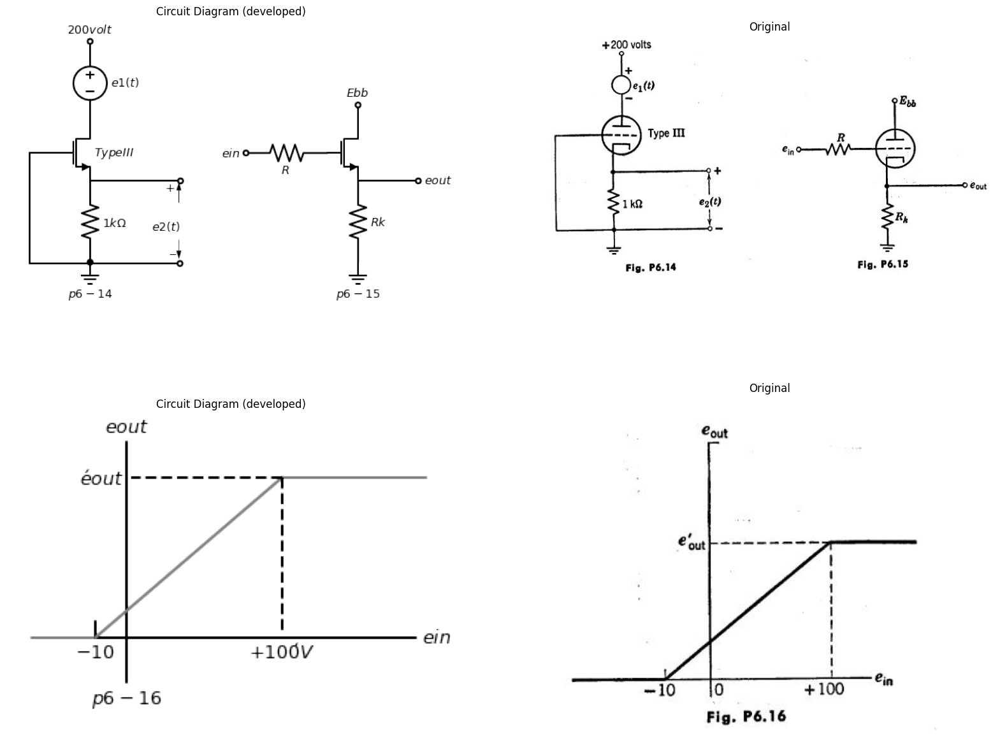

In [32]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type III$','right'))
d += (E1 := elm.SourceV().up().length(2.5).label('$e1{(t)} $','bottom').at(M1.drain).dot(open=True).label('$200{volt}$','right'))
d +=( R1:=elm.Resistor().down(d.unit*.81).label('$1{kΩ}$','bottom').at(M1.source).dot())
d +=(l1:= elm.Line().left(d.unit*.3).at(M1.gate))
d +=(l2:= elm.Line().down(d.unit*1.1))
d +=(l3:= elm.Line().right(d.unit*1.5).dot(open=True))
d +=(l4:= elm.Line().right(d.unit*.9).dot(open=True).at(M1.source))
d += elm.Ground().at(R1.end).label('$p6-14$','bottom')
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((2.65,-2.3))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2.65,-3.4))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e2{(t)}$', loc='start', color='black',ofst=0.3). at((3,-2.8))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().at((8,0)))
d +=( R2:=elm.Resistor().left(d.unit*.81).label('$R$','bottom').at(M2.gate).dot(open=True).label('$e{in}$','left'))
d +=( R3:=elm.Resistor().down(d.unit*.81).label('$R{k}$','bottom').at(M2.source))
d +=(l5:= elm.Line().right(d.unit*.6).at(M2.source).dot(open=True).label('$e{out}$','right'))
d +=(l6:= elm.Line().up(d.unit*.2).at(M2.drain).dot(open=True).label('$E{bb}$','right'))
d += elm.Ground().at(R3.end).label('$p6-15$','bottom')
d.save('images/6-14.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-14.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-14.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d +=(l1:= elm.Line().up(d.unit*1.5).at(M1.gate).label('$e{out}$','right').label('$p6-16$','left'))
d +=(l2:= elm.Line().right(d.unit*2).at((-1.5,0)).label('$e{in}$','right'))
d +=(l3:= elm.Line().left(d.unit*.4).at(l2.start).color('gray'))
d +=(l4:= elm.Line().up(d.unit*.1).at((-1.5,0)).label('$-10$','left'))
d +=(l5:= elm.Line().right(d.unit*.9).at((2,3)).color('gray'))
d +=(l6:= elm.Line().left(d.unit*.4).endpoints(l3.start,l5.start).color('gray'))
d +=(l7:= elm.Line().left(d.unit*.95).at(l5.start).color('black').linestyle('--').label('$e ́{out}$','left'))
d +=(l7:= elm.Line().down(d.unit*.98).at(l5.start).color('black').linestyle('--').label('$+100 ́{V}$','left'))
d.save('images/6-16.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-16.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-16.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

**6.22.** Approximating the tube in Fig. P6.15 by linearized plate character istics having rp = 10 kilohms, μ = 20, and cutoff at eb =-20ec find the values of Pk and Ebb which yield the output-input characteristic shown in Fig. P6.16. Assume that the limiting resistance R is large. What is the value of eic,„t in Fig. P6.16?

**6.23.** The cathode-follower circuit shown in Fig. P6.17 is required to handle input signals with peak-to-peak amplitudes up to 140 volts. Grid limiting and cutoff clipping are to be avoided. The total cathode load (R1 + R2) is 20. kilohrns. Determine appropriate values of R1 and R. The transfer characteristic, may be assumed linear between cutoff and ec= 0.


Text(0.5, 1.0, 'Original')

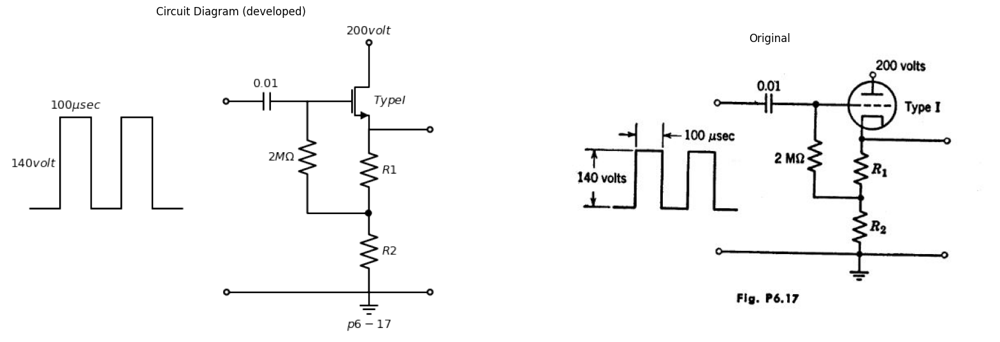

In [30]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type I$','right'))
d +=(l1:= elm.Line().up(d.unit*.3).at(M1.drain).dot(open=True).label('$200{volt}$','right'))
d +=( R1:=elm.Resistor().down(d.unit*.8).label('$R{1}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().down(d.unit*.8).label('$R{2}$','bottom'))
d +=(l2:= elm.Line().left(d.unit*.3).at(M1.gate))
d +=( C1:=elm.Capacitor().left(d.unit*.8).label('$0.01$','top').dot(open=True))
d +=( R3:=elm.Resistor().down(d.unit*1.1).label('$2{MΩ}$','top').at(l2.end))
d +=(l3:= elm.Line().right(d.unit*.6).dot())
d +=(l4:= elm.Line().right(d.unit*.6).dot(open=True).at(M1.source))
d +=(l5:= elm.Line().right(d.unit*.6).dot(open=True).at(R2.end))
d +=(l5:= elm.Line().left(d.unit*1.4).dot(open=True).at(R2.end))
d +=(l6:= elm.Line().right(d.unit*.3).at((-10,-4)))
d +=(l7:= elm.Line().up(d.unit*.9).label('$140{volt}$','top'))
d +=(l8:= elm.Line().right(d.unit*.3).label('$100{μsec}$','top'))
d +=(l9:= elm.Line().down(d.unit*.9))
d +=(l10:= elm.Line().right(d.unit*.3))
d +=(l6:= elm.Line().up(d.unit*.9))
d +=(l6:= elm.Line().right(d.unit*.3))
d +=(l6:= elm.Line().down(d.unit*.9))
d +=(l6:= elm.Line().right(d.unit*.3))
d += elm.Ground().at(R2.end).label('$p6-17$','bottom')
d.save('images/6-17.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-17.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-17.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.24.** Assume $ib =2ec + 0.1eb$ for the triode in Fig. P6.18, where units are volts and milliamperes.

(a)	Find that value of resistor R for which the curve of meter current i versus input voltage e passes through the origin in the i versus e plane, Use


Text(0.5, 1.0, 'Original')

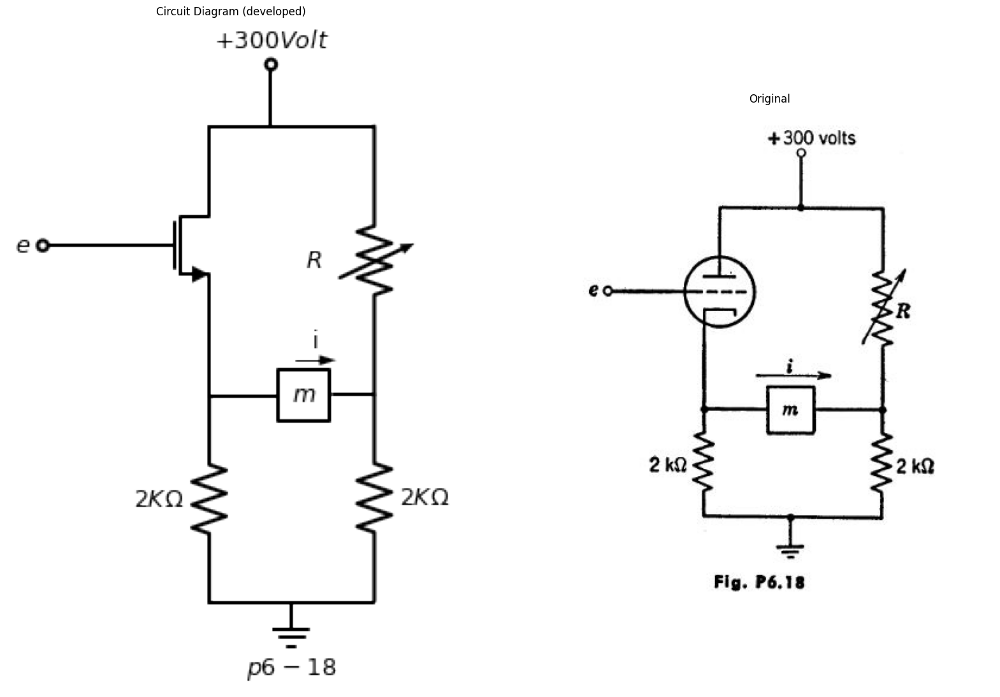

In [29]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from schemdraw import dsp
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=(l1:= elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$e$','left'))
d +=(l2:= elm.Line().up(d.unit*.3).at(M1.drain))
d +=(l3:= elm.Line().down(d.unit*.45).at(M1.source))
d +=(l4:= elm.Line().right(d.unit*.3).at(l2.end))
d +=(l5:= elm.Line().up(d.unit*.3).dot(open=True).label('$+300{Volt}$','right'))
d +=(l6:= elm.Line().right(d.unit*.5).at(l4.end))
d +=( R1:=elm.ResistorVarIEEE().down(d.unit*1.3).label('$R$','top').reverse())
d +=(l7:= elm.Line().left(d.unit*.2))
d += ( T := dsp.Box(w=.75, h=.75).anchor('W').fill('white').label('$m$').at((1,-3)))
d +=(l8:= elm.Line().right(d.unit*.33).at(l3.end))
d +=( R2:=elm.Resistor().down(d.unit*1).label('$2{KΩ}$','bottom').at(R1.end))
d +=( R3:=elm.Resistor().down(d.unit*1).label('$2{KΩ}$','top').at(l3.end))
d +=(l9:= elm.Line().right(d.unit*.4))
d +=(l10:= elm.Line().right(d.unit*.4))
d += elm.Ground().at(l9.end).label('$p6-18$','bottom')
d += elm.Arrow().right().length(.6).linewidth(1).color('black').label('i','top'). at((1.25,-2.5))
d.save('images/6-18.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-18.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-18.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


this value of R in parts () and (c) of the problem. Remember that e is measured from ground.

(b)	Calculate the sensitivity Li s. Assume that the meter resistance is negligible.
is Sketch and dimension the curve of 1 vs. e, showing the entire region within which grid voltage is negative and plate current is positive.

**6.25.** For the circuit shown in Fig. P6.19, sketch the transfer characteristic
e2 as a function of ei for Vbpositive and also for V b negative. Give the slope of the characteristic in terms of the circuit parameters.

**6.26.** For the circuit shown in Fig. P6.20, plot the path of the operating
point on the eb vs. plane as e, is varied from — ∞ to +∞ . Assume a piece¬wise-linear triode model where rp i 1000 ohms, μ= 5.


Text(0.5, 1.0, 'Original')

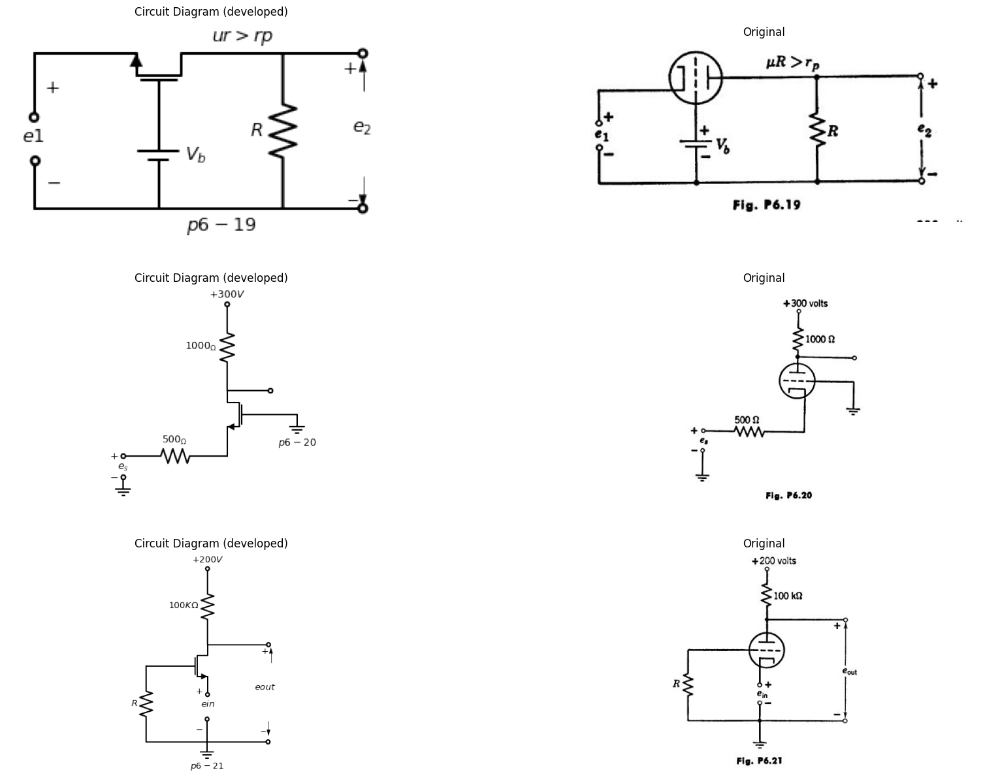

In [26]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(270))
d += (E1 := elm.BatteryCell().down().length(2).label('$V_b $','bottom').at(M1.gate))
d +=(l1:= elm.Line().left(d.unit*.5).at(M1.source))
d +=(l2:= elm.Line().right(d.unit*.5).at(M1.drain).label('$ur>rp$','top'))
d +=(l3:= elm.Line().down(d.unit*.4).at(l1.end).dot(open=True).label('$e{1}$','left').label('$+$','bottom'))
d +=(l4:= elm.Line().left(d.unit*.77).at(E1.end))
d +=(l5:= elm.Line().up(d.unit*.3).dot(open=True).label('$-$','bottom'))
d +=( R1:=elm.Resistor().down(d.unit*.97).label('$R$','top').at(l2.end))
d +=(l6:= elm.Line().left(d.unit*.77).label('$p6-19$','bottom'))
d +=(l7:= elm.Line().right(d.unit*.5).dot(open=True).at(R1.start))
d +=(l8:= elm.Line().right(d.unit*.5).dot(open=True).at(R1.end))
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3,-.7))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3,-2.3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=0.3). at((3.5,-1.25))
d.save('images/6-19.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-19.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-19.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0))
d +=( R1:=elm.Resistor().up(d.unit*1).label('$1000_Ω$','top').at(M1.drain).dot(open=True).label('$+300{V}$','right'))
d +=(l1:= elm.Line().right(d.unit*.5).at(M1.gate))
d +=(l2:= elm.Line().down(d.unit*.2).at(M1.source))
d +=(l3:= elm.Line().right(d.unit*.5).at(M1.drain).dot(open=True))
d +=( R2:=elm.Resistor().left(d.unit*1.2).label('$500_Ω$','top').at(l2.end).dot(open=True).label('$+$','left'))
d += elm.Ground().at(l1.end).label('$p6-20$','bottom')
d +=(l3:= elm.Line().right(d.unit*.001).at((-3.6,-3)).dot(open=True).label('$-$','left').label('$e_s$','top'))
d += elm.Ground().at(l3.end)
d.save('images/6-20.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-20.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-20.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=( R1:=elm.Resistor().up(d.unit*1).label('$100{KΩ}$','top').at(M1.drain).dot(open=True).label('$+200{V}$','right'))
d +=(l1:= elm.Line().left(d.unit*.5).at(M1.gate))
d +=( R2:=elm.Resistor().down(d.unit*1).label('$R$','top'))
d +=(l2:= elm.Line().down(d.unit*.1).at(M1.source).dot(open=True).label('$+$','top').label('$e{in}$','left'))
d +=(l3:= elm.Line().right(d.unit*.8).at(R2.end))
d +=(l4:= elm.Line().up(d.unit*.3).dot(open=True).label('$-$','top'))
d +=(l5:= elm.Line().right(d.unit*.8).at(l4.start).dot(open=True))
d +=(l6:= elm.Line().right(d.unit*.8).at(M1.drain).dot(open=True))
d += elm.Ground().at(l4.start).label('$p6-21$','bottom')
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((2.5,-.7))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2.4,-3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{out}$', loc='start', color='black',ofst=0.3). at((3,-1.5))
d.save('images/6-21.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-21.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-21.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

**6.27.** For the circuit of Fig. P6.21 plot the complete output-input character¬istic for an input voltage range from — 250 to +50 volts. Assume the plate characteristics are piecewise-linear with μ= 100, rp = 50 kiIohni s. When grid current flows, the voltage drop through resistance R is sufficiently large to hold e, at a value very nearly equal to zero. Show the locus of operation on the plate characteristics.

Text(0.5, 1.0, 'Original')

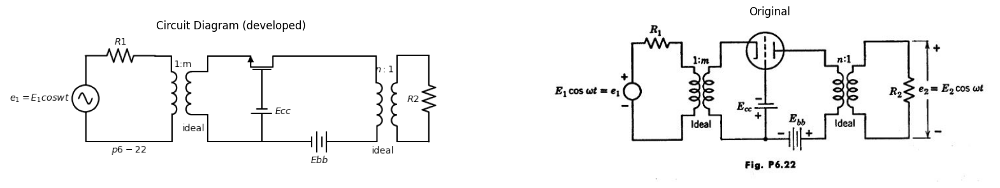

In [22]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(270))
d += (E1 := elm.BatteryCell().down().length(2.3).label('$E {cc} $','bottom').at(M1.gate).reverse())
d += (E2 := elm.Battery().right().length(4.3).label('$E{bb} $','bottom').reverse())
d +=(l1:= elm.Line().up(d.unit*.2))
d += (T1:=elm.Transformer(core=False).right().anchor('p2'))
d +=(l2:= elm.Line().right(d.unit*1.15).at(M1.drain))
d +=(l3:= elm.Line().down(d.unit*.34))
d +=(l4:= elm.Line().up(d.unit*.34).at(T1.s1).label('$n:1$','top'))
d +=(l5:= elm.Line().down(d.unit*.2).at(T1.s2).label('\n\n\nideal','top'))
d +=(l6:= elm.Line().right(d.unit*.4).at(l4.end))
d +=(l7:= elm.Line().right(d.unit*.4).at(l5.end))
d +=( R1:=elm.Resistor().down(d.unit*.87).label('$R{2}$','top').endpoints(l6.end,l7.end))
d +=(l8:= elm.Line().left(d.unit*.4).at(M1.source))
d +=(l9:= elm.Line().down(d.unit*.2))
d +=(l10:= elm.Line().left(d.unit*.2))
d += (T2:=elm.Transformer(core=False).right().anchor('s1'))
d +=(l11:= elm.Line().right(d.unit*.2).at(T2.s2))
d +=(l12:= elm.Line().down(d.unit*.34).label('ideal','top'))
d +=(l13:= elm.Line().right(d.unit*.7))
d +=(l14:= elm.Line().up(d.unit*.2).label('1:m','bottom').at(T2.p1))
d +=(l15:= elm.Line().left(d.unit*.2))
d +=( R2:=elm.Resistor().left(d.unit*.87).label('$R{1}$','top'))
d += (E1 := elm.SourceSin().down().length(3.2).label('$e_1=E_1coswt $','top').reverse().at(R2.end))
d +=(l16:= elm.Line().right(d.unit*1.08).label('$p6-22$','bottom'))
d +=(l17:= elm.Line().up(d.unit*.34))
d.save('images/6-22.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-22.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-22.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.28.** The transformers shown in Fig. P6.22 are ideal at frequency co but each winding is a short circuit for d-c. Assume that E1 is small, so that the
operation of the circuit is linear.

(a) Derive an expression for the power gain G = PL/PA	, where the avail-
able source power PA and the load power PL are defined as: $PA = E1^2 /4R1$ ,$PL =E2^2 /R2,$ Gain G is a function of R1, R2, m, μ, p,, and rp,.


(b)	The maximum gain obtainable by adjustment of turns-ratio n. is defined as the available gain GA , Find GA in terms of Ri, m, μ, and rp. Plot $GA /(μ + 1)$ vs. $(M^2 R1)/rp/(μ + 1).$

(c)	The maximum gain obtainable by simultaneous adjustment of both to and n is defined as the maximum available gain GA.. Find GAIn in terms of i and rp.

(d)	Show that for fixed El, RI, and R2, but adjustable m and n, the power-gain maximization also maximizes the voltage amplification EWE'.

**6.29.** Sketch the e vs. i characteristics of the circuit shown in Fig. P6,23. A piecewise-linear' model should be assumed.



Text(0.5, 1.0, 'Original')

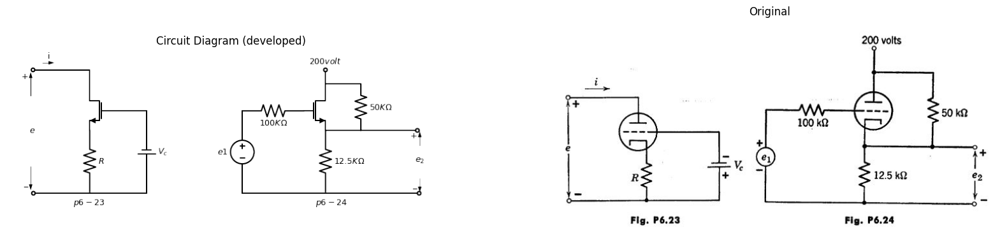

In [20]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0))
d +=( R1:=elm.Resistor().down(d.unit*.87).label('$R$','bottom').at(M1.source))
d +=(l1:= elm.Line().up(d.unit*.3).at(M1.drain))
d +=(l2:= elm.Line().left(d.unit*.8).dot(open=True))
d +=(l3:= elm.Line().right(d.unit*.5).at(M1.gate))
d += (E1 := elm.BatteryCell().down().length(3.5).label('$V_c $','bottom').reverse())
d +=(l3:= elm.Line().left(d.unit*1.6).dot(open=True).label('$p6-23$','bottom'))
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2.5,-.2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2.5,-3.2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e$', loc='start', color='black',ofst=0.3). at((-2,-1.5))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((-2,1.2))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).at((10,0)).reverse())
d +=( R2:=elm.Resistor().down(d.unit*.87).label('$12.5{KΩ}$','bottom').at(M2.source))
d +=( R3:=elm.Resistor().left(d.unit*.87).label('$100{KΩ}$','bottom').at(M2.gate))
d += (E1 := elm.SourceV().down().length(3.5).label('$e 1 $','top').reverse().at(R3.end))
d +=(l4:= elm.Line().right(d.unit*2.5).dot(open=True).label('$p6-24$','bottom'))
d +=(l5:= elm.Line().up(d.unit*.1).at(M2.drain))
d +=(l6:= elm.Line().up(d.unit*.2).dot(open=True).label('$200{volt}$','right'))
d +=(l7:= elm.Line().right(d.unit*.5).at(l5.end))
d +=(l8:= elm.Line().right(d.unit*.5).at(M2.source))
d +=( R4:=elm.Resistor().down(d.unit*.87).label('$50{KΩ}$','bottom').endpoints(l7.end,l8.end))
d +=(l9:= elm.Line().right(d.unit*.8).dot(open=True).at(R4.end))
d += elm.Arrow().up().length(.6).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((14,-2.3))
d += elm.Arrow().down().length(.6).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((14,-3.7))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=0.3). at((14.5,-2.75))
d.save('images/6-23.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-23.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-23.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.30.** (a) Sketch and dimension the static transfer 

cathode follower circuit shown in Fig. P6.24. Assume a piecewise-linear triode with μ = 20, rp = 10 kilohms„ and rg = O.

(b)	Determine e2 (E) for the circuit shown in Fig. P6.24 with e1 (t)= +35 + 
50 sin wt.

(c)	If	e1(t)= E1 + 40 sinw0t  is applied to the circuit of Fig. P6.24, choose

a value of E1 that will result in a sinusoidal output e2 = E2+Em sin w0t.
Determine E2 and Em.

**6.31.** Sketch approximate piecewise-linear curves of e2 and e3 versus e1, on the same coordinates, for the circuit shown in Fig. P6.25. Show only the negative grid-voltage region. Choose the constants j and rp for the piecewise-linear triode model in order to give a. reasonable approximation to the Type I triode curves. Let Ebb = 300 volts and let both R6 and Rk equal 10 kilohms.

**6.32**. Tabulate the states of each of the three diodes in Fig. 6.26 for the five regions of operation.

**6.33.** A Type I triode is connected as shown in Fig. P6.26. Confining attention to the negative-grid-voltage region of operation, plot on the plate curves the locus of (a) varying e1 for Rb = 15 kilohms, Elk = 5 kilohms, (b) varying R6 for ei = 25 volts, Rk 5 kilohms, (c) varying Rk for ei 25 volts, R6 15 kilohms, (d) What is the value of 4 for el = 25 volts, R = 15 kilohms, Rk = 5 kilohms? (e) Plot lb vs. e1 for Rk = 5 kilohms, Rb = 15 kilohms.


Text(0.5, 1.0, 'Original')

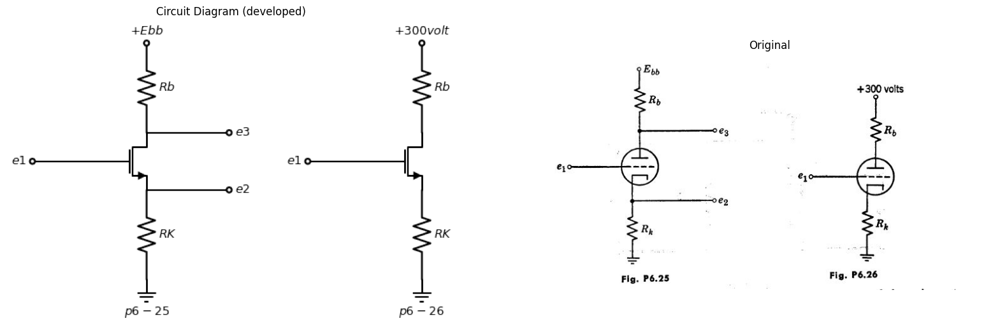

In [19]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=( R1:=elm.Resistor().down(d.unit*.87).label('$R{K}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().up(d.unit*.87).label('$R{b}$','bottom').at(M1.drain).label('$+E{bb}$','right').dot(open=True))
d +=(l1:= elm.Line().left(d.unit*.8).at(M1.gate).dot(open=True).label('$e{1}$','left'))
d +=(l1:= elm.Line().right(d.unit*.8).at(M1.drain).dot(open=True).label('$e{3}$','right'))
d +=(l1:= elm.Line().right(d.unit*.8).at(M1.source).dot(open=True).label('$e{2}$','right'))
d += elm.Ground().at(R1.end).label('$p6-25$','bottom')
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().at((8,0)))
d +=( R3:=elm.Resistor().down(d.unit*.87).label('$R{K}$','bottom').at(M2.source))
d +=( R4:=elm.Resistor().up(d.unit*.87).label('$R{b}$','bottom').at(M2.drain).label('$+300{volt}$','right').dot(open=True))
d +=(l1:= elm.Line().left(d.unit*.8).at(M2.gate).dot(open=True).label('$e{1}$','left'))
d += elm.Ground().at(R3.end).label('$p6-26$','bottom')
d.save('images/6-25.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-25.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-25.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.34.** (a) For the circuit shown in Fig. P0.27, graphically find the quiescent operating point.

Text(0.5, 1.0, 'Original')

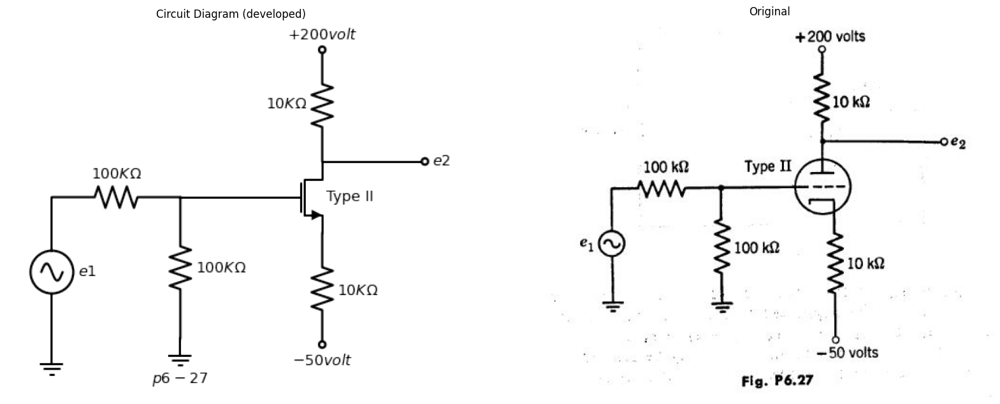

In [17]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('Type II ','right'))
d +=( R1:=elm.Resistor().down(d.unit*.87).label('$10{KΩ}$','bottom').at(M1.source).label('$-50{volt}$','left').dot(open=True))
d +=( R2:=elm.Resistor().up(d.unit*.87).label('$10{KΩ}$','top').at(M1.drain).label('$+200{volt}$','right').dot(open=True))
d +=(l1:= elm.Line().left(d.unit*.8).at(M1.gate))
d +=( R3:=elm.Resistor().down(d.unit*1.1).label('$100{KΩ}$','bottom').at(l1.end))
d +=( R4:=elm.Resistor().left(d.unit*1).label('$100{KΩ}$','top').at(l1.end))
d += (E1 := elm.SourceSin().down().length(3.5).label('$e 1 $','bottom').reverse().at(R4.end))
d += elm.Ground().at(R3.end).label('$p6-27$','bottom')
d += elm.Ground().at(E1.end)
d +=(l1:= elm.Line().right(d.unit*.8).at(M1.drain).label('$e{2}$','right').dot(open=True))
d.save('images/6-27.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-27.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-27.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


(b)	At the quiescent operating point, cfklculate the incremental parameters rpf and gni. , Show the piecewise-linear model of the circuit of Fig. P6.27.

(c)	For a small signal Aei, calculate the incremental gain of the circuit.

**6.35.** For, the Type II triode connected as in Fig. P6.28, plot the complete

output-input characteristic for an input voltage range from —20 to +30 
volts. When grid current flows, the voltage drop through resistance R is
sufficiently large to hold ee at 'a value very nearly equal to zero.

**6.36.** Find the operating. ppiny, (4,.1§ and eb) for the Type. I triode in the Orquit.of.Fig. 1N.29. Use thp p.lp4e and,. grid rharacteristics for positive values oIgrid voltage. A cut-and-try process is necessary.

**6.37** (a) :Using Alai. -Type triode _characteristics, plot th9 otktmit-input 


Text(0.5, 1.0, 'Original')

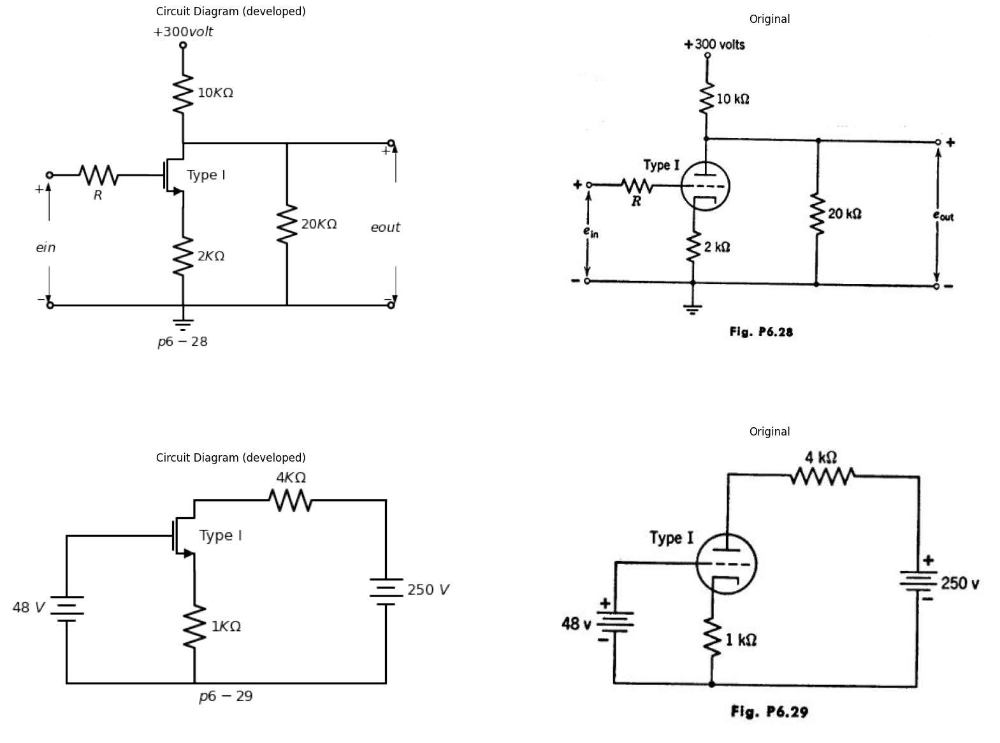

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('Type I ','right'))
d +=( R1:=elm.Resistor().down(d.unit*.85).label('$2{KΩ}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().up(d.unit*.85).label('$10{KΩ}$','bottom').at(M1.drain).label('$+300{volt}$','right').dot(open=True))
d +=( R3:=elm.Resistor().left(d.unit*.85).label('$R$','bottom').at(M1.gate).dot(open=True))
d +=(l1:= elm.Line().right(d.unit*.9).at(M1.drain))
d +=(l2:= elm.Line().right(d.unit*.9).at(R1.end))
d +=( R4:=elm.Resistor().down(d.unit*.85).label('$20{KΩ}$','bottom').endpoints(l1.end,l2.end))
d +=(l3:= elm.Line().right(d.unit*.9).at(R4.start).dot(open=True))
d +=(l4:= elm.Line().right(d.unit*.9).at(R4.end).dot(open=True))
d +=(l5:= elm.Line().left(d.unit*1.15).at(R1.end).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.5,-1))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.5,-3.2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{out}$', loc='start', color='black',ofst=0.3). at((6,-2))
d += elm.Ground().at(R1.end).label('$p6-28$','bottom')
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-3.5,-2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-3.5,-3.2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{in}$', loc='start', color='black',ofst=0.3). at((-3,-2.5))
d.save('images/6-28.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-28.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-28.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('Type I ','right'))
d +=( R1:=elm.Resistor().down(d.unit*.87).label('$1{KΩ}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().right(d.unit*1.5).label('$4{KΩ}$','top').at(M1.drain))
d += (E1 := elm.Battery().down().length(4.3).label('$250_ V $','bottom'))
d +=(l1:= elm.Line().left(d.unit*2.5).label('$p6-29$','bottom'))
d += (E2 := elm.Battery().up().length(3.47).label('$48_ V $','top').reverse())
d +=(l2:= elm.Line().right(d.unit*.8))
d.save('images/6-29.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-29.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-29.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

characteristic (eout vs. ei.) of the circuit shown in Fig. P6.30 over the range —20 < ei. < + 10 volts. The suggested method is to make a table of values
of e # eb, eh, (300 — eb)/50, is	ge	eki ecout = eb	ek, for e,	0, —4, —8
—12, —14, —16, from which the characteristic may be plotted.

(b) At ei. = 0, compute the plate dissipation ebb and the power supplied by the 300-volt source.

**6.38.** (a) For an input voltage ein = 8 cos 1000t volts in Fig. P6,30, make
a sketch (not a plot) of the manner in which the output voltage waveform is distorted from a true sinusoidal shape.

(b)	If harmonics higher than the second are ignored, the output voltage may be written in the form
eout = Ao Al cos(1000t 91) + A2 cos(20001 + 02) Evaluate the constants by sampling the wave at 1000t = —π , —π /2, 0, π /2,π 
(Hint: show that 01 = 02 = 0.) Express the ratio of A 2 to A 1 as a percentage second-harmonic distortion.

(c)	Ignoring the second harmonic and approximating the plate voltage by

the expression


$e_b= (\frac {eb_max +eb_min}{2})-(\frac {eb_max -eb_min}{2})cos1000t$

compute the time-average a-c power delivered to the 49-kilohm load, and also the time-average plate dissipation.

Text(0.5, 1.0, 'Original')

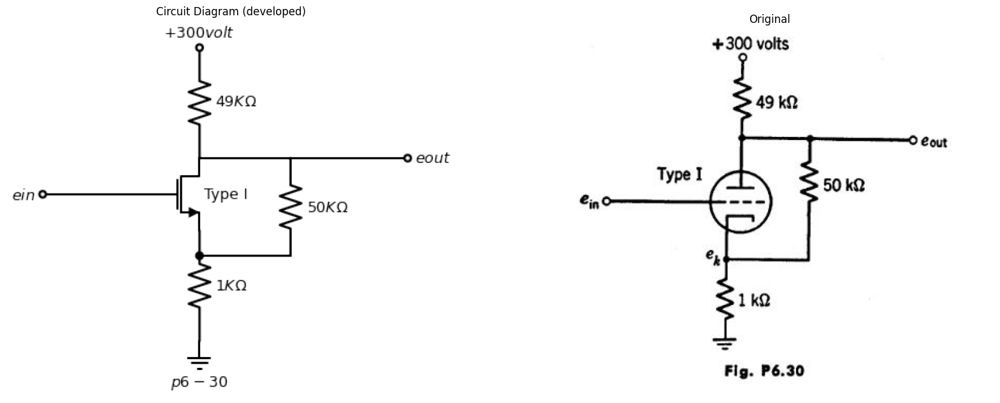

In [13]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('Type I ','right'))
d +=(l1:= elm.Line().left(d.unit*.9).label('$e{in}$','left').dot(open=True).at(M1.gate))
d +=( R1:=elm.Resistor().down(d.unit*.85).label('$1{KΩ}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().up(d.unit*.85).label('$49{KΩ}$','bottom').at(M1.drain).label('$+300{volt}$','right').dot(open=True))
d +=(l2:= elm.Line().right(d.unit*.7).at(M1.drain))
d +=( R3:=elm.Resistor().down(d.unit*.75).label('$50{KΩ}$','bottom'))
d +=(l3:= elm.Line().left(d.unit*.7).dot())
d +=(l4:= elm.Line().right(d.unit*.9).label('$e{out}$','right').dot(open=True).at(R3.start))
d += elm.Ground().at(R1.end).label('$p6-30$','bottom')
d.save('images/6-30.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-30.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-30.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


(d) How does the time-average plate dissipation compare with the no-signal value found in Problem 6.37? Explain the difference.

**6.39.** For an input voltage ei,, = 0.8 cos 10001 volts in Fig. P6.301 the output voltage may be written as 6.0lit = A + Al cos 10001.

**(a)**	Using the appropriate linear incremental equivalent circuit, find the value of A 1.

**(b)	**How does the voltage amplification	O. compare with the corre- 
sponding ratio (A1/8) in Problem 6.3S?

**(c)** How does the voltage amplification compare with the slope of the output-input characteristic found in Problem 6.37? At what point should the slope be compared?

(d)	How does the value of A compare with the value found in Problem 6.38? Explain the difference.

**6.40.** In Fig. P6.31, a triangular waveform el (t) is to be converted into a trapezoidal wave e2 (fl by the circuit shown in Fig. P6.32. Assume a piecewise-linear model for the triode (m = 20, rz, = 10 kilohms, r = 0), and assume grid current is negligible in comparison with plate current. Determine the values required for 14, Rk, and R.

**6.41.** (a) For the circuit shown in Fig. P6.33, locate the operating point of the tube on Type I triode characteristics. Use a systematic procedure and not pure trial and error. Assume i 1 = 0.

(b) For the circuit of Fig. P6.33, determine the tube parameters at the operating point and calculate incremental voltage gain Ake2/Aex, input im-
pedance lei	lr and output impedance.

**6.42.** The circuit in Fig. P6.34 is called a phase inverter. It provides two outputs e2 and e4. The input voltage el is sinusoidal and of a high enough


Text(0.5, 1.0, 'Original')

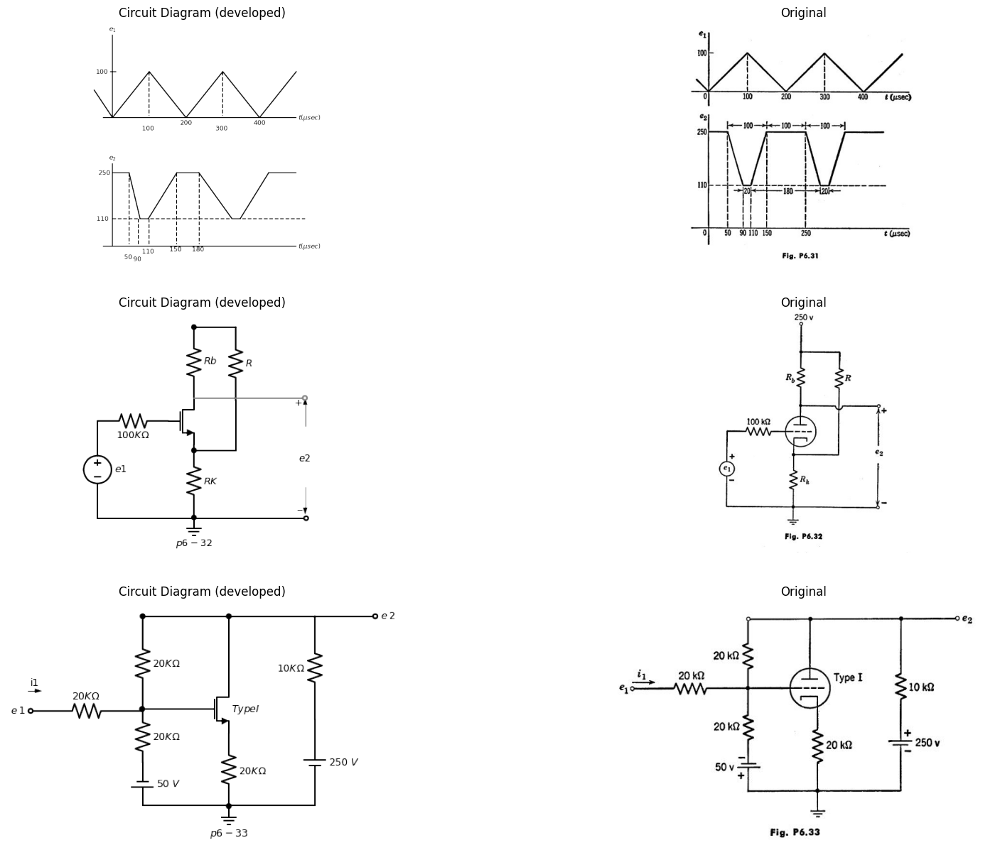

In [12]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=(l1:= elm.Line().up(d.unit*1.5).label('$e _1 $','right'))
d +=(l2:= elm.Line().right(d.unit*3.5).at((-.5,0)).label('$t(μsec) $','right'))
d +=(l3:= elm.Line().up(d.unit*.0001).color('black').at((0,0)))
d +=(l4:= elm.Line().up(d.unit*.0001).color('black').at((4,0)).label('$200 $','left'))
d +=(l5:= elm.Line().up(d.unit*.0001).color('black').at((8,0)).label('$400 $','left'))
d +=(l6:= elm.Line().up(d.unit*.0001).color('black').at((2,2.5)))
d +=(l7:= elm.Line().up(d.unit*.0001).color('black').at((6,2.5)))
d +=(l8:= elm.Line().up(d.unit*.0001).color('black').at((10,2.5)))
d +=(l9:= elm.Line().up(d.unit*.0001).color('black').at((-1,1.5)))
d +=(l10:= elm.Line().right(d.unit*.1).color('black').at((-.12,2.5)).label('$100 $','left'))
d +=(l11:= elm.Line().right(d.unit*.1).color('black').endpoints(l3.end,l6.end))
d +=(l12:= elm.Line().right(d.unit*.1).color('black').endpoints(l4.end,l6.end))
d +=(l13:= elm.Line().right(d.unit*.1).color('black').endpoints(l4.end,l7.end))
d +=(l14:= elm.Line().right(d.unit*.1).color('black').endpoints(l5.end,l7.end))
d +=(l15:= elm.Line().right(d.unit*.1).color('black').endpoints(l5.end,l8.end))
d +=(l16:= elm.Line().right(d.unit*.1).color('black').endpoints(l3.end,l9.end))
d +=(l17:= elm.Line().down(d.unit*.8).color('black').at((2,2.5)).linestyle('--').label('\n100 ','left'))
d +=(l18:= elm.Line().down(d.unit*.8).color('black').at((6,2.5)).linestyle('--').label('\n300 ','left'))
d +=(l19:= elm.Line().up(d.unit*1.5).label('$e _2 $','right').at((0,-7)))
d +=(l20:= elm.Line().right(d.unit*3.5).at((-.5,-7)).label('$t(μsec) $','right'))
d +=(l21:= elm.Line().right(d.unit*.3).at((0,-3)).label('$250 $','left'))
d +=(l22:= elm.Line().right(d.unit*3.5).color('black').at((0,-5.5)).linestyle('--').label('110 ','left'))
d +=(l23:= elm.Line().right(d.unit*.15).at((1.5,-5.5)))
d +=(l24:= elm.Line().right(d.unit*.4).at((3.5,-3)))
d +=(l25:= elm.Line().right(d.unit*.15).at((6.5,-5.5)))
d +=(l26:= elm.Line().right(d.unit*.5).at((8.5,-3)))
d +=(l27:= elm.Line().right(d.unit*.1).color('black').endpoints(l21.end,l23.start))
d +=(l28:= elm.Line().right(d.unit*.1).color('black').endpoints(l23.end,l24.start))
d +=(l29:= elm.Line().right(d.unit*.1).color('black').endpoints(l25.start,l24.end))
d +=(l28:= elm.Line().right(d.unit*.1).color('black').endpoints(l25.end,l26.start))
d +=(l29:= elm.Line().down(d.unit*1.3).color('black').at((.9,-3)).linestyle('--').label('\n50 ','left'))
d +=(l30:= elm.Line().down(d.unit*.5).color('black').at((1.4,-5.5)).linestyle('--').label('\n90 ','left'))
d +=(l31:= elm.Line().down(d.unit*.5).color('black').at((2,-5.5)).linestyle('--').label('110 ','left'))
d +=(l32:= elm.Line().down(d.unit*1.3).color('black').at((3.5,-3)).linestyle('--').label('150 ','left'))
d +=(l33:= elm.Line().down(d.unit*1.3).color('black').at((4.7,-3)).linestyle('--').label('180 ','left'))
d.save('images/6-31.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-31.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-31.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d +=( R1:=elm.Resistor().down(d.unit*.88).label('$R{K}$','bottom').at(M1.source).dot())
d +=( R2:=elm.Resistor().left(d.unit*.85).label('$100{KΩ}$','bottom').at(M1.gate))
d +=( R3:=elm.Resistor().up(d.unit*.85).label('$R{b}$','bottom').at(M1.drain).dot())
d += (E1 := elm.SourceV().down().length(3.5).label('$e 1 $','bottom').reverse().at(R2.end))
d +=(l1:= elm.Line().right(d.unit*2.5).dot(open=True))
d +=(l2:= elm.Line().right(d.unit*.5).at(R3.end))
d +=( R4:=elm.Resistor().down(d.unit*.88).label('$R$','bottom'))
d +=(l3:= elm.Line().down(d.unit*.6))
d +=(l4:= elm.Line().left(d.unit*.5).dot())
d +=(l5:= elm.Line().right(d.unit*1.33).at(M1.drain).dot(open=True).color('gray'))
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((4,-1))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((4,-3.2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((4.5,-2))
d += elm.Ground().at(R1.end).label('$p6-32$','bottom')
d.save('images/6-32.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-32.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-32.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type I$','right'))
d +=( R1:=elm.Resistor().down(d.unit*.85).label('$20{KΩ}$','bottom').at(M1.source).dot())
d +=(l1:= elm.Line().left(d.unit*.7).at(M1.gate).dot())
d +=(l2:= elm.Line().up(d.unit*.8).at(M1.drain).dot())
d +=(l3:= elm.Line().left(d.unit*1).dot())
d +=( R2:=elm.Resistor().down(d.unit*1.1).label('$20{KΩ}$','bottom'))
d +=( R3:=elm.Resistor().down(d.unit*.6).label('$20{KΩ}$','bottom'))
d += (E1 := elm.BatteryCell().down().length(1.5).label('$50_ V $','bottom').reverse())
d +=(l4:= elm.Line().right(d.unit*2))
d +=( R3:=elm.Resistor().left(d.unit*1.3).label('$20{KΩ}$','top').dot(open=True).at(R2.end).label('$e_ 1 $','left'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i1', color='black',ofst=0.1). at((-7,-.2))
d += (E2 := elm.BatteryCell().up().length(3).label('$250_ V $','bottom').reverse().at(l4.end))
d +=( R4:=elm.Resistor().up(d.unit*1.2).label('$10{KΩ}$','top'))
d +=(l5:= elm.Line().left(d.unit*2))
d +=(l6:= elm.Line().right(d.unit*.7).dot(open=True).at(R4.end).label('$e_ 2 $','right'))
d += elm.Ground().at(R1.end).label('$p6-33$','bottom')
d.save('images/6-33.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-33.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-33.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')


frequency that the reactance of the capacitors C1 can be neglected. The circuit operates only in the negative-grid region. Using a linear incremental circuit = 100, r2 = 50 kilohms) find the gains e2 lei and Wei, and the phase angle between e2 and es.

Text(0.5, 1.0, 'Original')

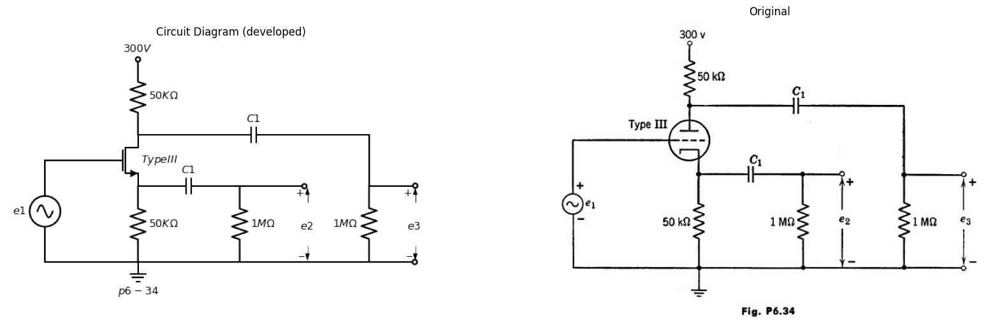

In [9]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type III$','right'))
d +=( R1:=elm.Resistor().down(d.unit*.82).label('$50{KΩ}$','bottom').at(M1.source))
d +=( R2:=elm.Resistor().up(d.unit*.82).label('$50{KΩ}$','bottom').at(M1.drain).dot(open=True).label('$300{V}$','right'))
d +=(l1:= elm.Line().left(d.unit*.7).at(M1.gate))
d += (E1 := elm.SourceSin().down().length(3.3).label('$ e{1} $','top').reverse())
d +=(l2:= elm.Line().right(d.unit*4).dot(open=True))
d +=( C1:=elm.Capacitor().right(d.unit*1.1).label('$C{1}$','top').at(M1.source))
d +=( R3:=elm.Resistor().down(d.unit*.82).label('$1{MΩ}$','bottom'))
d +=(l3:= elm.Line().right(d.unit*.7).dot(open=True).at(R3.start))
d +=( C2:=elm.Capacitor().right(d.unit*2.5).label('$C{1}$','top').at(M1.drain))
d +=(l4:= elm.Line().down(d.unit*.55))
d +=( R4:=elm.Resistor().down(d.unit*.82).label('$1{MΩ}$','top'))
d +=(l5:= elm.Line().right(d.unit*.5).dot(open=True).at(R4.start))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.5,-2.2))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.5,-3.6))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((6,-2.8))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((9,-2.2))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((9,-3.6))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{3}$', loc='start', color='black',ofst=0.3). at((9.5,-2.8))
d += elm.Ground().at(R1.end).label('$p6-34$','bottom')
d.save('images/6-34.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-34.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-34.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.43.** For the cascode circuit of Fig, P6.35, in which the tubes are assumed to be identical and piecewise-linear:

(a)	Sketch and dimension the boundary of the region in the V/Ebb versus edEbb plane within which both tubes conduct plate current but no grid current.

(b)	Sketch and dimension the curve of e2 vs. e1. Use the value of V giving the widest range of el between cutoff and grid current. What is the value of A ∆e2/∆ei?


Text(0.5, 1.0, 'Original')

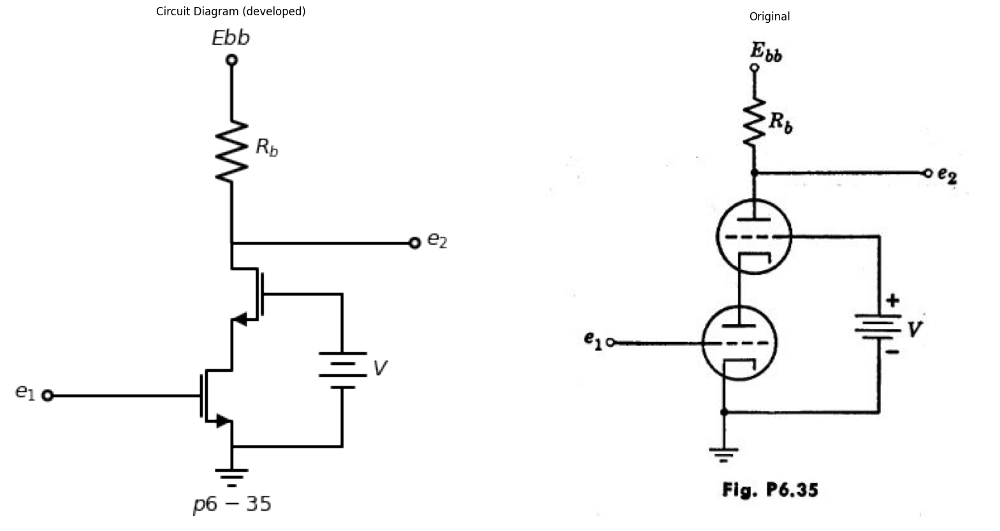

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0).at(M1.drain))
d += elm.Ground().at(M1.source).label('$p6-35$','bottom')
d +=(l1:= elm.Line().left(d.unit*.7).at(M1.gate).dot(open=True).label('$e_1$','left'))
d +=(l2:= elm.Line().right(d.unit*.3).at(M2.gate))
d += (E1 := elm.Battery().down().length(2.5).label('$ V $','bottom'))
d +=(l3:= elm.Line().left(d.unit*.6))
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R_b$','bottom').at(M2.drain).dot(open=True).label('$E{bb}$','right'))
d +=(l4:= elm.Line().right(d.unit*1).at(M2.drain).dot(open=True).label('$e_2$','right'))
d.save('images/6-35.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-35.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-35.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.44.** When operating in the negative grid-voltage region the vacuum triodes in the circuit shown in Fig. P6.36 can both be represented by a linear circuit model with plate resistance rp, and amplification factor het Find the

Text(0.5, 1.0, 'Original')

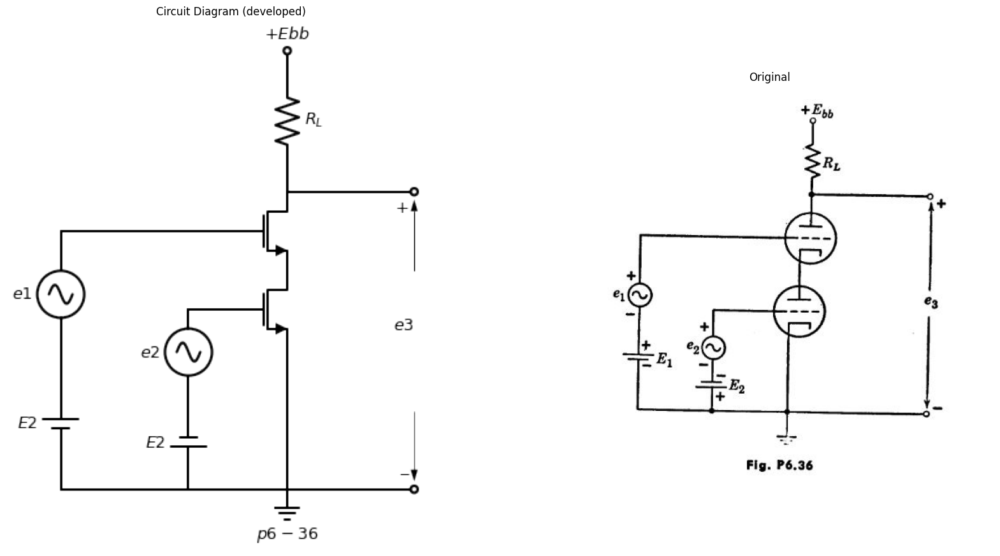

In [7]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0).reverse().at(M1.drain))
d +=(l1:= elm.Line().down(d.unit*1).at(M1.source))
d +=(l2:= elm.Line().left(d.unit*.7))
d += (E1 := elm.BatteryCell().up().length(2).label('$ E{2} $','top'))
d += (E2 := elm.SourceSin().up().length(1.84).label('$ e{2} $','top').reverse())
d +=(l3:= elm.Line().right(d.unit*.5))
d +=(l2:= elm.Line().left(d.unit*1.3).at(M2.gate))
d += (E3 := elm.SourceSin().down().length(2.7).label('$ e{1} $','top').reverse())
d += (E4 := elm.BatteryCell().down().length(2.8).label('$ E{2} $','top'))
d +=(l3:= elm.Line().right(d.unit*.9))
d += elm.Ground().at(l1.end).label('$p6-36$','bottom')
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R_L$','bottom').at(M2.drain).dot(open=True).label('$+E{bb}$','right'))
d +=(l4:= elm.Line().right(d.unit*.9).at(M2.drain).dot(open=True))
d +=(l5:= elm.Line().right(d.unit*.9).at(l1.end).dot(open=True))
d += elm.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((2.7,0))
d += elm.Arrow().down().length(1.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2.7,-3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{3}$', loc='start', color='black',ofst=0.3). at((3,-1))
d.save('images/6-36.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-36.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-36.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


incremental output voltage as a function of the input voltages el and e 2. Assume that the biasing voltages are such that the triodes operate in the negative grid region.

**6.45.** Assuming that the tubes are operating linearly and have equal and rp, determine the gain eilei, and the output impedance of the circuit shown in Fig. P6.37.


Text(0.5, 1.0, 'Original')

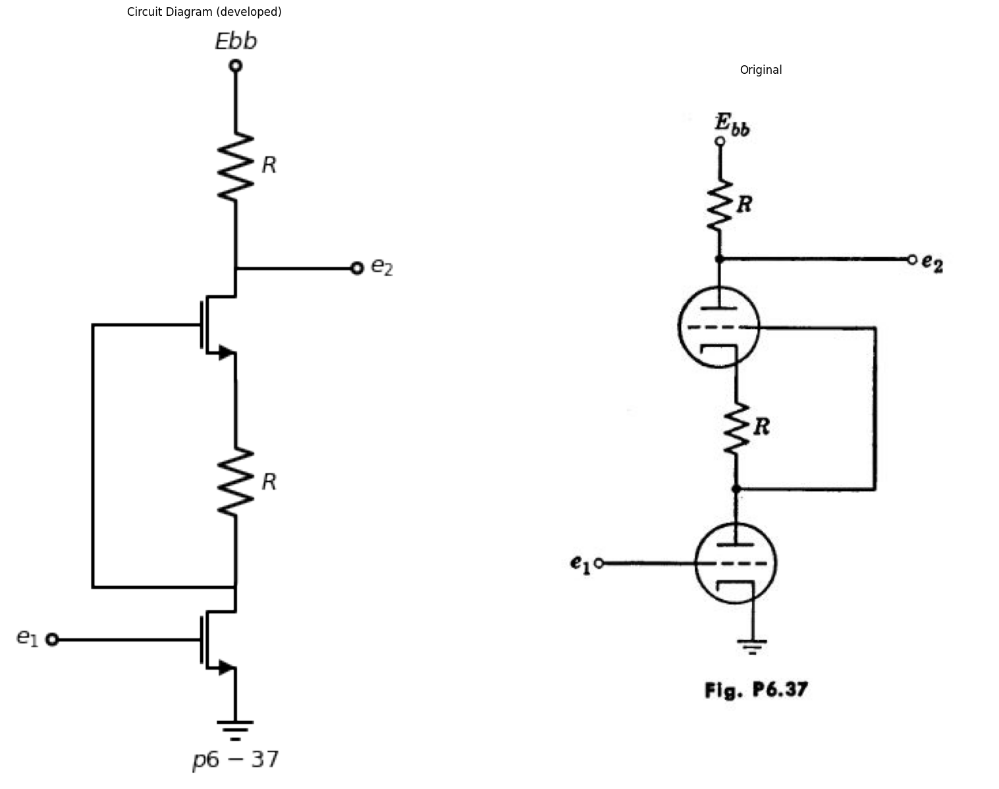

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += elm.Ground().at(M1.source).label('$p6-37$','bottom')
d +=(l1:= elm.Line().left(d.unit*.6).label('$ e_1$','left').at(M1.gate).dot(open=True))
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R$','bottom').at(M1.drain))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0).reverse())
d +=(l2:= elm.Line().left(d.unit*.4).at(M2.gate))
d +=(l3:= elm.Line().down(d.unit*1.3))
d +=(l4:= elm.Line().right(d.unit*.7))
d +=( R1:=elm.Resistor().up(d.unit*1).label('$R$','bottom').at(M2.drain).dot(open=True).label('$E{bb}$','right'))
d +=(l5:= elm.Line().right(d.unit*.6).label('$ e_2$','right').at(M2.drain).dot(open=True))
d.save('images/6-37.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-37.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-37.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.46.** Locate the static operating point of the circuit in Fig. P6.38.

Text(0.5, 1.0, 'Original')

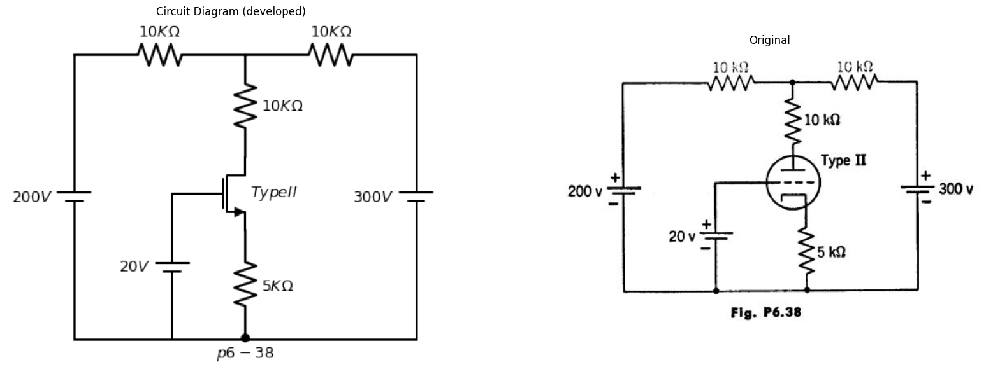

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type II$','right'))
d +=(l1:= elm.Line().left(d.unit*.25).at(M1.gate))
d += (E1 := elm.BatteryCell().down().length(3.34).label('$ 20{V} $','top').at(l1.end))
d +=( R1:=elm.Resistor().down(d.unit*.82).label('$5{KΩ}$','bottom').dot().at(M1.source))
d +=( R2:=elm.Resistor().up(d.unit*.78).label('$10{KΩ}$','bottom').at(M1.drain))
d +=( R3:=elm.Resistor().left(d.unit*1.3).label('$10{KΩ}$','top').at(R2.end))
d +=( R4:=elm.Resistor().right(d.unit*1.3).label('$10{KΩ}$','top').at(R2.end))
d += (E2 := elm.BatteryCell().down().length(6.5).label('$ 200{V} $','top').at(R3.end))
d += (E3 := elm.BatteryCell().down().length(6.5).label('$ 300{V} $','top').at(R4.end))
d +=(l1:= elm.Line().left(d.unit*2.6).label('$ p6-38 $','bottom'))
d.save('images/6-38.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-38.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-38.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.47.** In Fig. P6,39, determine the incremental amplification eilei as a function of the circuit constants. The two tubes are identical. Find the output impedance.

**6.48.** Using the tube characteristics find the operating points by trial and error for the two Type I triodes in the cathode coupled amplifier shown in Fig. P6.40. Find the incremental parameters for the two tubes at their respective operating points and using these values, determine the incremental output impedance of the amplifier. (R2 is to be regarded as the output load.) Derive your results using suitable literal symbols for the circuit coefficients. Substitute uumPrical quantities only after obtaining your results in literal form,


Text(0.5, 1.0, 'Original')

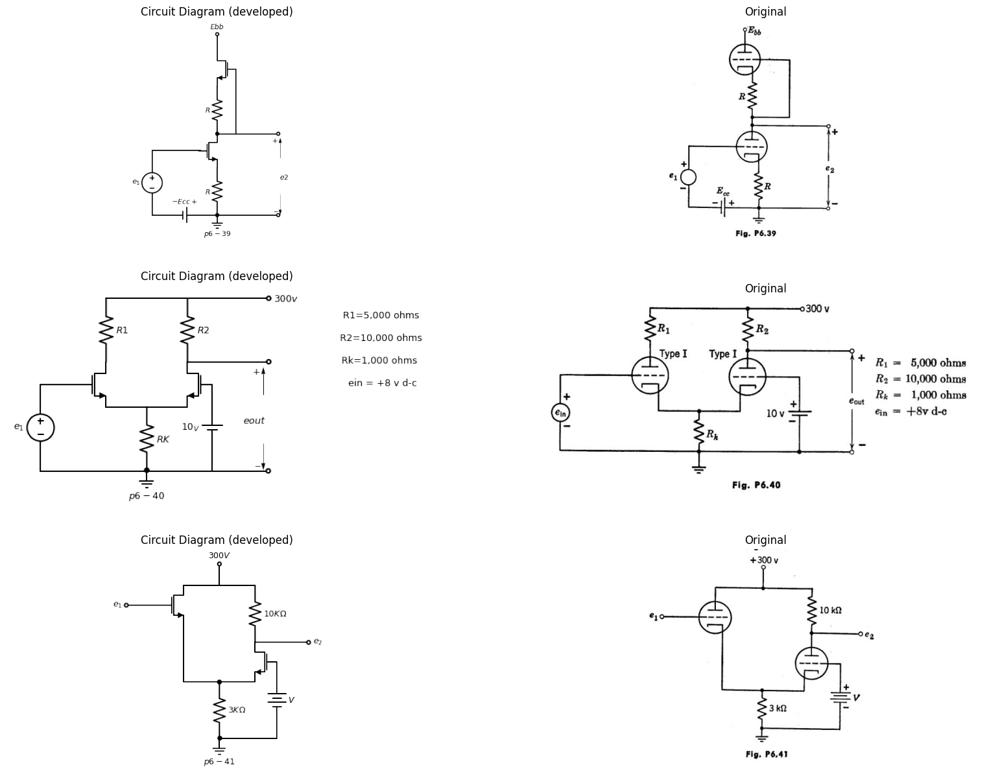

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0))
d += elm.Line().up(d.unit*.3).at(M1.drain).label('$E{bb}$','right').dot(open=True)
d += (l1:=elm.Line().down(d.unit*1.06).at(M1.gate))
d +=( R1:=elm.Resistor().down(d.unit*.78).label('$R$','top').dot().at(M1.source))
d += elm.Line().left(d.unit*.3).at(l1.end)
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().at(R1.end))
d +=( R2:=elm.Resistor().down(d.unit*.78).label('$R$','top').dot().at(M2.source))
d += (E1 := elm.BatteryCell().left().length(3.2).label('$- E{cc} +$','top'))
d += (E2 := elm.SourceV().up().length(3.18).label('$e_1$','top'))
d += elm.Line().right(d.unit*.8)
d += elm.Line().right(d.unit*1).at(R2.end).dot(open=True)
d += elm.Line().right(d.unit*1).at(M2.drain).dot(open=True)
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((3.1,-5.2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((3.1,-7))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{2}$', loc='start', color='black',ofst=0.3). at((3.8,-6))
d += elm.Ground().at(R2.end).label('$p6-39$','bottom')
d.save('images/6-39.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-39.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-39.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += elm.Line().left(d.unit*.5).at(M1.gate)
d += (E1 := elm.SourceV().down().length(3.2).label('$e_1$','top').reverse())
d += elm.Line().right(d.unit*2.8).dot(open=True)
d += (l1:= elm.Line().right(d.unit*.5).at(M1.source))
d +=( R1:=elm.Resistor().down(d.unit*.78).label('$R{K}$','bottom').dot())
d += (l2:= elm.Line().right(d.unit*.5).at(R1.start))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0).at(l2.end))
d += (E1 := elm.BatteryCell().down().length(3.2).label('$10_V$','top').at(M2.gate))
d +=( R2:=elm.Resistor().up(d.unit*.78).label('$R{1}$','bottom').at(M1.drain))
d +=( R3:=elm.Resistor().up(d.unit*.78).label('$R{2}$','bottom').at(M2.drain))
d += (l3:= elm.Line().right(d.unit*2).at(R2.end).label('$300v$','right').dot(open=True))
d += (l4:= elm.Line().right(d.unit*1).at(M2.drain).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.8,-1.2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.8,-3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{out}$', loc='start', color='black',ofst=0.3). at((6.2,-2))
d += elm.Ground().at(R1.end).label('$p6-40$','bottom')
d += elm.Line().right(d.unit*.1).at((10,2)).label('R1=5,000 ohms\n\n R2=10,000 ohms \n\nRk=1,000 ohms \n\n ein = +8 v d-c','bottom',color='black').color('white')
d.save('images/6-40.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-40.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-40.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += elm.Line().left(d.unit*.5).at(M1.gate).label('$e_1$','left').dot(open=True)
d +=(l1:= elm.Line().right(d.unit*.5).at(M1.drain))
d += elm.Line().up(d.unit*.3).label('$300V$','right').dot(open=True)
d += elm.Line().right(d.unit*.5).at(l1.end)
d +=( R1:=elm.Resistor().down(d.unit*.8).label('$10{KΩ}$','bottom'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).at(R1.end))
d +=(l2:= elm.Line().left(d.unit*.5).at(M2.source).dot())
d +=(l3:= elm.Line().left(d.unit*.5))
d +=(l4:= elm.Line().up(d.unit*.8))
d +=( R2:=elm.Resistor().down(d.unit*.8).label('$3{KΩ}$','bottom').at(l2.end))
d += elm.Ground().at(R2.end).label('$p6-41$','bottom')
d += (E1 := elm.Battery().down().length(3.2).at(M2.gate).label('$V$','bottom'))
d +=(l4:= elm.Line().left(d.unit*.8).dot())
d += elm.Line().right(d.unit*.75).at(M2.drain).label('$e_2$','right').dot(open=True)
d.save('images/6-41.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-41.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-41.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

**6.49.** Using a piecewise-linear triode model with I. = 40, rp = 40 kilohnas, plot 02 versus el for the cathode-coupled amplifier shown in Fig. P6.41. Use that value of V which yields the widest amplification region (both tubes con-ducting) subject to the restriction that neither tube shall draw grid current in this region.

Text(0.5, 1.0, 'Original')

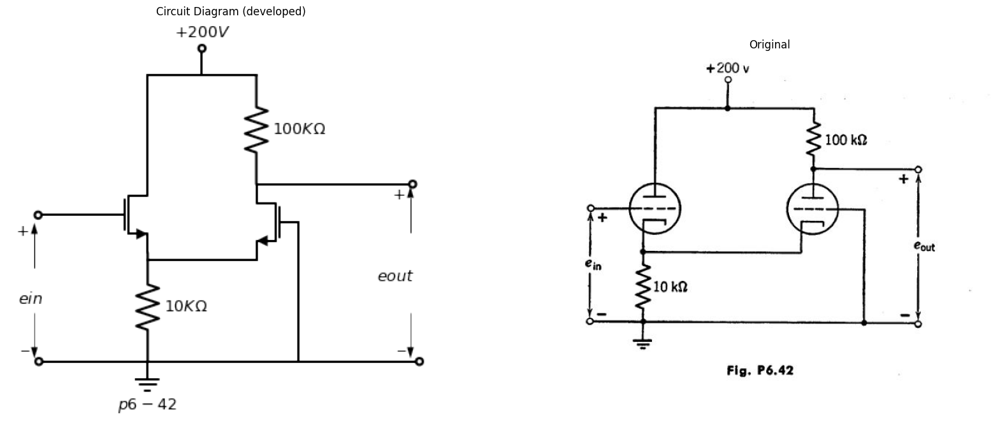

In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += elm.Line().up(d.unit*.75).at(M1.drain)
d += elm.Line().right(d.unit*.4)
d += (l1:=elm.Line().up(d.unit*.2).dot(open=True).label('$+200V$','right'))
d += elm.Line().right(d.unit*.4).at(l1.start)
d +=( R1:=elm.Resistor().down(d.unit*.8).label('$100{KΩ}$','bottom'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).at(R1.end))
d +=( R2:=elm.Resistor().down(d.unit*.8).label('$10{KΩ}$','bottom').at(M1.source))
d += elm.Line().left(d.unit*.8).at(M2.source)
d += elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True)
d += elm.Line().left(d.unit*.8).at(R2.end).dot(open=True)
d += elm.Line().right(d.unit*2).at(R2.end).dot(open=True)
d += elm.Line().down(d.unit*1.02).at(M2.gate)
d += elm.Line().right(d.unit*1.15).at(M2.drain).dot(open=True)
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2.5,-2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2.5,-3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{in}$', loc='start', color='black',ofst=0.3). at((-2,-2.5))
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((5.8,-1.2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((5.8,-3))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e{out}$', loc='start', color='black',ofst=0.3). at((6.2,-2))
d += elm.Ground().at(R2.end).label('$p6-42$','bottom')
d.save('images/6-42.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-42.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-42.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.50.** For the circuit of Fig, P6.42, plot the complete output-input charac-teristic for an input voltage range from —15 to +10 volts. Both tubes have A = 50, rp = 40 kilohms.

**6.51.** Using a piecewise-linear model of a triode with = 20 and rp =- 10 kilohms, design single-stage amplifiers to fulfill the following requirements:
Amplifier No, 1: The incremental voltage gain is to be 19. The input signal, derived from a generator with a 20-kilohm source impedance, has a maximum amplitude of 15 volts peak to peak.
Amplifier No. 2: For a fixed value of el, this amplifier containing no trans-formers must deliver the maximum possible power to a. 500-ohm load,
Amplifier No. 3: This amplifier is to have an incremental gain of 5, and must be designed to reduce the dependence of the gain on the A of the tube.


Text(0.5, 1.0, 'Original')

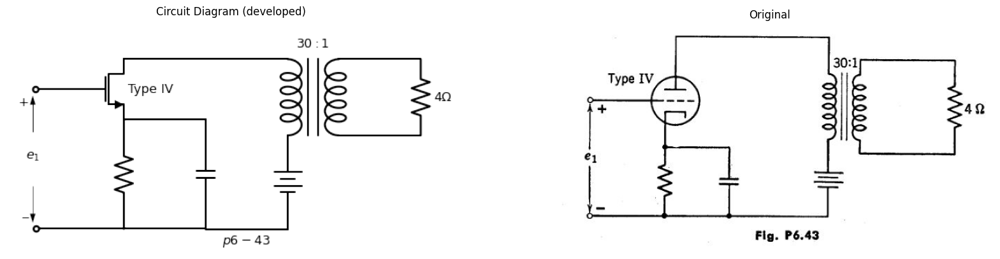

In [8]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).label('Type IV','right').reverse())
d += elm.Line().left(d.unit*.5).dot(open=True).at(M1.gate)
d +=( R1:=elm.Resistor().down().at(M1.source))
d += elm.Line().left(d.unit*.8).dot(open=True)
d += elm.Line().right(d.unit*.75).at(R1.start)
d += elm.Capacitor().down(d.unit*1)
d += elm.Line().left(d.unit*.75)
d += elm.Line().right(d.unit*1.5).at(M1.drain)
d += (T1:=elm.Transformer(loop=True).right().anchor('p1'))
d += (E1 := elm.Battery().down().length(2.58).at(T1.p2))
d += elm.Line().left(d.unit*.75).label('$p6-43$','bottom')
d += (l1:= elm.Line().right(d.unit*.75).at(T1.s1))
d +=(l2:= elm.Line().right(d.unit*.75).at(T1.s2))
d +=( R2:=elm.Resistor().down().endpoints(l1.end,l2.end).label('$4{Ω}$','bottom'))
d += elm.Line().right(d.unit*.00005).at((5.2,.7)).label('$30:1$','bottom',color='black').color('white')
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-2.5,-2))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-2.5,-3.5))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e_1$', loc='start', color='black',ofst=0.3). at((-2,-2.5))
d.save('images/6-43.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-43.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-43.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.52.** The quiescent operating point of the Type IV triode in the amplifier circuit of Fig.. P6.43 is at ib = 60 ma, e.	—60 volts. For the purpose of

this problem, the transformer may be considered ideal and the capacitor to have zero impedance.

(a)	Determine the quiescent plate dissipation.

(b)	Assuming essentially linear operation, determine the amplitude of the sinusoidal grid signal required to develop watt in the 4-ohm resistor.

(c)	Determine the average plate dissipation when the signal specified in part (b) is applied. (The slight change in average plate current which occurs when the signal is impressed may be neglected.)


Text(0.5, 1.0, 'Original')

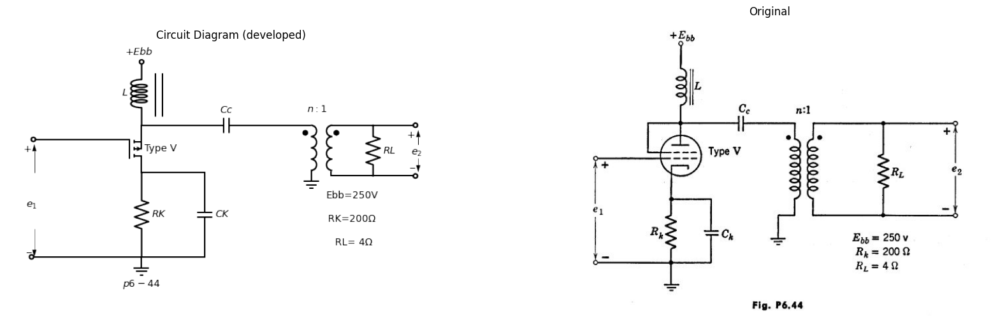

In [7]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.PMos().anchor('drain').theta(0).label('Type V','right'))
d += elm.Line().left(d.unit*1).at(M1.gate).dot(open=True)
d +=( R1:=elm.Resistor().down().label('$R{K}$','bottom').at(M1.drain))
d += elm.Line().left(d.unit*1.3).dot(open=True)
d += elm.Line().right(d.unit*.75).at(R1.start)
d += elm.Capacitor().down(d.unit*1).label('$C{K}$','bottom')
d += elm.Line().left(d.unit*.75)
d += elm.Ground().at(R1.end).label('$p6-44$','bottom')
d += elm.Inductor2().up(d.unit*.75).at(M1.source).reverse().label('$L$','top').dot(open=True).label('$+E{bb}$','right')
d += elm.Line().up(d.unit*.5).at((.5,2))
d += elm.Line().up(d.unit*.5).at((.75,2))
d += elm.Capacitor().right(d.unit*2).label('$C{c}$','top').at(M1.source)
d += elm.Transformer(core=False).right().anchor('p1')
d += elm.Ground().at((6.01,0.08))
d += elm.Line().right(d.unit*.5).at((6.7,1.67))
d +=( R2:=elm.Resistor().down(d.unit*.6).label('$R{L}$','bottom'))
d += elm.Line().left(d.unit*.5).label('\nEbb=250V\n\n RK=200Ω \n\n RL= 4Ω','bottom')
d += elm.Line().up(d.unit*.05)
d += elm.Line().right(d.unit*.5).at(R2.start).dot(open=True)
d += elm.Line().right(d.unit*.5).at(R2.end).dot(open=True)
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-3.8,0))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-3.8,-2))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e_1$', loc='start', color='black',ofst=0.3). at((-3.4,-1))
d += elm.Line().right(d.unit*.00005).at((5.8,1.4)).dot()
d += elm.Line().right(d.unit*.00005).at((6.9,1.4)).dot()
d += elm.Line().right(d.unit*.00005).at((6.2,2.5)).label('$n:1$','bottom',color='black').color('white')
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((9.8,1))
d += elm.Arrow().down().length(.5).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((9.8,.5))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$e_2$', loc='start', color='black',ofst=0.3). at((10.25,.85))
d.save('images/6-44.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-44.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-44.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


**6.53.** In Fig. P6.44 is shown the circuit of a shunt-fed amplifier. At the frequency of operation, the reactance of the inductor L is very large, and the reactances of the capacitors CK and Cc are very small. The inductor resist¬ance is negligible and the transformer is ideal.

(a)	Determine on the Type V trio-de characteristics the operating point (eb and ib) when 81 = 0.

(b)	If ei = 0.1 sin wt, what is the turns ratio n for maximum power transfer to the load RL?

(c)	Draw on the characteristics the operating path of the tube when el = 5 sin wt.

(d)	Determine from the incremental equivalent circuit the voltage gain of the circuit, A — zleilziei, at the operating point.

**6.54.** The circuit shown in Fig. P6.45 provides an adjustable supply voltage V for a resistive vacuum-tube load that draws a current varying between 0 and 10 ma. Determine the value of Ei required to make V = 150 volts when 1 = 5 ma. With this value of E1, determine V for I= 0 and 10 ma, and calculate the percent regulation.

**6.55.** The circuit shown in Fig. P6.46 provides an adjustable supply voltage for the variable load 1?. Assume the triode to be linear with = 40 and
20 kilohms. For a given value of El and with ec 0 the circuit provides some voltage regulation. Determine (a) and (b) as functions of E.




Text(0.5, 1.0, 'Original')

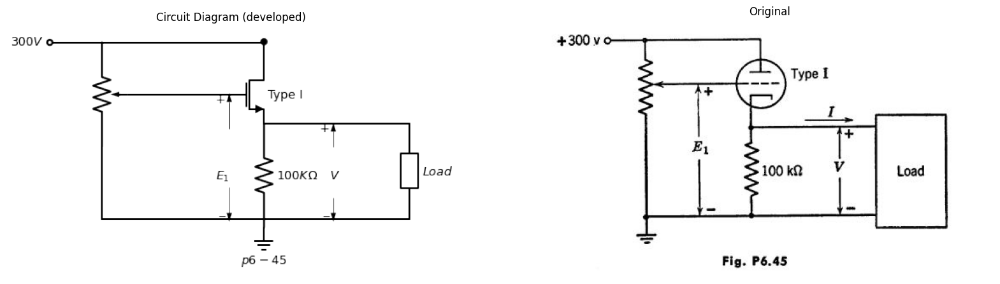

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).label('Type I','right').reverse())
d +=( R2:=elm.Resistor().down().label('$100{KΩ}$','bottom').at(M1.source))
d +=( R3:= elm.Line().left().at(M1.gate))
d += (R1 := elm.PotentiometerIEEE().down().at((-4.67,.67)))
d += elm.Ground().at(R2.end).label('$p6-45$','bottom')
d += elm.Line().left(d.unit*.5).at(R1.start).dot(open=True).label('$300{V}$','left')
d += elm.Line().up(d.unit*.23).dot().at(M1.drain)
d += elm.Line().down(d.unit*.7).at(R1.end)
d += elm.Line().right(d.unit*2.95)
d += elm.Line().right(d.unit*1.4).at(R2.start)
d += elm.ResistorIEC().down().length(2.75).label('$Load$','bottom')
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1,-1.8))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1,-3.5))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$E_1$', loc='start', color='black',ofst=0.3). at((-.7,-3))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((2,-2.35))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2,-3.8))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((2.5,-3))
d += elm.Line().right(d.unit*1.55).at(R1.start)
d.save('images/6-45.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-45.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-45.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


(a)	Open-circuit voltage available at the load.

(b)	Maximum load current for which reasonable voltage regulation is obtained.

Text(0.5, 1.0, 'Original')

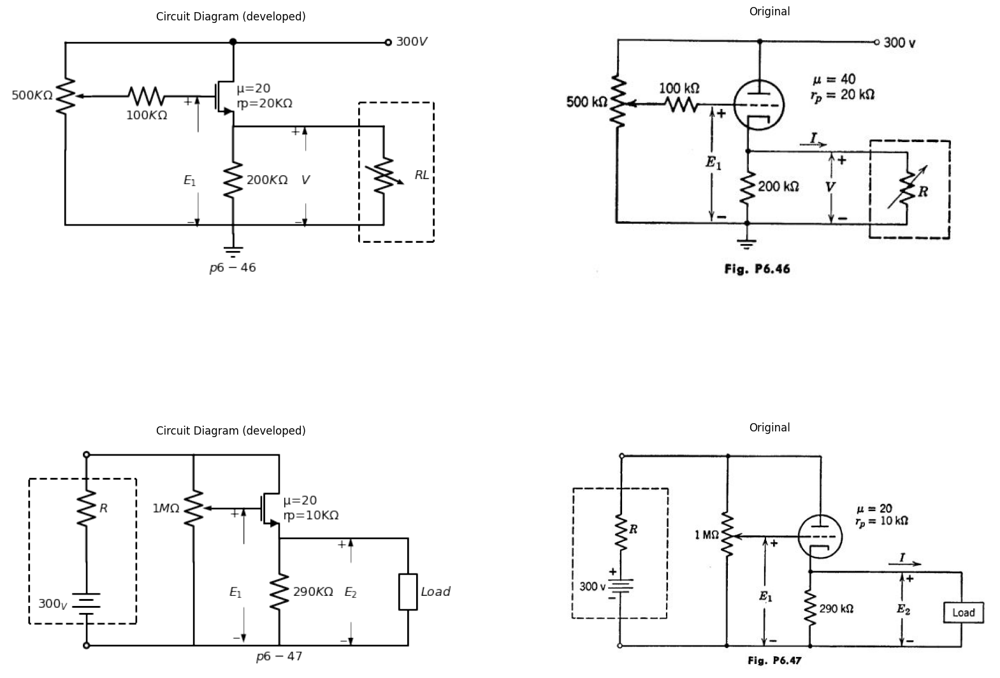

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).label('μ=20\nrp=20KΩ','right').reverse())
d +=( R2:=elm.Resistor().down().label('$200{KΩ}$','bottom').at(M1.source))
d +=( R3:= elm.Resistor().left().label('$100{KΩ}$','bottom').at(M1.gate))
d += (R1 := elm.PotentiometerIEEE().down().label('$500{KΩ}$','top').at((-4.67,.67)))
d += elm.Ground().at(R2.end).label('$p6-46$','bottom')
d += elm.Line().right(d.unit*3).at(R1.start).dot(open=True).label('$300{V}$','right')
d += elm.Line().up(d.unit*.23).dot().at(M1.drain)
d += elm.Line().down(d.unit*.7).at(R1.end)
d += elm.Line().right(d.unit*2.95)
d += elm.Line().right(d.unit*1.4).at(R2.start)
d += elm.ResistorVarIEEE().down(d.unit*.92).label('$R{L}$','bottom')
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1,-1.8))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1,-3.5))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$E_1$', loc='start', color='black',ofst=0.3). at((-.7,-3))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((2,-2.35))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2,-3.8))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((2.5,-3))
d += elm.Line().right(d.unit*.7).linestyle('--').at((3.5,-1))
d += elm.Line().down(d.unit*1.3).linestyle('--')
d += elm.Line().left(d.unit*.7).linestyle('--')
d += elm.Line().up(d.unit*1.3).linestyle('--')
d.save('images/p6-46.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/p6-46.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-46.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).label('μ=20\nrp=10KΩ','right').reverse())
d += elm.Resistor().down().label('$290{KΩ}$','bottom').at(M1.source).label('$p6-47$','left')
d += elm.Line().left(d.unit*.25).at(M1.gate)
d += (R1 := elm.PotentiometerIEEE().down().label('$1{MΩ}$','top').at((-2.4,.67)))
d += elm.Line().right(d.unit*.8).at(R1.start)
d += elm.Line().down(d.unit*.25)
d += elm.Line().down(d.unit*.78).at(R1.end)
d += elm.Line().right(d.unit*2)
d += elm.Line().right(d.unit*1.2).at(M1.source)
d += elm.ResistorIEC().down().label('$Load$','bottom')
d += elm.Line().left(d.unit*1).at(R1.start).dot(open=True)
d += elm.Resistor().down().label('$R$','bottom')
d += (E1 := elm.Battery().down().length(2.34).label('$300_V$','top').dot(open=True))
d += elm.Line().right(d.unit*1)
d += elm.Line().right(d.unit*1).linestyle('--').at((-7,0))
d+= elm.Line().down(d.unit*1.35).linestyle('--')
d+= elm.Line().left(d.unit*1).linestyle('--')
d+= elm.Line().up(d.unit*1.35).linestyle('--')
d += elm.Arrow().up().length(1).linewidth(1).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1,-1.8))
d += elm.Arrow().down().length(1).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1,-3.6))
d += elm.Arrow().up().length(.5).linewidth(0.6).color('white').label('$E_1$', loc='start', color='black',ofst=0.3). at((-.7,-3))
d += elm.Arrow().up().length(.7).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((2,-2.35))
d += elm.Arrow().down().length(.7).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((2,-4))
d += elm.Arrow().up().length(1).linewidth(0.6).color('white').label('$E_2$', loc='start', color='black',ofst=0.3). at((2.5,-3))
d.save('images/p6-47.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/p6-47.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-47.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

**6.56.** In the circuit shown in Fig. P6.47, assume the internal resistance of the power supply to be zero (I? = 0).
(a) With 1 0, determine the value of E1 needed to make E2 250.
 
(b)	With a resistive load connected, plot E2 vs. I.

(c)	Over what range of I is the voltage "regulated"?

**6.57.** Repeat Problem 6.56 with R = 1 kilohm.

**6.58.** The series regulator circuit shown in Fig. P6.48 is used to maintain a fixed output voltage essentially independent of supply and load fluctuations. The questions below are concerned with the operation and limitations of this regulator.


Text(0.5, 1.0, 'Original')

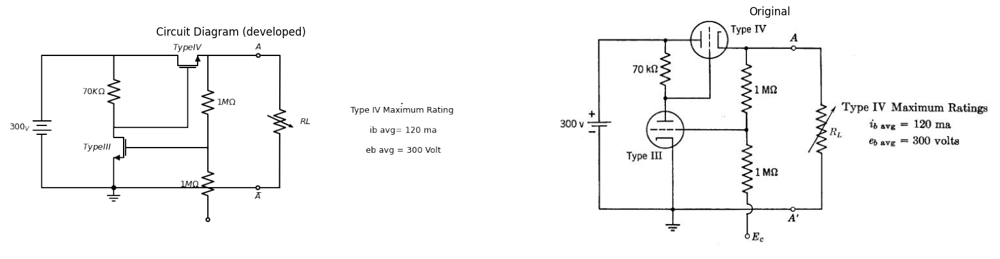

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).label('$Type III$','left'))
d += elm.Line().down(d.unit*.25).at(M1.source)
d += elm.Ground()
d += elm.Line().right(d.unit*1).at(M1.gate)
d += elm.Resistor().down().label('$1{MΩ}$','top').dot(open=True)
d += elm.Resistor().up().label('$70{KΩ}$','top').at(M1.drain)
d += elm.Line().right(d.unit*.75)
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(90).label('$Type IV$','right').reverse())
d += elm.Line().right(d.unit*1.03).at(M1.drain)
d += elm.Line().up(d.unit*.8)
d += elm.Resistor().down(d.unit*1.3).label('$1{MΩ}$','bottom').at(M2.source)
d += (E1 := elm.Battery().up().length(2).label('$300_V$','top').at((-3,-1)).reverse())
d += elm.Line().up(d.unit*.67).at(E1.end)
d += elm.Line().right(d.unit*.99)
d += elm.Line().down(d.unit*.5).at(E1.start)
d += elm.Line().right(d.unit*1).dot()
d += elm.Line().right(d.unit*2)
d +=(l1:= elm.Line().right(d.unit*.001).dot(open=True).label('$A ̅$','bottom'))
d += elm.Line().right(d.unit*.7).at(M2.source)
d += elm.Line().right(d.unit*.001).dot(open=True).label('$A$','top')
d += (l2:= elm.Line().right(d.unit*.3))
d += (l3:= elm.Line().right(d.unit*.3).at(l1.end))
d += elm.ResistorVarIEEE().down(d.unit*1.3).label('$R{L}$','bottom').endpoints(l2.end,l3.end)
d += (l5:= elm.Line().right(d.unit*.003).at((12,1)).label('Type IV Maximum Rating\n\n ib avg= 120 ma\n\n eb avg = 300 Volt','bottom'))
d.save('images/6-48.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/6-48.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p6-48.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


(a)	Determine the quiescent operating points and the bias, E c, necessary to deliver 200 volts at 70 ma to the load.

(b)	For the conditions of (a) determine the Thevenin equivalent of the circuit to the left of terminals A — A' (i.e., the circuit seen by RL) valid for small changes in load current.

(c)	For a load voltage of 200 volts, what is the maximum power output that can be obtained without exceeding the tube ratings?


## Navigation

<!--NAVIGATION-->
( Previous: [**5.1 Transistor Models and Circuits**](../Chapter.5/chapter5.ipynb)( [**TOC**](../TOC.md) | Next: [**7.1 Other Control Valves and their Circuit Models**](../chapter.7/chapter7.ipynb) )


[**This file as MS Word (docx)**](./Docs/chapter6.docx) 
